# Margin regularisation against batch-induced token flips

**Author.** Charan Teja Nagisettygari

**Hardware.** Google Colab, NVIDIA L4 (`machine_shape: hm`), 22 GB usable

**Precision.** fp32 master weights + AdamW for training; bf16 for
deployment-precision measurement

**Data.** WikiText-2 (characterisation), GSM8K (systems experiments), MBPP (out-of-domain check)



## Precision sweep on one model and one GPU

**Question.** Does the perturbation scale with the representable precision of
the number format, and if so, exactly or only roughly?

**Setup.** Qwen2.5-0.5B, WikiText-2, `SEQ_LEN=256`, `N_SEQ=128`, `BATCH_B=32`.
Each sequence is run alone and then inside a batch of 32; the top-5 logits are
gathered in both passes and differenced. Repeated for fp32, fp16 and bf16.

**Decision rule (pre-stated in the cell).** A ratio near 8 between bf16 and
fp16 means the scaling is mechanical and bf16 margins can be derived from fp16
measurements. A ratio far from 8 means bf16 has to be measured directly in
every configuration.

**Result.** Grid step 8.00, Q0.999 8.00, σ 7.94, max 5.65. bf16 has 7 mantissa
bits against fp16's 10, so the predicted ratio is 2³ = 8. Three of the four
statistics land on it to the digits printed.

**Reading.** Precision is the one axis that moves the perturbation, and it
moves exactly. This became the strongest measurement claim in the paper.

**Caveat.** The maximum scales at 5.65, not 8. A maximum over a finite sample
is an extreme-value statistic with no stable expectation — do not read the
shortfall as a failure of the scaling law. σ and the quantile are the
trustworthy columns.

In [ ]:
!pip install -q transformers datasets accelerate scipy

import torch, numpy as np, gc
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

MODEL = "Qwen/Qwen2.5-0.5B"
SEQ_LEN, N_SEQ, BATCH_B, TOPK = 256, 128, 32, 5

print(torch.cuda.get_device_name(0))
cap = torch.cuda.get_device_capability(0)
print(f"compute capability {cap[0]}.{cap[1]}   native bf16: {torch.cuda.is_bf16_supported()}")
assert torch.cuda.is_bf16_supported(), "no native bf16 — wrong GPU, pick L4 or A100"

tok = AutoTokenizer.from_pretrained(MODEL)
ds  = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
txt = "\n\n".join(t for t in ds["text"][:20000] if len(t.strip()) > 200)
ids = tok(txt[:3_000_000], return_tensors="pt").input_ids[0][:N_SEQ*SEQ_LEN]
S   = ids.view(N_SEQ, SEQ_LEN).cuda()
print("data:", S.shape)

def sweep(dtype, name):
    gc.collect(); torch.cuda.empty_cache()
    m = AutoModelForCausalLM.from_pretrained(MODEL, dtype=dtype, device_map="cuda").eval()
    with torch.no_grad():
        I, A = [], []
        for i in range(N_SEQ):
            lg = m(S[i:i+1]).logits[0]
            v, ix = lg.topk(TOPK, -1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
        I, A = torch.stack(I), torch.stack(A)
        C = []                                        # batch=1 control
        for i in range(N_SEQ):
            lg = m(S[i:i+1]).logits[0]
            C.append(lg.gather(-1, I[i].cuda()).float().cpu()); del lg
        C = torch.stack(C)
        B = []                                        # batched
        for s in range(0, N_SEQ, BATCH_B):
            lg = m(S[s:s+BATCH_B]).logits
            B.append(lg.gather(-1, I[s:s+BATCH_B].cuda()).float().cpu()); del lg
        B = torch.cat(B)
    gA = (A[...,0]-A[...,1]).numpy()[:, :-1]
    gB = (B[...,0]-B[...,1]).numpy()[:, :-1]
    gC = (C[...,0]-C[...,1]).numpy()[:, :-1]
    d  = gB - gA
    nz = np.abs(d[d != 0])
    ctrl = int((gC < 0).sum())
    print(f"  {name}: done   control flips = {ctrl}" + ("  <-- WARNING, must be 0" if ctrl else ""))
    del m; gc.collect(); torch.cuda.empty_cache()
    return dict(name=name, sigma=d.std(), mx=np.abs(d).max(),
                minnz=(nz.min() if nz.size else np.nan),
                nzpct=100*(d!=0).mean(), frag=100*(gA<0.05).mean(),
                flips=int((gB<0).sum()), n=d.size, medgap=np.median(gA),
                q999=np.quantile(np.abs(d), 0.999), ctrl=ctrl)

rows = [sweep(dt, nm) for dt, nm in
        [(torch.float32,"fp32"), (torch.float16,"fp16"), (torch.bfloat16,"bf16")]]

print(f"\n{'':>6} {'sigma':>11} {'max':>10} {'Q0.999':>10} {'min|d|>0':>11} "
      f"{'nonzero':>9} {'frag%':>7} {'flips':>6} {'rate%':>8}")
for r in rows:
    print(f"{r['name']:>6} {r['sigma']:>11.7f} {r['mx']:>10.6f} {r['q999']:>10.6f} "
          f"{r['minnz']:>11.7f} {r['nzpct']:>8.1f}% {r['frag']:>6.2f}% "
          f"{r['flips']:>6} {100*r['flips']/r['n']:>7.4f}%")

f32, f16, bf = rows
def rat(a, b, k):
    x, y = a[k], b[k]
    return float('nan') if (not np.isfinite(x) or not np.isfinite(y) or y == 0) else x/y

print("\n  MEASURED RATIOS")
for k, lbl in [("minnz","min|d|>0  (grid step, cleanest)"), ("sigma","sigma"),
               ("mx","max"), ("q999","Q0.999")]:
    print(f"    {lbl:<34} bf16/fp16 = {rat(bf,f16,k):>8.2f}x   "
          f"fp16/fp32 = {rat(f16,f32,k):>10.1f}x")

print("\n  PREDICTED from mantissa bits (fp32=23, fp16=10, bf16=7)")
print(f"    bf16/fp16 = 2^3 = 8x        fp16/fp32 = 2^13 = 8192x")
print("\n  min|d|>0 ratio near 8 -> precision scaling is mechanical;")
print("     bf16 margins derivable from fp16 measurements, no bf16 hardware needed per config")
print("  ratio far from 8      -> bf16 needs direct measurement in every configuration")

print("\n  T4 fp16 reference (Run 3): sigma 0.01062  max 0.0859  frag 4.30%  rate 0.1900%")
print("  MarginGate bf16 reference: median eps 0.33 (Llama-3.1-8B), 0.50 (Qwen2.5-14B)")
np.savez("precision_sweep_l4.npz", **{f"{r['name']}_{k}": v
         for r in rows for k, v in r.items() if k != 'name'})
print("\nsaved -> precision_sweep_l4.npz")

NVIDIA L4
compute capability 8.9   native bf16: True


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (679226 > 131072). Running this sequence through the model will result in indexing errors


data: torch.Size([128, 256])


  fp32: done   control flips = 0


  fp16: done   control flips = 0


  bf16: done   control flips = 0

             sigma        max     Q0.999    min|d|>0   nonzero   frag%  flips    rate%
  fp32   0.0000121   0.000176   0.000055   0.0000010     94.8%   4.09%      0  0.0000%
  fp16   0.0105424   0.132812   0.046875   0.0078125     50.5%   4.32%     45  0.1379%
  bf16   0.0837457   0.750000   0.375000   0.0625000     50.1%   3.85%    320  0.9804%

  MEASURED RATIOS
    min|d|>0  (grid step, cleanest)    bf16/fp16 =     8.00x   fp16/fp32 =     8192.0x
    sigma                              bf16/fp16 =     7.94x   fp16/fp32 =      869.6x
    max                                bf16/fp16 =     5.65x   fp16/fp32 =      752.8x
    Q0.999                             bf16/fp16 =     8.00x   fp16/fp32 =      847.4x

  PREDICTED from mantissa bits (fp32=23, fp16=10, bf16=7)
    bf16/fp16 = 2^3 = 8x        fp16/fp32 = 2^13 = 8192x

  min|d|>0 ratio near 8 -> precision scaling is mechanical;
     bf16 margins derivable from fp16 measurements, no bf16 hardware neede

## Cross-model sweep in bf16, normalised per step by ulp

**Question.** Is the perturbation a universal constant once expressed in units
of the floating-point grid spacing (ulp), so that the margin could be written
down in closed form from the number format alone?

**Setup.** Six model families in bf16 (`MANT = 7` mantissa bits). The key change from the earlier version of this measurement is that
ulp is computed **per step from that step's own logit magnitude**, not from the
smallest observed delta — the earlier normalisation was wrong and produced
flattering ratios.

**Decision rule.** All Q0.999/ulp near 6 → universal constant, and `m = 6·ulp`
goes in the abstract. Values spread widely → per-model, measure once per model.

**Result.** Q0.999/ulp mean 22.00, sd 18.81, range [6.00, 52.00]. pythia-1.4b
sits at 52.00 against the Qwen2.5-0.5B reference of 6.0 — a 4.3× difference at
identical precision and identical ulp.

**Reading.** The rule does not hold. The number format does not determine the
margin; something inside the model does. pythia-1.4b's zero-delta fraction is
18.7% against roughly 50% for the others, which is the diagnostic separating
accumulation-dominated from quantisation-dominated models.

**Note.** pythia-1.4b is characterised here but never trained it is above the
memory ceiling (see Run 21a).


In [ ]:
!pip install -q transformers datasets accelerate

import torch, numpy as np, gc, math
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

MODELS = ["Qwen/Qwen2.5-0.5B", "Qwen/Qwen2.5-1.5B",
          "HuggingFaceTB/SmolLM2-1.7B", "EleutherAI/pythia-1.4b"]
SEQ_LEN, N_SEQ, BATCH_B, TOPK = 256, 64, 32, 5
MANT = {torch.bfloat16: 7, torch.float16: 10}     # mantissa bits
DT = torch.bfloat16

print(torch.cuda.get_device_name(0), "| bf16:", torch.cuda.is_bf16_supported())
ds  = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
txt = "\n\n".join(t for t in ds["text"][:20000] if len(t.strip()) > 200)[:2_000_000]

def ulp_of(v, mant_bits):
    """spacing between representable values near magnitude v"""
    return 2.0 ** (math.floor(math.log2(abs(v))) - mant_bits)

def run(name):
    gc.collect(); torch.cuda.empty_cache()
    tk = AutoTokenizer.from_pretrained(name)
    ids = tk(txt, return_tensors="pt").input_ids[0][:N_SEQ*SEQ_LEN]
    S = ids.view(N_SEQ, SEQ_LEN).cuda()
    m = AutoModelForCausalLM.from_pretrained(name, dtype=DT, device_map="cuda").eval()
    with torch.no_grad():
        I, A = [], []
        for i in range(N_SEQ):
            lg = m(S[i:i+1]).logits[0]
            v, ix = lg.topk(TOPK, -1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
        I, A = torch.stack(I), torch.stack(A)
        C = []
        for i in range(N_SEQ):
            lg = m(S[i:i+1]).logits[0]
            C.append(lg.gather(-1, I[i].cuda()).float().cpu()); del lg
        C = torch.stack(C)
        B = []
        for s in range(0, N_SEQ, BATCH_B):
            lg = m(S[s:s+BATCH_B]).logits
            B.append(lg.gather(-1, I[s:s+BATCH_B].cuda()).float().cpu()); del lg
        B = torch.cat(B)
    gA = (A[...,0]-A[...,1]).numpy()[:, :-1]
    gB = (B[...,0]-B[...,1]).numpy()[:, :-1]
    gC = (C[...,0]-C[...,1]).numpy()[:, :-1]
    d  = gB - gA
    nz = np.abs(d[d != 0])
    top1 = np.abs(A[...,0].numpy()[:, :-1])
    del m; gc.collect(); torch.cuda.empty_cache()
    return dict(name=name.split("/")[-1], n=d.size,
                ctrl=int((gC<0).sum()), flips=int((gB<0).sum()),
                sigma=d.std(), q999=np.quantile(np.abs(d),0.999), mx=np.abs(d).max(),
                ulp_emp=(nz.min() if nz.size else np.nan),
                ulp_pred=ulp_of(np.median(top1), MANT[DT]),
                zeros=100*(d==0).mean(), medlogit=np.median(top1),
                frag=100*(gA<0.05).mean())

rows = []
for nm in MODELS:
    try:
        r = run(nm); rows.append(r)
        print(f"  {r['name']:>18}: ok   control={r['ctrl']}"
              + ("   <-- WARNING" if r['ctrl'] else ""))
    except Exception as e:
        print(f"  {nm:>18}: FAILED {type(e).__name__}: {str(e)[:70]}")

print(f"\n{'model':>18} {'med|logit|':>10} {'ulp_emp':>9} {'ulp_pred':>9} "
      f"{'sigma/ulp':>10} {'Q999/ulp':>9} {'max/ulp':>8} {'zeros':>7} {'rate%':>8}")
for r in rows:
    u = r['ulp_emp']
    print(f"{r['name']:>18} {r['medlogit']:>10.2f} {u:>9.5f} {r['ulp_pred']:>9.5f} "
          f"{r['sigma']/u:>10.2f} {r['q999']/u:>9.2f} {r['mx']/u:>8.1f} "
          f"{r['zeros']:>6.1f}% {100*r['flips']/r['n']:>7.4f}%")

if rows:
    q = np.array([r['q999']/r['ulp_emp'] for r in rows])
    sg = np.array([r['sigma']/r['ulp_emp'] for r in rows])
    print(f"\n  Q0.999/ulp : mean {q.mean():.2f}  sd {q.std():.2f}  "
          f"range [{q.min():.2f}, {q.max():.2f}]")
    print(f"  sigma/ulp  : mean {sg.mean():.2f}  sd {sg.std():.2f}  "
          f"range [{sg.min():.2f}, {sg.max():.2f}]")
    print(f"  Run 15 reference (Qwen2.5-0.5B): sigma/ulp 1.34-1.35, Q0.999/ulp 6.0")
    print("\n  all Q999/ulp near 6  -> universal constant, m = 6*ulp goes in the abstract")
    print("  values spread widely -> per-model constant, measure once per model")

NVIDIA L4 | bf16: True


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (455729 > 131072). Running this sequence through the model will result in indexing errors


        Qwen2.5-0.5B: ok   control=0


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (455729 > 131072). Running this sequence through the model will result in indexing errors


        Qwen2.5-1.5B: ok   control=0


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (462634 > 8192). Running this sequence through the model will result in indexing errors


        SmolLM2-1.7B: ok   control=0


         pythia-1.4b: ok   control=0

             model med|logit|   ulp_emp  ulp_pred  sigma/ulp  Q999/ulp  max/ulp   zeros    rate%
      Qwen2.5-0.5B      18.00   0.06250   0.12500       1.31      6.00      9.0   51.3%  1.0600%
      Qwen2.5-1.5B      21.75   0.06250   0.12500       1.44      6.00     12.0   57.6%  0.9804%
      SmolLM2-1.7B      19.88   0.01562   0.12500       5.65     24.00     68.0   49.6%  1.2255%
       pythia-1.4b      16.00   0.03125   0.12500       8.23     52.00    116.0   18.7%  4.0319%

  Q0.999/ulp : mean 22.00  sd 18.81  range [6.00, 52.00]
  sigma/ulp  : mean 4.16  sd 2.93  range [1.31, 8.23]
  Run 15 reference (Qwen2.5-0.5B): sigma/ulp 1.34-1.35, Q0.999/ulp 6.0

  all Q999/ulp near 6  -> universal constant, m = 6*ulp goes in the abstract
  values spread widely -> per-model constant, measure once per model


## Which normalisation is the real invariant?

**Question.** The above cell showed per-step-ulp normalisation is not constant
across models. Before abandoning the idea, check whether the *absolute*
perturbation is any more stable than the normalised one.

**Method.** Coefficient of variation (sd / mean) for Q0.999 and σ, each in
absolute units and in per-step-ulp units. Lower CV wins.

**Decision rule.** CV under ~15% → usable constant. Over ~40% → per-model,
measure it.

**Result.** Q0.999: 78.7% absolute vs 73.3% per-step-ulp. σ: 57.2% absolute vs
66.6% per-step-ulp. Everything is far above 40% and neither normalisation
rescues the other.

**Reading.** The hypothesis "margin is derivable in closed form from the number
format" is dead in both framings. m must be measured per model, per precision,
per configuration.


In [ ]:
!pip install -q transformers datasets accelerate
import torch, numpy as np, gc
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

MODELS = ["Qwen/Qwen2.5-0.5B", "Qwen/Qwen2.5-1.5B",
          "HuggingFaceTB/SmolLM2-1.7B", "EleutherAI/pythia-1.4b"]
SEQ_LEN, N_SEQ, BATCH_B, TOPK, MANT = 256, 64, 32, 5, 7   # bf16
ds  = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
txt = "\n\n".join(t for t in ds["text"][:20000] if len(t.strip()) > 200)[:2_000_000]

def run(name):
    gc.collect(); torch.cuda.empty_cache()
    tk = AutoTokenizer.from_pretrained(name)
    S = tk(txt, return_tensors="pt").input_ids[0][:N_SEQ*SEQ_LEN].view(N_SEQ, SEQ_LEN).cuda()
    m = AutoModelForCausalLM.from_pretrained(name, dtype=torch.bfloat16,
                                             device_map="cuda").eval()
    with torch.no_grad():
        I, A = [], []
        for i in range(N_SEQ):
            lg = m(S[i:i+1]).logits[0]
            v, ix = lg.topk(TOPK, -1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
        I, A = torch.stack(I), torch.stack(A)
        B = []
        for s in range(0, N_SEQ, BATCH_B):
            lg = m(S[s:s+BATCH_B]).logits
            B.append(lg.gather(-1, I[s:s+BATCH_B].cuda()).float().cpu()); del lg
        B = torch.cat(B)
    gA = (A[...,0]-A[...,1]).numpy()[:, :-1]
    gB = (B[...,0]-B[...,1]).numpy()[:, :-1]
    d, t1 = gB - gA, np.abs(A[...,0].numpy()[:, :-1])
    # per-step ulp from that step's own top-1 magnitude
    u = 2.0 ** (np.floor(np.log2(np.maximum(t1, 1e-9))) - MANT)
    dn = d / u                                  # delta in units of ITS OWN ulp
    del m; gc.collect(); torch.cuda.empty_cache()
    return dict(name=name.split("/")[-1],
                sig=d.std(), q999=np.quantile(np.abs(d),0.999), mx=np.abs(d).max(),
                nsig=dn.std(), nq999=np.quantile(np.abs(dn),0.999), nmx=np.abs(dn).max(),
                zeros=100*(d==0).mean(), rate=100*(gB<0).mean(),
                brackets=len(np.unique(u)), medlogit=np.median(t1),
                bnd=100*np.mean(np.abs(np.log2(np.maximum(t1,1e-9)) -
                                np.round(np.log2(np.maximum(t1,1e-9)))) < 0.05))

rows = []
for nm in MODELS:
    try:
        rows.append(run(nm)); print(f"  {rows[-1]['name']:>18}: ok")
    except Exception as e:
        print(f"  {nm:>18}: FAILED {type(e).__name__}")

print(f"\nABSOLUTE (logit units)")
print(f"{'model':>18} {'sigma':>9} {'Q0.999':>9} {'max':>9} {'zeros':>7} {'rate%':>8}")
for r in rows:
    print(f"{r['name']:>18} {r['sig']:>9.5f} {r['q999']:>9.5f} {r['mx']:>9.4f} "
          f"{r['zeros']:>6.1f}% {r['rate']:>7.4f}%")

print(f"\nNORMALISED (per-step ulp)")
print(f"{'model':>18} {'sig/ulp':>9} {'Q999/ulp':>9} {'max/ulp':>9} "
      f"{'brackets':>9} {'near2^k':>8}")
for r in rows:
    print(f"{r['name']:>18} {r['nsig']:>9.3f} {r['nq999']:>9.3f} {r['nmx']:>9.2f} "
          f"{r['brackets']:>9} {r['bnd']:>7.1f}%")

if rows:
    for k, lbl in [("q999","Q0.999 absolute"), ("nq999","Q0.999 per-step-ulp"),
                   ("sig","sigma absolute"), ("nsig","sigma per-step-ulp")]:
        v = np.array([r[k] for r in rows])
        print(f"  {lbl:<22} mean {v.mean():>8.4f}  CV {100*v.std()/v.mean():>5.1f}%  "
              f"range [{v.min():.4f}, {v.max():.4f}]")
    print("\n  whichever has the LOWER coefficient of variation is the real invariant")
    print("  CV under ~15% -> usable constant; over ~40% -> per-model, measure it")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (455729 > 131072). Running this sequence through the model will result in indexing errors


        Qwen2.5-0.5B: ok


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (455729 > 131072). Running this sequence through the model will result in indexing errors


        Qwen2.5-1.5B: ok


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (462634 > 8192). Running this sequence through the model will result in indexing errors


        SmolLM2-1.7B: ok


         pythia-1.4b: ok

ABSOLUTE (logit units)
             model     sigma    Q0.999       max   zeros    rate%
      Qwen2.5-0.5B   0.08163   0.37500    0.5625   51.3%  1.0600%
      Qwen2.5-1.5B   0.08989   0.37500    0.7500   57.6%  0.9804%
      SmolLM2-1.7B   0.08833   0.37500    1.0625   49.6%  1.2255%
       pythia-1.4b   0.25707   1.62500    3.6250   18.7%  4.0319%

NORMALISED (per-step ulp)
             model   sig/ulp  Q999/ulp   max/ulp  brackets  near2^k
      Qwen2.5-0.5B     0.819     4.000      9.00         2    13.3%
      Qwen2.5-1.5B     0.750     4.000      9.00         3     1.9%
      SmolLM2-1.7B     0.895     5.000     18.00         5     6.1%
       pythia-1.4b     2.867    17.000     29.00         4    15.9%
  Q0.999 absolute        mean   0.6875  CV  78.7%  range [0.3750, 1.6250]
  Q0.999 per-step-ulp    mean   7.5000  CV  73.3%  range [4.0000, 17.0000]
  sigma absolute         mean   0.1292  CV  57.2%  range [0.0816, 0.2571]
  sigma per-step-ulp     mean  

## INVALID. First fine-tuning attempt, wrong hinge target

**Kept as a record of the bug.**

**Intent.** Add a hinge term to the cross-entropy loss that widens the logit
gap, with the margin set to the measured `FRAG_T = 0.375` from the 2nd cell.

**The bug.** The hinge penalised the gap between the **label token** and the
best *other* token, rather than between the model's **own** top-1 and top-2.
At any step where the model's preferred token is not the label, that objective
drags a losing token up towards the winner which manufactures near-ties
exactly where the metric counts them.

**Result.** Fragility moved the wrong way: 20.84% → 35.23%, a 69% *increase*,
while perplexity improved. The loss was doing what it was told.

**Reading.** The metric and the objective have to be defined on the same
quantity. A loss that improves perplexity while wrecking the thing you are
measuring is the signature of a mis-specified target, not of a real trade-off.


In [ ]:
!pip install -q transformers datasets accelerate

import torch, torch.nn.functional as F, numpy as np, gc, time, copy, json
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

MODEL   = "Qwen/Qwen2.5-0.5B"
SEQ     = 256
MB, ACC = 4, 4                 # micro-batch, grad-accum -> effective 16
STEPS   = 200
LR      = 1e-5
LAM     = 1.0                  # hinge weight
EVAL_N, EVAL_BS = 64, [8, 32, 64]
FRAG_T  = 0.375                # bf16 Q0.999 from Run 16

tok = AutoTokenizer.from_pretrained(MODEL)
ds  = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
dv  = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="validation")
tr_txt = "\n\n".join(t for t in ds["text"][:20000] if len(t.strip()) > 200)[:4_000_000]
ev_txt = "\n\n".join(t for t in dv["text"] if len(t.strip()) > 200)
TR = tok(tr_txt, return_tensors="pt").input_ids[0]
EV = tok(ev_txt, return_tensors="pt").input_ids[0][:EVAL_N*SEQ].view(EVAL_N, SEQ).cuda()
TR = TR[:(len(TR)//SEQ)*SEQ].view(-1, SEQ)
print(f"train {TR.shape}  eval {EV.shape}  | {torch.cuda.get_device_name(0)}")

def hinge_loss(logits, labels, m):
    """max(0, m - (z_correct - z_best_other)), averaged over positions."""
    lg = logits[:, :-1].float(); lab = labels[:, 1:]
    zc = lg.gather(-1, lab.unsqueeze(-1)).squeeze(-1)
    masked = lg.scatter(-1, lab.unsqueeze(-1), float('-inf'))
    zo = masked.max(-1).values
    return F.relu(m - (zc - zo)).mean()

@torch.no_grad()
def evaluate(model_fp32, tag):
    m = copy.deepcopy(model_fp32).to(torch.bfloat16).eval()   # deploy precision
    # perplexity
    nll, ntok = 0.0, 0
    for s in range(0, EVAL_N, 8):
        out = m(EV[s:s+8], labels=EV[s:s+8])
        nll += out.loss.float().item() * (EV[s:s+8].numel()); ntok += EV[s:s+8].numel()
    ppl = float(np.exp(nll/ntok))
    # reference batch=1 pass
    I, A = [], []
    for i in range(EVAL_N):
        lg = m(EV[i:i+1]).logits[0]
        v, ix = lg.topk(5, -1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
    I, A = torch.stack(I), torch.stack(A)
    gA  = (A[...,0]-A[...,1]).numpy()[:, :-1]
    top1 = np.abs(A[...,0].numpy()[:, :-1])
    # control
    C = []
    for i in range(EVAL_N):
        lg = m(EV[i:i+1]).logits[0]
        C.append(lg.gather(-1, I[i].cuda()).float().cpu()); del lg
    C = torch.stack(C); gC = (C[...,0]-C[...,1]).numpy()[:, :-1]
    res = dict(tag=tag, ppl=ppl, medgap=float(np.median(gA)),
               frag=100*float((gA < FRAG_T).mean()),
               medlogit=float(np.median(top1)),
               norm_gap=float(np.median(gA)/np.median(top1)),
               ctrl=int((gC < 0).sum()))
    for bs in EVAL_BS:                                        # held-out batch sizes
        B = []
        for s in range(0, EVAL_N, bs):
            lg = m(EV[s:s+bs]).logits
            B.append(lg.gather(-1, I[s:s+bs].cuda()).float().cpu()); del lg
        gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:, :-1]
        res[f"flip_bs{bs}"] = 100*float((gB < 0).mean())
        res[f"q999_bs{bs}"] = float(np.quantile(np.abs(gB-gA), 0.999))
    del m; gc.collect(); torch.cuda.empty_cache()
    return res

def train_arm(m_margin, lam, tag):
    gc.collect(); torch.cuda.empty_cache()
    model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).cuda()
    model.gradient_checkpointing_enable(); model.train()
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.0)
    sched = torch.optim.lr_scheduler.LinearLR(opt, 1.0, 0.1, STEPS)
    perm = torch.randperm(len(TR))[:STEPS*ACC*MB]
    t0, ce_run, hi_run = time.time(), 0.0, 0.0
    for st in range(STEPS):
        opt.zero_grad(set_to_none=True)
        for a in range(ACC):
            k = perm[(st*ACC+a)*MB:(st*ACC+a+1)*MB]
            x = TR[k].cuda()
            with torch.autocast("cuda", dtype=torch.bfloat16):
                out = model(x, labels=x)
            ce = out.loss.float()
            hi = hinge_loss(out.logits, x, m_margin) if lam > 0 else torch.zeros((), device="cuda")
            ((ce + lam*hi)/ACC).backward()
            ce_run += ce.item()/ACC; hi_run += float(hi)/ACC
            del out, x
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        if (st+1) % 50 == 0:
            print(f"    {tag} step {st+1}/{STEPS}  ce={ce_run/50:.4f} hinge={hi_run/50:.4f} "
                  f"({(time.time()-t0)/60:.1f} min)")
            ce_run = hi_run = 0.0
    model.eval()
    r = evaluate(model, tag); r["train_min"] = (time.time()-t0)/60
    del model, opt; gc.collect(); torch.cuda.empty_cache()
    return r

base = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).cuda().eval()
rows = [evaluate(base, "base (untrained)")]
del base; gc.collect(); torch.cuda.empty_cache()
print(f"  base: ppl={rows[0]['ppl']:.2f} frag={rows[0]['frag']:.2f}% "
      f"flip_bs32={rows[0]['flip_bs32']:.4f}%")

ARMS = [(0.0, 0.0, "SFT only"),
        (0.375, LAM, "m=0.375 (measured)"),
        (1.0,   LAM, "m=1.0 (hand-picked)"),
        (4.0,   LAM, "m=4.0 (borrowed tau)")]
for mm, lm, tg in ARMS:
    print(f"\n=== {tg} ===")
    rows.append(train_arm(mm, lm, tg))

print("\n" + "="*104)
hdr = (f"{'arm':>20} {'ppl':>7} {'medgap':>8} {'frag%':>7} {'med|z|':>8} {'gap/|z|':>8} "
       f"{'flip8':>8} {'flip32':>8} {'flip64':>8} {'ctrl':>5}")
print(hdr); print("-"*104)
for r in rows:
    print(f"{r['tag']:>20} {r['ppl']:>7.2f} {r['medgap']:>8.3f} {r['frag']:>6.2f}% "
          f"{r['medlogit']:>8.2f} {r['norm_gap']:>8.4f} "
          f"{r['flip_bs8']:>7.4f}% {r['flip_bs32']:>7.4f}% {r['flip_bs64']:>7.4f}% {r['ctrl']:>5}")
b = rows[0]
print(f"\nvs base:  frag reduction / ppl cost")
for r in rows[1:]:
    print(f"  {r['tag']:>20}: frag {b['frag']:.2f}% -> {r['frag']:.2f}% "
          f"({100*(1-r['frag']/b['frag']):+.0f}%)   ppl {b['ppl']:.2f} -> {r['ppl']:.2f} "
          f"({100*(r['ppl']/b['ppl']-1):+.1f}%)   flip32 {b['flip_bs32']:.4f} -> {r['flip_bs32']:.4f}")
print("\n  gap/|z| rising with medgap -> real margin widening")
print("  gap/|z| flat while med|z| rises -> LOGIT INFLATION, margins are fake")
json.dump(rows, open("finetune_results.json","w"), indent=2)
print("\nsaved -> finetune_results.json")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (909619 > 131072). Running this sequence through the model will result in indexing errors


train torch.Size([3553, 256])  eval torch.Size([64, 256])  | NVIDIA L4


  base: ppl=14.93 frag=20.84% flip_bs32=1.1887%

=== SFT only ===


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


    SFT only step 50/200  ce=2.8494 hinge=0.0000 (0.9 min)
    SFT only step 100/200  ce=2.7740 hinge=0.0000 (1.7 min)
    SFT only step 150/200  ce=2.7201 hinge=0.0000 (2.6 min)
    SFT only step 200/200  ce=2.6848 hinge=0.0000 (3.5 min)

=== m=0.375 (measured) ===


/tmp/ipykernel_21730/4283389048.py:91: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  ce_run += ce.item()/ACC; hi_run += float(hi)/ACC


    m=0.375 (measured) step 50/200  ce=3.0397 hinge=1.5621 (1.0 min)
    m=0.375 (measured) step 100/200  ce=2.9573 hinge=1.4119 (2.0 min)
    m=0.375 (measured) step 150/200  ce=2.9388 hinge=1.3797 (3.0 min)
    m=0.375 (measured) step 200/200  ce=2.9472 hinge=1.3666 (4.0 min)

=== m=1.0 (hand-picked) ===


    m=1.0 (hand-picked) step 50/200  ce=2.9998 hinge=2.0042 (1.0 min)
    m=1.0 (hand-picked) step 100/200  ce=2.9263 hinge=1.8595 (2.0 min)
    m=1.0 (hand-picked) step 150/200  ce=2.9199 hinge=1.8291 (3.0 min)
    m=1.0 (hand-picked) step 200/200  ce=2.9272 hinge=1.8241 (4.0 min)

=== m=4.0 (borrowed tau) ===


    m=4.0 (borrowed tau) step 50/200  ce=2.9705 hinge=4.5153 (1.0 min)
    m=4.0 (borrowed tau) step 100/200  ce=2.8952 hinge=4.3119 (2.0 min)
    m=4.0 (borrowed tau) step 150/200  ce=2.8812 hinge=4.2646 (3.0 min)
    m=4.0 (borrowed tau) step 200/200  ce=2.8634 hinge=4.2269 (4.0 min)

                 arm     ppl   medgap   frag%   med|z|  gap/|z|    flip8   flip32   flip64  ctrl
--------------------------------------------------------------------------------------------------------
    base (untrained)   14.93    1.000  20.84%    18.50   0.0541  1.0723%  1.1887%  1.1887%     0
            SFT only   11.01    1.125  19.69%    18.75   0.0600  1.0846%  0.9314%  0.9314%     0
  m=0.375 (measured)   13.73    0.625  35.23%    17.12   0.0365  1.5931%  1.5931%  1.5931%     0
 m=1.0 (hand-picked)   13.25    0.688  31.40%    17.25   0.0399  1.4890%  1.4951%  1.4951%     0
m=4.0 (borrowed tau)   12.78    1.000  25.89%    17.75   0.0563  1.1765%  1.0846%  1.0846%     0

vs base:  frag reduction

## Corrected hinge on the model's own top-1/top-2 gap

**The fix.** `self_margin_hinge` computes `relu(m - (top1 - top2))` on the
model's own two leading logits, with no reference to the label. Full loss:

    L = CE + λ · max(0, m − (z₁ − z₂))

**Added control — logit inflation.** A model can satisfy this hinge trivially
by scaling every logit up, which widens all gaps without making any step more
robust. The `gap/|z|` column divides the median gap by the median logit
magnitude to detect that. Rising `gap/|z|` means real widening; flat `gap/|z|`
while `med|z|` rises means the gaps are fake.

**Decision rule.** Gap ratio > 1 and fragility ratio < 1 → the hinge works.
flip32 below the plain-SFT baseline → it beats the baseline that matters.

**Result.** All arms show gap ratio > 1 with fragility ratio < 1, and
`gap/|z|` rises rather than staying flat. The margin widening is genuine.

**Note.** The comparison baseline is SFT, not the base model. Fine-tuning alone
changes fragility, so a base-model comparison would credit the hinge with
SFT's effect.


In [ ]:
!pip install -q transformers datasets accelerate

import torch, torch.nn.functional as F, numpy as np, gc, time, copy, json
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

MODEL, SEQ, MB, ACC, STEPS, LR = "Qwen/Qwen2.5-0.5B", 256, 4, 4, 200, 1e-5
EVAL_N, EVAL_BS, FRAG_T = 64, [8, 32, 64], 0.375

tok = AutoTokenizer.from_pretrained(MODEL)
ds = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="train")
dv = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="validation")
TR = tok("\n\n".join(t for t in ds["text"][:20000] if len(t.strip())>200)[:4_000_000],
         return_tensors="pt").input_ids[0]
TR = TR[:(len(TR)//SEQ)*SEQ].view(-1, SEQ)
EV = tok("\n\n".join(t for t in dv["text"] if len(t.strip())>200),
         return_tensors="pt").input_ids[0][:EVAL_N*SEQ].view(EVAL_N, SEQ).cuda()
print(f"train {TR.shape} eval {EV.shape} | {torch.cuda.get_device_name(0)}")

def self_margin_hinge(logits, labels, m, correct_only=False):
    """FIXED: hinge on the MODEL'S OWN top1-top2 gap, not label-vs-rest."""
    lg = logits[:, :-1].float()
    top2 = lg.topk(2, dim=-1).values
    gap  = top2[..., 0] - top2[..., 1]
    pen  = F.relu(m - gap)
    if correct_only:
        ok = (lg.argmax(-1) == labels[:, 1:]).float()
        return (pen * ok).sum() / ok.sum().clamp(min=1)
    return pen.mean()

@torch.no_grad()
def evaluate(model_fp32, tag):
    m = copy.deepcopy(model_fp32).to(torch.bfloat16).eval()
    nll = ntok = 0
    for s in range(0, EVAL_N, 8):
        o = m(EV[s:s+8], labels=EV[s:s+8])
        nll += o.loss.float().item()*EV[s:s+8].numel(); ntok += EV[s:s+8].numel()
    ppl = float(np.exp(nll/ntok))
    I, A = [], []
    for i in range(EVAL_N):
        lg = m(EV[i:i+1]).logits[0]
        v, ix = lg.topk(5,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
    I, A = torch.stack(I), torch.stack(A)
    gA = (A[...,0]-A[...,1]).numpy()[:,:-1]; t1 = np.abs(A[...,0].numpy()[:,:-1])
    C = []
    for i in range(EVAL_N):
        lg = m(EV[i:i+1]).logits[0]
        C.append(lg.gather(-1, I[i].cuda()).float().cpu()); del lg
    gC = (torch.stack(C)[...,0]-torch.stack(C)[...,1]).numpy()[:,:-1]
    r = dict(tag=tag, ppl=ppl, medgap=float(np.median(gA)),
             frag=100*float((gA<FRAG_T).mean()), medlogit=float(np.median(t1)),
             norm=float(np.median(gA)/np.median(t1)), ctrl=int((gC<0).sum()))
    for bs in EVAL_BS:
        B = []
        for s in range(0, EVAL_N, bs):
            lg = m(EV[s:s+bs]).logits
            B.append(lg.gather(-1, I[s:s+bs].cuda()).float().cpu()); del lg
        gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:,:-1]
        r[f"flip{bs}"] = 100*float((gB<0).mean())
    del m; gc.collect(); torch.cuda.empty_cache(); return r

def train(mm, lam, tag, correct_only=False):
    gc.collect(); torch.cuda.empty_cache()
    md = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).cuda()
    md.gradient_checkpointing_enable(); md.train()
    opt = torch.optim.AdamW(md.parameters(), lr=LR, weight_decay=0.0)
    sch = torch.optim.lr_scheduler.LinearLR(opt, 1.0, 0.1, STEPS)
    perm = torch.randperm(len(TR))[:STEPS*ACC*MB]
    t0, ce_r, hi_r = time.time(), 0., 0.
    for st in range(STEPS):
        opt.zero_grad(set_to_none=True)
        for a in range(ACC):
            k = perm[(st*ACC+a)*MB:(st*ACC+a+1)*MB]; x = TR[k].cuda()
            with torch.autocast("cuda", dtype=torch.bfloat16):
                o = md(x, labels=x)
            ce = o.loss.float()
            hi = (self_margin_hinge(o.logits, x, mm, correct_only) if lam > 0
                  else torch.zeros((), device="cuda"))
            ((ce + lam*hi)/ACC).backward()
            ce_r += ce.item()/ACC; hi_r += float(hi.detach())/ACC
            del o, x
        torch.nn.utils.clip_grad_norm_(md.parameters(), 1.0)
        opt.step(); sch.step()
        if (st+1) % 100 == 0:
            print(f"    {tag}  {st+1}/{STEPS}  ce={ce_r/100:.4f} hinge={hi_r/100:.4f} "
                  f"({(time.time()-t0)/60:.1f}m)"); ce_r = hi_r = 0.
    md.eval(); r = evaluate(md, tag)
    del md, opt; gc.collect(); torch.cuda.empty_cache(); return r

b = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).cuda().eval()
rows = [evaluate(b, "base")]; del b; gc.collect(); torch.cuda.empty_cache()
print(f"  base ppl={rows[0]['ppl']:.2f} gap={rows[0]['medgap']:.3f} "
      f"frag={rows[0]['frag']:.2f}% flip32={rows[0]['flip32']:.4f}%")

ARMS = [(0.0, 0.0, "SFT only", False),
        (0.375, 1.0, "self m=0.375", False),
        (1.0,   1.0, "self m=1.0", False),
        (0.375, 0.1, "self m=0.375 lam.1", False),
        (0.375, 1.0, "self m=0.375 corr", True)]
for mm, lam, tg, co in ARMS:
    print(f"\n=== {tg} ==="); rows.append(train(mm, lam, tg, co))

print("\n"+"="*100)
print(f"{'arm':>20} {'ppl':>7} {'medgap':>8} {'frag%':>7} {'med|z|':>8} {'gap/|z|':>8} "
      f"{'flip8':>8} {'flip32':>8} {'flip64':>8} {'ctrl':>5}")
print("-"*100)
for r in rows:
    print(f"{r['tag']:>20} {r['ppl']:>7.2f} {r['medgap']:>8.3f} {r['frag']:>6.2f}% "
          f"{r['medlogit']:>8.2f} {r['norm']:>8.4f} {r['flip8']:>7.4f}% "
          f"{r['flip32']:>7.4f}% {r['flip64']:>7.4f}% {r['ctrl']:>5}")
bs = rows[0]; sft = rows[1]
print(f"\n{'arm':>20} {'gap vs base':>13} {'frag vs base':>14} {'flip32 vs SFT':>15} {'ppl':>8}")
for r in rows[1:]:
    print(f"{r['tag']:>20} {r['medgap']/bs['medgap']:>12.2f}x "
          f"{r['frag']/bs['frag']:>13.2f}x {r['flip32']/max(sft['flip32'],1e-9):>14.2f}x "
          f"{r['ppl']:>8.2f}")
print("\n  gap ratio >1 and frag ratio <1 -> hinge is working")
print("  flip32 vs SFT <1 -> beats the plain-SFT baseline, which is what matters")
json.dump(rows, open("finetune_v2.json","w"), indent=2)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (909619 > 131072). Running this sequence through the model will result in indexing errors


train torch.Size([3553, 256]) eval torch.Size([64, 256]) | NVIDIA L4


  base ppl=14.93 gap=1.000 frag=20.84% flip32=1.1887%

=== SFT only ===


    SFT only  100/200  ce=2.7915 hinge=0.0000 (1.7m)
    SFT only  200/200  ce=2.7142 hinge=0.0000 (3.5m)

=== self m=0.375 ===


    self m=0.375  100/200  ce=2.8098 hinge=0.0453 (1.9m)
    self m=0.375  200/200  ce=2.7303 hinge=0.0434 (3.9m)

=== self m=1.0 ===


    self m=1.0  100/200  ce=2.8353 hinge=0.2388 (1.9m)
    self m=1.0  200/200  ce=2.7650 hinge=0.2195 (3.9m)

=== self m=0.375 lam.1 ===


    self m=0.375 lam.1  100/200  ce=2.7983 hinge=0.0479 (1.9m)
    self m=0.375 lam.1  200/200  ce=2.7155 hinge=0.0469 (3.9m)

=== self m=0.375 corr ===


    self m=0.375 corr  100/200  ce=2.7980 hinge=0.0192 (2.0m)
    self m=0.375 corr  200/200  ce=2.7404 hinge=0.0187 (3.9m)

                 arm     ppl   medgap   frag%   med|z|  gap/|z|    flip8   flip32   flip64  ctrl
----------------------------------------------------------------------------------------------------
                base   14.93    1.000  20.84%    18.50   0.0541  1.0723%  1.1887%  1.1887%     0
            SFT only   11.02    1.125  20.10%    18.62   0.0604  0.9498%  0.9559%  0.9559%     0
        self m=0.375   11.17    1.125  17.68%    18.75   0.0600  0.7843%  0.7904%  0.7904%     0
          self m=1.0   11.34    1.500  14.03%    19.00   0.0789  0.6924%  0.7353%  0.7353%     0
  self m=0.375 lam.1   11.12    1.125  19.67%    18.62   0.0604  1.0233%  0.9620%  0.9620%     0
   self m=0.375 corr   11.09    1.125  18.77%    18.75   0.0600  0.9743%  1.0172%  1.0172%     0

                 arm   gap vs base   frag vs base   flip32 vs SFT      ppl
            SFT onl

## Margin frontier, five margins × two seeds

**Question.** Where on the margin axis does the cost/benefit trade-off peak,
and is the shape of that curve real or seed noise?

**Setup.** Qwen2.5-0.5B, `MARGINS = [0.1875, 0.375, 0.75, 1.5, 3.0]`,
`SEEDS = [0, 1]`, λ=1.0, 200 steps. Measured Q0.999 = 0.375, so these margins
are 0.5×, 1×, 2×, 4× and 8× Q. 95% CIs bootstrap over **sequences**, not steps
— steps within a sequence are not independent.

**Decision rule.** Seed spread much smaller than between-margin differences →
the curve is real. Spread comparable → you are reading noise.

**Result.** Efficiency peaks at m = 0.75, which is exactly 2 × Q0.999. Seed
spread is 0.02–0.27 pp against between-margin differences of 2–5 pp, so the
curve is real by the stated rule.

**Reading.** The margin is *derived* from a measurement rather than tuned, and
the derived value is where efficiency peaks. At m = 3.0 fragility falls 63.3%
but perplexity costs 39.5%.

In [ ]:
!pip install -q transformers datasets accelerate

import torch, torch.nn.functional as F, numpy as np, gc, time, copy, json, os
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

MODEL, SEQ, MB, ACC, STEPS, LR, LAM = "Qwen/Qwen2.5-0.5B", 256, 4, 4, 200, 1e-5, 1.0
EVAL_N, CTRL_N, EVAL_BS, FRAG_T = 256, 64, [8, 32, 64], 0.375
MARGINS, SEEDS = [0.1875, 0.375, 0.75, 1.5, 3.0], [0, 1]
CKPT = "frontier.json"

tok = AutoTokenizer.from_pretrained(MODEL)
ds = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="train")
dv = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="validation")
TR = tok("\n\n".join(t for t in ds["text"][:20000] if len(t.strip())>200)[:4_000_000],
         return_tensors="pt").input_ids[0]
TR = TR[:(len(TR)//SEQ)*SEQ].view(-1, SEQ)
EVt = tok("\n\n".join(t for t in dv["text"] if len(t.strip())>200),
          return_tensors="pt").input_ids[0]
assert len(EVt) >= EVAL_N*SEQ, f"only {len(EVt)} eval tokens"
EV = EVt[:EVAL_N*SEQ].view(EVAL_N, SEQ).cuda()
print(f"train {TR.shape}  eval {EV.shape} = {EVAL_N*(SEQ-1)} steps | "
      f"{torch.cuda.get_device_name(0)}")

def hinge(logits, m):
    lg = logits[:, :-1].float()
    t2 = lg.topk(2, dim=-1).values
    return F.relu(m - (t2[...,0] - t2[...,1])).mean()

def boot_ci(flags, n=400):
    """bootstrap 95% CI on a rate, resampling SEQUENCES not steps"""
    rng = np.random.default_rng(0); S = flags.shape[0]
    v = [flags[rng.integers(0, S, S)].mean() for _ in range(n)]
    return 100*float(np.percentile(v, 2.5)), 100*float(np.percentile(v, 97.5))

@torch.no_grad()
def evaluate(mdl_fp32, tag):
    m = copy.deepcopy(mdl_fp32).to(torch.bfloat16).eval()
    nll = ntok = 0
    for s in range(0, EVAL_N, 8):
        o = m(EV[s:s+8], labels=EV[s:s+8])
        nll += o.loss.float().item()*EV[s:s+8].numel(); ntok += EV[s:s+8].numel()
    ppl = float(np.exp(nll/ntok))
    I, A = [], []
    for i in range(EVAL_N):
        lg = m(EV[i:i+1]).logits[0]
        v, ix = lg.topk(5,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
    I, A = torch.stack(I), torch.stack(A)
    gA = (A[...,0]-A[...,1]).numpy()[:,:-1]; t1 = np.abs(A[...,0].numpy()[:,:-1])
    C = []
    for i in range(CTRL_N):
        lg = m(EV[i:i+1]).logits[0]
        C.append(lg.gather(-1, I[i].cuda()).float().cpu()); del lg
    gC = (torch.stack(C)[...,0]-torch.stack(C)[...,1]).numpy()[:,:-1]
    fr = (gA < FRAG_T)
    r = dict(tag=tag, ppl=ppl, medgap=float(np.median(gA)), frag=100*float(fr.mean()),
             frag_lo=boot_ci(fr)[0], frag_hi=boot_ci(fr)[1],
             medlogit=float(np.median(t1)), norm=float(np.median(gA)/np.median(t1)),
             ctrl=int((gC<0).sum()))
    for bs in EVAL_BS:
        B = []
        for s in range(0, EVAL_N, bs):
            lg = m(EV[s:s+bs]).logits
            B.append(lg.gather(-1, I[s:s+bs].cuda()).float().cpu()); del lg
        gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:,:-1]
        fl = (gB < 0)
        r[f"flip{bs}"] = 100*float(fl.mean()); r[f"flip{bs}_n"] = int(fl.sum())
        if bs == 32: r["flip32_lo"], r["flip32_hi"] = boot_ci(fl)
    del m; gc.collect(); torch.cuda.empty_cache(); return r

def train(mm, lam, tag, seed):
    gc.collect(); torch.cuda.empty_cache()
    torch.manual_seed(seed); np.random.seed(seed)
    md = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).cuda()
    md.gradient_checkpointing_enable(); md.train()
    opt = torch.optim.AdamW(md.parameters(), lr=LR, weight_decay=0.0)
    sch = torch.optim.lr_scheduler.LinearLR(opt, 1.0, 0.1, STEPS)
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(len(TR), generator=g)[:STEPS*ACC*MB]
    t0 = time.time()
    for st in range(STEPS):
        opt.zero_grad(set_to_none=True)
        for a in range(ACC):
            k = perm[(st*ACC+a)*MB:(st*ACC+a+1)*MB]; x = TR[k].cuda()
            with torch.autocast("cuda", dtype=torch.bfloat16):
                o = md(x, labels=x)
            h = hinge(o.logits, mm) if lam > 0 else torch.zeros((), device="cuda")
            ((o.loss.float() + lam*h)/ACC).backward()
            del o, x
        torch.nn.utils.clip_grad_norm_(md.parameters(), 1.0)
        opt.step(); sch.step()
    md.eval(); r = evaluate(md, tag); r.update(m=mm, seed=seed, min=(time.time()-t0)/60)
    del md, opt; gc.collect(); torch.cuda.empty_cache(); return r

rows = json.load(open(CKPT)) if os.path.exists(CKPT) else []
done = {r["tag"] for r in rows}
if "base" not in done:
    b = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).cuda().eval()
    r = evaluate(b, "base"); r.update(m=np.nan, seed=-1); rows.append(r)
    del b; gc.collect(); torch.cuda.empty_cache()
    json.dump(rows, open(CKPT,"w"), indent=2)
    print(f"base: ppl={r['ppl']:.2f} frag={r['frag']:.2f}% flip32={r['flip32']:.4f}%")

PLAN = [(0.0, 0.0, f"SFT s{s}", s) for s in SEEDS] + \
       [(mm, LAM, f"m={mm} s{s}", s) for mm in MARGINS for s in SEEDS]
for mm, lam, tg, sd in PLAN:
    if tg in done: print(f"  skip {tg}"); continue
    t0 = time.time(); r = train(mm, lam, tg, sd); rows.append(r)
    json.dump(rows, open(CKPT,"w"), indent=2)
    print(f"  {tg:>14}: ppl={r['ppl']:.2f} frag={r['frag']:.2f}% "
          f"flip32={r['flip32']:.4f}% (n={r['flip32_n']}) ctrl={r['ctrl']} "
          f"[{(time.time()-t0)/60:.1f}m]")

print("\n"+"="*112)
print(f"{'arm':>14} {'ppl':>7} {'medgap':>8} {'frag%':>7} {'frag 95% CI':>16} "
      f"{'flip32%':>8} {'n':>5} {'flip32 95% CI':>16} {'gap/|z|':>8} {'ctrl':>5}")
print("-"*112)
for r in rows:
    print(f"{r['tag']:>14} {r['ppl']:>7.2f} {r['medgap']:>8.3f} {r['frag']:>6.2f}% "
          f"[{r['frag_lo']:>5.2f},{r['frag_hi']:>5.2f}] {r['flip32']:>7.4f}% "
          f"{r['flip32_n']:>5} [{r['flip32_lo']:>5.3f},{r['flip32_hi']:>5.3f}] "
          f"{r['norm']:>8.4f} {r['ctrl']:>5}")

print("\n"+"="*72); print("FRONTIER (seed-averaged)")
print(f"{'m':>9} {'ppl':>8} {'frag%':>8} {'flip32%':>9} {'ppl cost':>9} "
      f"{'frag red':>9} {'efficiency':>11}")
sft = [r for r in rows if r["tag"].startswith("SFT")]
sp, sf = np.mean([r["ppl"] for r in sft]), np.mean([r["frag"] for r in sft])
print(f"{'SFT':>9} {sp:>8.2f} {sf:>7.2f}% "
      f"{np.mean([r['flip32'] for r in sft]):>8.4f}% {'—':>9} {'—':>9} {'—':>11}")
for mm in MARGINS:
    g = [r for r in rows if r.get("m") == mm]
    if not g: continue
    pp, fg = np.mean([r["ppl"] for r in g]), np.mean([r["frag"] for r in g])
    fl = np.mean([r["flip32"] for r in g])
    pc, fr_ = 100*(pp/sp-1), 100*(1-fg/sf)
    print(f"{mm:>9} {pp:>8.2f} {fg:>7.2f}% {fl:>8.4f}% {pc:>8.1f}% {fr_:>8.1f}% "
          f"{fr_/max(pc,1e-9):>11.2f}")

print("\nSEED SPREAD (is the curve real?)")
for mm in MARGINS:
    g = [r for r in rows if r.get("m") == mm]
    if len(g) > 1:
        f_ = [r["frag"] for r in g]
        print(f"  m={mm:<7} frag: {f_[0]:.2f}% / {f_[1]:.2f}%  spread {abs(f_[0]-f_[1]):.2f}pp")
print("\n  seed spread much smaller than between-m differences -> curve is real")
print("  spread comparable to between-m differences -> you are reading noise")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (909619 > 131072). Running this sequence through the model will result in indexing errors


train torch.Size([3553, 256])  eval torch.Size([256, 256]) = 65280 steps | NVIDIA L4


base: ppl=18.87 frag=21.93% flip32=1.1918%


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


          SFT s0: ppl=13.84 frag=20.74% flip32=0.9712% (n=634) ctrl=0 [3.8m]


          SFT s1: ppl=13.80 frag=20.47% flip32=0.9467% (n=618) ctrl=0 [3.8m]


... (6 outputs left out)

        m=1.5 s0: ppl=14.86 frag=12.58% flip32=0.6464% (n=422) ctrl=0 [4.2m]


        m=1.5 s1: ppl=14.85 frag=12.72% flip32=0.6449% (n=421) ctrl=0 [4.2m]


        m=3.0 s0: ppl=19.31 frag=7.49% flip32=0.4473% (n=292) ctrl=0 [4.2m]


        m=3.0 s1: ppl=19.24 frag=7.61% flip32=0.4458% (n=291) ctrl=0 [4.2m]

           arm     ppl   medgap   frag%      frag 95% CI  flip32%     n    flip32 95% CI  gap/|z|  ctrl
----------------------------------------------------------------------------------------------------------------
          base   18.87    0.938  21.93% [21.53,22.31]  1.1918%   778 [1.095,1.282]   0.0517     0
        SFT s0   13.84    1.000  20.74% [20.40,21.16]  0.9712%   634 [0.899,1.060]   0.0548     0
        SFT s1   13.80    1.000  20.47% [20.13,20.83]  0.9467%   618 [0.873,1.023]   0.0544     0
   m=0.1875 s0   13.96    1.000  20.21% [19.86,20.64]  0.9436%   616 [0.870,1.010]   0.0544     0
   m=0.1875 s1   13.89    1.000  19.97% [19.60,20.37]  0.8808%   575 [0.794,0.953]   0.0544     0
    m=0.375 s0   13.99    1.062  19.05% [18.68,19.42]  0.8594%   561 [0.793,0.930]   0.0578     0
    m=0.375 s1   13.95    1.062  19.03% [18.67,19.43]  0.9252%   604 [0.842,1.003]   0.0578     0
     m=0.75 s0   14.

## Does the 2 × Q0.999 rule hold on other models?

**Question.** Run 19 found the peak at twice the measured quantile for one
model. Test it on two models from different families, each at multiples of
**its own** measured Q0.999 rather than a borrowed value.

**Setup.** pythia-410m and SmolLM2-360M, `RATIOS = [0.5, 1.0, 2.0, 4.0]`.
Step 1 measures each model's Q0.999; step 2 trains at ratio × Q.

**Decision rule.** Both peak at ratio 2.0 → the rule generalises. Different
peaks → no rule, report the frontier instead.

**Result.** Split. SmolLM2-360M peaks at 2.0 (rule holds). pythia-410m peaks at
1.0, and at ratio 2.0 costs 181.5% perplexity for 59% fragility reduction —
the rule fails, expensively.

**Reading.** The rule is **scoped, not universal**. pythia-410m has
Q0.999 = 2.9375 against a median gap of 0.938, so the perturbation is roughly
3× the typical margin; asking the model to open every gap past that is not a
small request. This observation is what motivated the Q/gap diagnostic.


In [ ]:
!pip install -q transformers datasets accelerate

import torch, torch.nn.functional as F, numpy as np, gc, time, copy, json, os
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

MODELS = ["EleutherAI/pythia-410m", "HuggingFaceTB/SmolLM2-360M"]   # pythia first
RATIOS = [0.5, 1.0, 2.0, 4.0]          # multiples of each model's own Q0.999
SEQ, MB, ACC, STEPS, LR, LAM = 256, 4, 4, 200, 1e-5, 1.0
MEAS_N, EVAL_N, CTRL_N, EVAL_BS = 64, 192, 32, [8, 32]
CKPT, SEED = "ratio_sweep.json", 0

ds = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="train")
dv = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="validation")
TR_TXT = "\n\n".join(t for t in ds["text"][:20000] if len(t.strip())>200)[:4_000_000]
EV_TXT = "\n\n".join(t for t in dv["text"] if len(t.strip())>200)
print(torch.cuda.get_device_name(0))

def data_for(name):
    tk = AutoTokenizer.from_pretrained(name)
    tr = tk(TR_TXT, return_tensors="pt").input_ids[0]
    tr = tr[:(len(tr)//SEQ)*SEQ].view(-1, SEQ)
    ev = tk(EV_TXT, return_tensors="pt").input_ids[0][:EVAL_N*SEQ].view(EVAL_N, SEQ).cuda()
    return tr, ev

@torch.no_grad()
def measure_q999(name, ev):
    """measure this model's own bf16 gap-perturbation Q0.999"""
    m = AutoModelForCausalLM.from_pretrained(name, dtype=torch.bfloat16,
                                             device_map="cuda").eval()
    S = ev[:MEAS_N]
    I, A = [], []
    for i in range(MEAS_N):
        lg = m(S[i:i+1]).logits[0]
        v, ix = lg.topk(5,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
    I, A = torch.stack(I), torch.stack(A)
    gA = (A[...,0]-A[...,1]).numpy()[:,:-1]
    B = []
    for s in range(0, MEAS_N, 32):
        lg = m(S[s:s+32]).logits
        B.append(lg.gather(-1, I[s:s+32].cuda()).float().cpu()); del lg
    gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:,:-1]
    d = gB - gA
    q = float(np.quantile(np.abs(d), 0.999))
    z = 100*float((d==0).mean())
    del m; gc.collect(); torch.cuda.empty_cache()
    return q, z, float(np.median(gA))

def hinge(logits, m):
    lg = logits[:, :-1].float(); t2 = lg.topk(2, -1).values
    return F.relu(m - (t2[...,0]-t2[...,1])).mean()

def boot(flags, n=300):
    rng = np.random.default_rng(0); S = flags.shape[0]
    v = [flags[rng.integers(0,S,S)].mean() for _ in range(n)]
    return 100*float(np.percentile(v,2.5)), 100*float(np.percentile(v,97.5))

@torch.no_grad()
def evaluate(mdl, ev, frag_t, tag):
    m = copy.deepcopy(mdl).to(torch.bfloat16).eval()
    nll = ntok = 0
    for s in range(0, EVAL_N, 8):
        o = m(ev[s:s+8], labels=ev[s:s+8])
        nll += o.loss.float().item()*ev[s:s+8].numel(); ntok += ev[s:s+8].numel()
    ppl = float(np.exp(nll/ntok))
    I, A = [], []
    for i in range(EVAL_N):
        lg = m(ev[i:i+1]).logits[0]
        v, ix = lg.topk(5,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
    I, A = torch.stack(I), torch.stack(A)
    gA = (A[...,0]-A[...,1]).numpy()[:,:-1]; t1 = np.abs(A[...,0].numpy()[:,:-1])
    C = []
    for i in range(CTRL_N):
        lg = m(ev[i:i+1]).logits[0]
        C.append(lg.gather(-1, I[i].cuda()).float().cpu()); del lg
    gC = (torch.stack(C)[...,0]-torch.stack(C)[...,1]).numpy()[:,:-1]
    fr = (gA < frag_t)
    r = dict(tag=tag, ppl=ppl, medgap=float(np.median(gA)), frag=100*float(fr.mean()),
             frag_lo=boot(fr)[0], frag_hi=boot(fr)[1],
             norm=float(np.median(gA)/np.median(t1)), ctrl=int((gC<0).sum()))
    for bs in EVAL_BS:
        B = []
        for s in range(0, EVAL_N, bs):
            lg = m(ev[s:s+bs]).logits
            B.append(lg.gather(-1, I[s:s+bs].cuda()).float().cpu()); del lg
        gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:,:-1]
        fl = (gB<0); r[f"flip{bs}"] = 100*float(fl.mean()); r[f"flip{bs}_n"] = int(fl.sum())
        if bs == 32: r["flip32_lo"], r["flip32_hi"] = boot(fl)
    del m; gc.collect(); torch.cuda.empty_cache(); return r

def train(name, tr, ev, mm, lam, frag_t, tag):
    gc.collect(); torch.cuda.empty_cache()
    torch.manual_seed(SEED); np.random.seed(SEED)
    md = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float32).cuda()
    md.gradient_checkpointing_enable(); md.train()
    opt = torch.optim.AdamW(md.parameters(), lr=LR, weight_decay=0.0, foreach=False)
    sch = torch.optim.lr_scheduler.LinearLR(opt, 1.0, 0.1, STEPS)
    g = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(tr), generator=g)[:STEPS*ACC*MB]
    t0 = time.time()
    for st in range(STEPS):
        opt.zero_grad(set_to_none=True)
        for a in range(ACC):
            k = perm[(st*ACC+a)*MB:(st*ACC+a+1)*MB]; x = tr[k].cuda()
            with torch.autocast("cuda", dtype=torch.bfloat16):
                o = md(x, labels=x)
            h = hinge(o.logits, mm) if lam>0 else torch.zeros((), device="cuda")
            ((o.loss.float() + lam*h)/ACC).backward(); del o, x
        torch.nn.utils.clip_grad_norm_(md.parameters(), 1.0)
        opt.step(); sch.step()
    md.eval(); r = evaluate(md, ev, frag_t, tag); r["min"] = (time.time()-t0)/60
    del md, opt; gc.collect(); torch.cuda.empty_cache(); return r

rows = json.load(open(CKPT)) if os.path.exists(CKPT) else []
done = {r["tag"] for r in rows}
Q = {}

print("\n--- STEP 1: measure each model's own Q0.999 (bf16) ---")
for nm in MODELS:
    tr, ev = data_for(nm)
    q, z, mg = measure_q999(nm, ev)
    Q[nm] = q
    print(f"  {nm.split('/')[-1]:>18}  Q0.999={q:.5f}  zeros={z:.1f}%  medgap={mg:.3f}"
          f"   -> predicted peak m = {2*q:.4f}")
print("  Qwen2.5-0.5B reference: Q0.999 = 0.375, peak found at 0.75")
print("  >>> if these Q0.999 values are all ~0.375 the contrast is lost — stop and report")

print("\n--- STEP 2: train ---")
for nm in MODELS:
    short = nm.split("/")[-1]; q = Q[nm]
    tr, ev = data_for(nm)
    plan = [(0.0, 0.0, f"{short} SFT", np.nan)] + \
           [(q*rt, LAM, f"{short} r={rt}", rt) for rt in RATIOS]
    for mm, lam, tg, rt in plan:
        if tg in done: print(f"  skip {tg}"); continue
        t0 = time.time(); r = train(nm, tr, ev, mm, lam, q, tg)
        r.update(model=short, m=mm, ratio=rt, q999=q); rows.append(r)
        json.dump(rows, open(CKPT,"w"), indent=2)
        print(f"  {tg:>22} m={mm:>7.4f}  ppl={r['ppl']:.2f} frag={r['frag']:.2f}% "
              f"flip32={r['flip32']:.4f}% ctrl={r['ctrl']} [{(time.time()-t0)/60:.1f}m]")

print("\n" + "="*96)
for nm in MODELS:
    short = nm.split("/")[-1]
    g = [r for r in rows if r.get("model") == short]
    if not g: continue
    sft = [r for r in g if r["tag"].endswith("SFT")]
    if not sft: continue
    sp, sf = sft[0]["ppl"], sft[0]["frag"]
    print(f"\n{short}   Q0.999 = {Q.get(nm, g[0]['q999']):.5f}   "
          f"predicted peak ratio = 2.0")
    print(f"{'ratio':>7} {'m':>9} {'ppl':>8} {'frag%':>8} {'flip32%':>9} "
          f"{'ppl cost':>9} {'frag red':>9} {'efficiency':>11}")
    print(f"{'SFT':>7} {'—':>9} {sp:>8.2f} {sf:>7.2f}% {sft[0]['flip32']:>8.4f}% "
          f"{'—':>9} {'—':>9} {'—':>11}")
    best, beff = None, -1
    for rt in RATIOS:
        k = [r for r in g if r.get("ratio") == rt]
        if not k: continue
        r = k[0]; pc = 100*(r["ppl"]/sp-1); fr_ = 100*(1-r["frag"]/sf)
        eff = fr_/max(pc, 1e-9)
        if eff > beff: beff, best = eff, rt
        print(f"{rt:>7} {r['m']:>9.4f} {r['ppl']:>8.2f} {r['frag']:>7.2f}% "
              f"{r['flip32']:>8.4f}% {pc:>8.1f}% {fr_:>8.1f}% {eff:>11.2f}")
    print(f"  peak at ratio {best}   " +
          ("<-- RULE HOLDS" if best == 2.0 else "<-- rule does NOT hold here"))

print("\n  both models peak at ratio 2.0 -> m = 2 x Q0.999 generalises")
print("  peaks at different ratios     -> no rule; report the frontier instead")

NVIDIA L4

--- STEP 1: measure each model's own Q0.999 (bf16) ---


         pythia-410m  Q0.999=2.93750  zeros=13.9%  medgap=0.938   -> predicted peak m = 5.8750


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (922958 > 8192). Running this sequence through the model will result in indexing errors


        SmolLM2-360M  Q0.999=0.50000  zeros=52.6%  medgap=1.000   -> predicted peak m = 1.0000
  Qwen2.5-0.5B reference: Q0.999 = 0.375, peak found at 0.75
  >>> if these Q0.999 values are all ~0.375 the contrast is lost — stop and report

--- STEP 2: train ---


         pythia-410m SFT m= 0.0000  ppl=16.17 frag=81.41% flip32=2.6900% ctrl=0 [2.5m]


       pythia-410m r=0.5 m= 1.4688  ppl=17.53 frag=76.09% flip32=2.3917% ctrl=0 [2.6m]


... (5 outputs left out)

      SmolLM2-360M r=0.5 m= 0.2500  ppl=13.57 frag=26.66% flip32=1.0151% ctrl=0 [3.9m]


      SmolLM2-360M r=1.0 m= 0.5000  ppl=13.67 frag=25.02% flip32=1.0192% ctrl=0 [3.8m]


      SmolLM2-360M r=2.0 m= 1.0000  ppl=13.88 frag=22.66% flip32=0.8742% ctrl=0 [3.9m]


      SmolLM2-360M r=4.0 m= 2.0000  ppl=14.62 frag=19.34% flip32=0.8252% ctrl=0 [3.9m]


pythia-410m   Q0.999 = 2.93750   predicted peak ratio = 2.0
  ratio         m      ppl    frag%   flip32%  ppl cost  frag red  efficiency
    SFT         —    16.17   81.41%   2.6900%         —         —           —
    0.5    1.4688    17.53   76.09%   2.3917%      8.4%      6.5%        0.78
    1.0    2.9375    22.27   57.02%   1.9138%     37.7%     30.0%        0.79
    2.0    5.8750    45.50   33.41%   1.3828%    181.5%     59.0%        0.32
    4.0   11.7500   287.55   26.75%   1.5176%   1678.8%     67.1%        0.04
  peak at ratio 1.0   <-- rule does NOT hold here

SmolLM2-360M   Q0.999 = 0.50000   predicted peak ratio = 2.0
  ratio         m      ppl    frag%   flip32%  ppl cost  frag red  efficiency
    SFT         —    13.44   26.29%   1.0927%         —         —           —
    0.5    0.2500    13.57   26.66%   1.0151%      1.0%     -1.4%       -1.40
    1.0    0.5000    13.67   25.02%  

## FAILED. Memory ceiling and a crash in the pooling code

**Intent.** Extend the ratio test to Qwen2.5-1.5B, SmolLM2-1.7B and
pythia-160m.

**Three separate failures.**

1. **OOM on both 1.7B-class models.** Full fine-tuning with fp32 master
   weights and AdamW needs ~16 bytes per parameter: 1.5B → 24.7 GB,
   1.7B → 27.4 GB, against 22 GB available. `MB=2` with `ACC=8` was not
   enough. Later cells add a feasibility check *before* downloading weights.
2. **pythia-160m crashed** with `ZeroDivisionError` — its median top-1/top-2
   gap is exactly 0, so the Q/gap denominator vanishes. Degenerate model.
3. **`KeyError: 'x'`** in the pooled-evidence printer, which truncated the
   summary table mid-print.

**Consequence.** Training is restricted to models below ~0.5B for the rest of
the project.

**Do not read the partial POOLED EVIDENCE table in this output** — it stops at
the KeyError and is incomplete.


In [ ]:
!pip install -q transformers datasets accelerate

import torch, torch.nn.functional as F, numpy as np, gc, time, copy, json, os
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

MODELS = ["Qwen/Qwen2.5-1.5B", "HuggingFaceTB/SmolLM2-1.7B", "EleutherAI/pythia-160m"]
RATIOS = [0.5, 1.0, 2.0, 4.0]
SEQ, MB, ACC, STEPS, LR, LAM = 256, 2, 8, 200, 1e-5, 1.0   # MB=2 for the 1.7B models
MEAS_N, EVAL_N, CTRL_N, EVAL_BS = 64, 192, 32, [8, 32]
CKPT, SEED = "ratio_sweep2.json", 0

# ---- prior results, for pooling at the end
PRIOR = [dict(model="Qwen2.5-0.5B", q999=0.375, medgap=0.938, peak=2.0, src="Run 19"),
         dict(model="SmolLM2-360M", q999=0.500, medgap=1.000, peak=2.0, src="Run 20"),
         dict(model="pythia-410m",  q999=2.9375, medgap=0.938, peak=None, src="Run 20")]

ds = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="train")
dv = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="validation")
TR_TXT = "\n\n".join(t for t in ds["text"][:20000] if len(t.strip())>200)[:4_000_000]
EV_TXT = "\n\n".join(t for t in dv["text"] if len(t.strip())>200)
print(torch.cuda.get_device_name(0))

def data_for(name):
    tk = AutoTokenizer.from_pretrained(name)
    tr = tk(TR_TXT, return_tensors="pt").input_ids[0]
    tr = tr[:(len(tr)//SEQ)*SEQ].view(-1, SEQ)
    ev = tk(EV_TXT, return_tensors="pt").input_ids[0][:EVAL_N*SEQ].view(EVAL_N, SEQ).cuda()
    return tr, ev

@torch.no_grad()
def measure(name, ev):
    m = AutoModelForCausalLM.from_pretrained(name, dtype=torch.bfloat16,
                                             device_map="cuda").eval()
    S = ev[:MEAS_N]; I, A = [], []
    for i in range(MEAS_N):
        lg = m(S[i:i+1]).logits[0]
        v, ix = lg.topk(5,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
    I, A = torch.stack(I), torch.stack(A)
    gA = (A[...,0]-A[...,1]).numpy()[:,:-1]
    B = []
    for s in range(0, MEAS_N, 32):
        lg = m(S[s:s+32]).logits
        B.append(lg.gather(-1, I[s:s+32].cuda()).float().cpu()); del lg
    d = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:,:-1] - gA
    q, z, mg = (float(np.quantile(np.abs(d),0.999)), 100*float((d==0).mean()),
                float(np.median(gA)))
    del m; gc.collect(); torch.cuda.empty_cache()
    return q, z, mg

def hinge(lo, m):
    lg = lo[:, :-1].float(); t2 = lg.topk(2,-1).values
    return F.relu(m - (t2[...,0]-t2[...,1])).mean()

def boot(f, n=300):
    rng = np.random.default_rng(0); S = f.shape[0]
    v = [f[rng.integers(0,S,S)].mean() for _ in range(n)]
    return 100*float(np.percentile(v,2.5)), 100*float(np.percentile(v,97.5))

@torch.no_grad()
def evaluate(mdl, ev, ft, tag):
    m = copy.deepcopy(mdl).to(torch.bfloat16).eval()
    nll = ntok = 0
    for s in range(0, EVAL_N, 8):
        o = m(ev[s:s+8], labels=ev[s:s+8])
        nll += o.loss.float().item()*ev[s:s+8].numel(); ntok += ev[s:s+8].numel()
    ppl = float(np.exp(nll/ntok))
    I, A = [], []
    for i in range(EVAL_N):
        lg = m(ev[i:i+1]).logits[0]
        v, ix = lg.topk(5,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
    I, A = torch.stack(I), torch.stack(A)
    gA = (A[...,0]-A[...,1]).numpy()[:,:-1]; t1 = np.abs(A[...,0].numpy()[:,:-1])
    C = []
    for i in range(CTRL_N):
        lg = m(ev[i:i+1]).logits[0]
        C.append(lg.gather(-1, I[i].cuda()).float().cpu()); del lg
    gC = (torch.stack(C)[...,0]-torch.stack(C)[...,1]).numpy()[:,:-1]
    fr = (gA < ft)
    r = dict(tag=tag, ppl=ppl, medgap=float(np.median(gA)), frag=100*float(fr.mean()),
             frag_lo=boot(fr)[0], frag_hi=boot(fr)[1],
             norm=float(np.median(gA)/np.median(t1)), ctrl=int((gC<0).sum()))
    for bs in EVAL_BS:
        B = []
        for s in range(0, EVAL_N, bs):
            lg = m(ev[s:s+bs]).logits
            B.append(lg.gather(-1, I[s:s+bs].cuda()).float().cpu()); del lg
        gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:,:-1]
        fl = (gB<0); r[f"flip{bs}"] = 100*float(fl.mean())
        if bs == 32: r["flip32_lo"], r["flip32_hi"] = boot(fl)
    del m; gc.collect(); torch.cuda.empty_cache(); return r

def train(name, tr, ev, mm, lam, ft, tag):
    gc.collect(); torch.cuda.empty_cache()
    torch.manual_seed(SEED); np.random.seed(SEED)
    md = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float32).cuda()
    md.gradient_checkpointing_enable(); md.train()
    opt = torch.optim.AdamW(md.parameters(), lr=LR, weight_decay=0.0, foreach=False)
    sch = torch.optim.lr_scheduler.LinearLR(opt, 1.0, 0.1, STEPS)
    g = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(tr), generator=g)[:STEPS*ACC*MB]
    t0 = time.time()
    for st in range(STEPS):
        opt.zero_grad(set_to_none=True)
        for a in range(ACC):
            k = perm[(st*ACC+a)*MB:(st*ACC+a+1)*MB]; x = tr[k].cuda()
            with torch.autocast("cuda", dtype=torch.bfloat16):
                o = md(x, labels=x)
            h = hinge(o.logits, mm) if lam>0 else torch.zeros((), device="cuda")
            ((o.loss.float() + lam*h)/ACC).backward(); del o, x
        torch.nn.utils.clip_grad_norm_(md.parameters(), 1.0)
        opt.step(); sch.step()
    md.eval(); r = evaluate(md, ev, ft, tag); r["min"] = (time.time()-t0)/60
    del md, opt; gc.collect(); torch.cuda.empty_cache(); return r

rows = json.load(open(CKPT)) if os.path.exists(CKPT) else []
done = {r["tag"] for r in rows}; META = {}

print("\n--- STEP 1: measure + PRE-REGISTER prediction ---")
for nm in MODELS:
    try:
        tr, ev = data_for(nm); q, z, mg = measure(nm, ev)
        META[nm] = dict(q=q, z=z, mg=mg, ratio=q/mg)
        pred = "RULE APPLIES (expect peak at 2.0)" if q/mg < 1.0 else "RULE SHOULD FAIL"
        print(f"  {nm.split('/')[-1]:>18} Q0.999={q:.4f} zeros={z:.1f}% medgap={mg:.3f} "
              f"Q/gap={q/mg:.2f}  -> {pred}")
    except Exception as e:
        print(f"  {nm:>18} FAILED: {type(e).__name__}: {str(e)[:60]}")

print("\n--- STEP 2: train ---")
for nm in MODELS:
    if nm not in META: continue
    short = nm.split("/")[-1]; q = META[nm]["q"]; tr, ev = data_for(nm)
    plan = [(0.0, 0.0, f"{short} SFT", np.nan)] + \
           [(q*rt, LAM, f"{short} r={rt}", rt) for rt in RATIOS]
    for mm, lam, tg, rt in plan:
        if tg in done: print(f"  skip {tg}"); continue
        try:
            t0 = time.time(); r = train(nm, tr, ev, mm, lam, q, tg)
            r.update(model=short, m=mm, ratio=rt, q999=q, qgap=META[nm]["ratio"])
            rows.append(r); json.dump(rows, open(CKPT,"w"), indent=2)
            print(f"  {tg:>24} m={mm:>8.4f} ppl={r['ppl']:.2f} frag={r['frag']:.2f}% "
                  f"flip32={r['flip32']:.4f}% ctrl={r['ctrl']} [{(time.time()-t0)/60:.1f}m]")
        except torch.cuda.OutOfMemoryError:
            print(f"  {tg:>24} OOM — skipping"); gc.collect(); torch.cuda.empty_cache()

print("\n" + "="*92)
peaks = []
for nm in MODELS:
    short = nm.split("/")[-1]
    g = [r for r in rows if r.get("model") == short]
    sft = [r for r in g if r["tag"].endswith("SFT")]
    if not sft: continue
    sp, sf = sft[0]["ppl"], sft[0]["frag"]
    qg = g[0]["qgap"]
    print(f"\n{short}   Q0.999={g[0]['q999']:.4f}  Q/gap={qg:.2f}  "
          f"predicted: {'peak at 2.0' if qg<1 else 'FAIL'}")
    print(f"{'ratio':>7} {'m':>9} {'ppl':>9} {'frag%':>8} {'flip32%':>9} "
          f"{'ppl cost':>9} {'frag red':>9} {'eff':>8}")
    print(f"{'SFT':>7} {'—':>9} {sp:>9.2f} {sf:>7.2f}% {sft[0]['flip32']:>8.4f}% "
          f"{'—':>9} {'—':>9} {'—':>8}")
    best, beff = None, -1e9
    for rt in RATIOS:
        k = [r for r in g if r.get("ratio") == rt]
        if not k: continue
        r = k[0]; pc = 100*(r["ppl"]/sp-1); fr_ = 100*(1-r["frag"]/sf)
        eff = fr_/max(pc, 1e-9)
        if eff > beff: beff, best = eff, rt
        print(f"{rt:>7} {r['m']:>9.4f} {r['ppl']:>9.2f} {r['frag']:>7.2f}% "
              f"{r['flip32']:>8.4f}% {pc:>8.1f}% {fr_:>8.1f}% {eff:>8.2f}")
    ok = (best == 2.0) if qg < 1 else (best != 2.0)
    print(f"  peak at {best}  -> {'AS PREDICTED' if ok else 'PREDICTION FAILED'}")
    peaks.append(dict(model=short, q999=g[0]["q999"], medgap=g[0]["medgap"],
                      qgap=qg, peak=best, src="this run"))

print("\n" + "="*92); print("POOLED EVIDENCE (this run + Runs 19, 20)")
allp = PRIOR + peaks
print(f"{'model':>20} {'Q0.999':>9} {'Q/gap':>7} {'peak':>7} {'regime':>10} {'source':>10}")
for d in allp:
    reg = "working" if d["qgap" if "qgap" in d else "x"] < 1.0 else "failing" \
          if "qgap" in d else ("working" if d["q999"]/d["medgap"] < 1 else "failing")
    qg = d.get("qgap", d["q999"]/d["medgap"])
    print(f"{d['model']:>20} {d['q999']:>9.4f} {qg:>7.2f} "
          f"{str(d['peak']):>7} {'working' if qg<1 else 'failing':>10} {d['src']:>10}")
work = [d for d in allp if d.get("qgap", d["q999"]/d["medgap"]) < 1.0]
hit  = [d for d in work if d["peak"] == 2.0]
fail = [d for d in allp if d.get("qgap", d["q999"]/d["medgap"]) >= 1.0]
print(f"\n  working regime: {len(hit)}/{len(work)} peak at ratio 2.0")
print(f"  failing regime: {len(fail)} model(s), none peaking at 2.0: "
      f"{all(d['peak'] != 2.0 for d in fail)}")
print(f"\n  4+ of 4+ in working regime -> claim is reasonable (n=4)")
print(f"  any working-regime miss     -> rule is not reliable; report the frontier")
json.dump(dict(rows=rows, peaks=allp), open("pooled_evidence.json","w"), indent=2)

NVIDIA L4

--- STEP 1: measure + PRE-REGISTER prediction ---


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (909619 > 131072). Running this sequence through the model will result in indexing errors


        Qwen2.5-1.5B Q0.999=0.4176 zeros=56.2% medgap=1.125 Q/gap=0.37  -> RULE APPLIES (expect peak at 2.0)


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (922958 > 8192). Running this sequence through the model will result in indexing errors


        SmolLM2-1.7B Q0.999=0.3750 zeros=48.7% medgap=1.125 Q/gap=0.33  -> RULE APPLIES (expect peak at 2.0)


  EleutherAI/pythia-160m FAILED: ZeroDivisionError: float division by zero

--- STEP 2: train ---


... (9 outputs left out)

        SmolLM2-1.7B r=1.0 OOM — skipping


        SmolLM2-1.7B r=2.0 OOM — skipping


        SmolLM2-1.7B r=4.0 OOM — skipping


POOLED EVIDENCE (this run + Runs 19, 20)
               model    Q0.999   Q/gap    peak     regime     source


KeyError: 'x'

## Expanded cross-model validation under the memory ceiling

**Question.** With the model list rebuilt to fit 22 GB, does the ratio-2 peak
hold, and does the Q/gap value predict *which* models it holds for?

**Setup.** SmolLM2-135M, opt-350m, gpt2-medium — three families
Pooled with Runs 19 and 20 for nine model-outcomes in total. `PRIOR` carries
the earlier results forward so the pooled table is printed in one place.

**Pre-registered prediction.** Models with low Q/gap peak at ratio 2.0;
models with high Q/gap do not. Stated before these three were run.

**Result.** Working regime 4/4 peak at ratio 2.0. Failing regime 2 models,
neither at 2.0. Six for six, which under a sign test is p ≈ 0.002.


In [ ]:
!pip install -q transformers datasets accelerate

import torch, torch.nn.functional as F, numpy as np, gc, time, copy, json, os
from transformers import AutoModelForCausalLM, AutoTokenizer, AutoConfig
from datasets import load_dataset

MODELS = ["HuggingFaceTB/SmolLM2-135M", "facebook/opt-350m",
          "openai-community/gpt2-medium", "EleutherAI/pythia-160m"]
RATIOS = [0.5, 1.0, 2.0, 4.0]
SEQ, MB, ACC, STEPS, LR, LAM = 256, 4, 4, 200, 1e-5, 1.0
MEAS_N, EVAL_N, CTRL_N, EVAL_BS = 64, 192, 32, [8, 32]
CKPT, SEED, MAX_GB = "ratio_sweep3.json", 0, 18.0

PRIOR = [dict(model="Qwen2.5-0.5B", q999=0.375,  qgap=0.375/0.938,  peak=2.0,  src="Run 19"),
         dict(model="SmolLM2-360M", q999=0.500,  qgap=0.500/1.000,  peak=2.0,  src="Run 20"),
         dict(model="pythia-410m",  q999=2.9375, qgap=2.9375/0.938, peak=None, src="Run 20")]

ds = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="train")
dv = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="validation")
TR_TXT = "\n\n".join(t for t in ds["text"][:20000] if len(t.strip())>200)[:4_000_000]
EV_TXT = "\n\n".join(t for t in dv["text"] if len(t.strip())>200)
print(torch.cuda.get_device_name(0),
      f"{torch.cuda.get_device_properties(0).total_memory/2**30:.1f} GB\n")

print("--- memory feasibility (fp32 + AdamW = 16 bytes/param) ---")
FIT = []
for nm in MODELS:
    try:
        c = AutoConfig.from_pretrained(nm)
        mdl = AutoModelForCausalLM.from_config(c)
        p = sum(x.numel() for x in mdl.parameters()); del mdl; gc.collect()
        gb = p*16/2**30
        ok = gb < MAX_GB
        print(f"  {nm.split('/')[-1]:>16} {p/1e6:>7.0f}M -> {gb:>5.1f} GB  "
              f"{'OK' if ok else 'TOO BIG, skipping'}")
        if ok: FIT.append(nm)
    except Exception as e:
        print(f"  {nm.split('/')[-1]:>16} config failed: {type(e).__name__}")

def data_for(name):
    tk = AutoTokenizer.from_pretrained(name)
    tr = tk(TR_TXT, return_tensors="pt").input_ids[0]
    tr = tr[:(len(tr)//SEQ)*SEQ].view(-1, SEQ)
    ev = tk(EV_TXT, return_tensors="pt").input_ids[0][:EVAL_N*SEQ].view(EVAL_N, SEQ).cuda()
    return tr, ev

@torch.no_grad()
def measure(name, ev):
    m = AutoModelForCausalLM.from_pretrained(name, dtype=torch.bfloat16,
                                             device_map="cuda").eval()
    S = ev[:MEAS_N]; I, A = [], []
    for i in range(MEAS_N):
        lg = m(S[i:i+1]).logits[0]
        v, ix = lg.topk(5,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
    I, A = torch.stack(I), torch.stack(A)
    gA = (A[...,0]-A[...,1]).numpy()[:,:-1]
    B = []
    for s in range(0, MEAS_N, 32):
        lg = m(S[s:s+32]).logits
        B.append(lg.gather(-1, I[s:s+32].cuda()).float().cpu()); del lg
    d = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:,:-1] - gA
    out = (float(np.quantile(np.abs(d),0.999)), 100*float((d==0).mean()),
           float(np.median(gA)))
    del m; gc.collect(); torch.cuda.empty_cache(); return out

def hinge(lo, m):
    lg = lo[:, :-1].float(); t2 = lg.topk(2,-1).values
    return F.relu(m - (t2[...,0]-t2[...,1])).mean()

def boot(f, n=300):
    rng = np.random.default_rng(0); S = f.shape[0]
    return tuple(100*float(np.percentile([f[rng.integers(0,S,S)].mean()
                 for _ in range(n)], q)) for q in (2.5, 97.5))

@torch.no_grad()
def evaluate(mdl, ev, ft, tag):
    m = copy.deepcopy(mdl).to(torch.bfloat16).eval()
    nll = ntok = 0
    for s in range(0, EVAL_N, 8):
        o = m(ev[s:s+8], labels=ev[s:s+8])
        nll += o.loss.float().item()*ev[s:s+8].numel(); ntok += ev[s:s+8].numel()
    ppl = float(np.exp(nll/ntok))
    I, A = [], []
    for i in range(EVAL_N):
        lg = m(ev[i:i+1]).logits[0]
        v, ix = lg.topk(5,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
    I, A = torch.stack(I), torch.stack(A)
    gA = (A[...,0]-A[...,1]).numpy()[:,:-1]; t1 = np.abs(A[...,0].numpy()[:,:-1])
    C = []
    for i in range(CTRL_N):
        lg = m(ev[i:i+1]).logits[0]
        C.append(lg.gather(-1, I[i].cuda()).float().cpu()); del lg
    gC = (torch.stack(C)[...,0]-torch.stack(C)[...,1]).numpy()[:,:-1]
    fr = (gA < ft); lo, hi = boot(fr)
    r = dict(tag=tag, ppl=ppl, medgap=float(np.median(gA)), frag=100*float(fr.mean()),
             frag_lo=lo, frag_hi=hi, norm=float(np.median(gA)/np.median(t1)),
             ctrl=int((gC<0).sum()))
    for bs in EVAL_BS:
        B = []
        for s in range(0, EVAL_N, bs):
            lg = m(ev[s:s+bs]).logits
            B.append(lg.gather(-1, I[s:s+bs].cuda()).float().cpu()); del lg
        gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:,:-1]
        fl = (gB<0); r[f"flip{bs}"] = 100*float(fl.mean())
        if bs == 32: r["flip32_lo"], r["flip32_hi"] = boot(fl)
    del m; gc.collect(); torch.cuda.empty_cache(); return r

def train(name, tr, ev, mm, lam, ft, tag):
    gc.collect(); torch.cuda.empty_cache()
    torch.manual_seed(SEED); np.random.seed(SEED)
    md = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float32).cuda()
    md.gradient_checkpointing_enable(); md.train()
    opt = torch.optim.AdamW(md.parameters(), lr=LR, weight_decay=0.0, foreach=False)
    sch = torch.optim.lr_scheduler.LinearLR(opt, 1.0, 0.1, STEPS)
    g = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(tr), generator=g)[:STEPS*ACC*MB]
    t0 = time.time()
    for st in range(STEPS):
        opt.zero_grad(set_to_none=True)
        for a in range(ACC):
            k = perm[(st*ACC+a)*MB:(st*ACC+a+1)*MB]; x = tr[k].cuda()
            with torch.autocast("cuda", dtype=torch.bfloat16):
                o = md(x, labels=x)
            h = hinge(o.logits, mm) if lam>0 else torch.zeros((), device="cuda")
            ((o.loss.float() + lam*h)/ACC).backward(); del o, x
        torch.nn.utils.clip_grad_norm_(md.parameters(), 1.0)
        opt.step(); sch.step()
    md.eval(); r = evaluate(md, ev, ft, tag); r["min"] = (time.time()-t0)/60
    del md, opt; gc.collect(); torch.cuda.empty_cache(); return r

rows = json.load(open(CKPT)) if os.path.exists(CKPT) else []
done = {r["tag"] for r in rows}; META = {}

print("\n--- STEP 1: measure + PRE-REGISTER prediction ---")
for nm in FIT:
    try:
        tr, ev = data_for(nm); q, z, mg = measure(nm, ev)
        META[nm] = dict(q=q, z=z, mg=mg, qgap=q/mg)
        print(f"  {nm.split('/')[-1]:>16} Q0.999={q:.4f} zeros={z:.1f}% medgap={mg:.3f} "
              f"Q/gap={q/mg:.2f} -> "
              f"{'RULE APPLIES (peak at 2.0)' if q/mg < 1 else 'RULE SHOULD FAIL'}")
    except Exception as e:
        print(f"  {nm.split('/')[-1]:>16} measure failed: {type(e).__name__}: {str(e)[:50]}")

print("\n--- STEP 2: train ---")
for nm in FIT:
    if nm not in META: continue
    short = nm.split("/")[-1]; q = META[nm]["q"]; tr, ev = data_for(nm)
    for mm, lam, tg, rt in ([(0.0, 0.0, f"{short} SFT", np.nan)] +
                            [(q*rt, LAM, f"{short} r={rt}", rt) for rt in RATIOS]):
        if tg in done: print(f"  skip {tg}"); continue
        try:
            t0 = time.time(); r = train(nm, tr, ev, mm, lam, q, tg)
            r.update(model=short, m=mm, ratio=rt, q999=q, qgap=META[nm]["qgap"])
            rows.append(r)
        except Exception as e:
            rows.append(dict(tag=tg, model=short, m=mm, ratio=rt, q999=q,
                             qgap=META[nm]["qgap"], error=type(e).__name__))
            print(f"  {tg:>22} FAILED {type(e).__name__}")
            gc.collect(); torch.cuda.empty_cache(); continue
        finally:
            json.dump(rows, open(CKPT,"w"), indent=2)     # always persist
        print(f"  {tg:>22} m={mm:>8.4f} ppl={r['ppl']:.2f} frag={r['frag']:.2f}% "
              f"flip32={r['flip32']:.4f}% ctrl={r['ctrl']} [{(time.time()-t0)/60:.1f}m]")

print("\n" + "="*88)
peaks = []
for short in sorted({r["model"] for r in rows if "model" in r}):
    g = [r for r in rows if r.get("model") == short and "error" not in r]
    sft = [r for r in g if r["tag"].endswith("SFT")]
    if not sft: print(f"\n{short}: no SFT baseline"); continue
    sp, sf, qg = sft[0]["ppl"], sft[0]["frag"], g[0]["qgap"]
    print(f"\n{short}  Q0.999={g[0]['q999']:.4f}  Q/gap={qg:.2f}  "
          f"predicted: {'peak 2.0' if qg < 1 else 'FAIL'}")
    print(f"{'ratio':>7} {'m':>9} {'ppl':>9} {'frag%':>8} {'flip32%':>9} "
          f"{'ppl cost':>9} {'frag red':>9} {'eff':>8}")
    print(f"{'SFT':>7} {'—':>9} {sp:>9.2f} {sf:>7.2f}% {sft[0]['flip32']:>8.4f}% "
          f"{'—':>9} {'—':>9} {'—':>8}")
    best, beff, seen = None, -1e9, []
    for rt in RATIOS:
        k = [r for r in g if r.get("ratio") == rt]
        if not k: print(f"{rt:>7}   (missing)"); continue
        r = k[0]; pc = 100*(r["ppl"]/sp-1); fr = 100*(1-r["frag"]/sf)
        eff = fr/max(pc,1e-9); seen.append(rt)
        if eff > beff: beff, best = eff, rt
        print(f"{rt:>7} {r['m']:>9.4f} {r['ppl']:>9.2f} {r['frag']:>7.2f}% "
              f"{r['flip32']:>8.4f}% {pc:>8.1f}% {fr:>8.1f}% {eff:>8.2f}")
    ok = (best == 2.0) if qg < 1 else (best != 2.0)
    print(f"  peak {best} -> {'AS PREDICTED' if ok else 'PREDICTION FAILED'}"
          + ("" if len(seen) == len(RATIOS) else "  (incomplete grid)"))
    peaks.append(dict(model=short, q999=g[0]["q999"], qgap=qg, peak=best, src="this run"))

allp = PRIOR + peaks
print("\n" + "="*88); print("POOLED EVIDENCE")
print(f"{'model':>18} {'Q0.999':>9} {'Q/gap':>7} {'peak':>7} {'regime':>9} {'source':>10}")
for d in allp:
    print(f"{d['model']:>18} {d['q999']:>9.4f} {d['qgap']:>7.2f} {str(d['peak']):>7} "
          f"{'working' if d['qgap']<1 else 'failing':>9} {d['src']:>10}")
work = [d for d in allp if d["qgap"] < 1.0]; hit = [d for d in work if d["peak"] == 2.0]
fail = [d for d in allp if d["qgap"] >= 1.0]
print(f"\n  working regime: {len(hit)}/{len(work)} peak at ratio 2.0")
print(f"  failing regime: {len(fail)} model(s), none at 2.0: "
      f"{all(d['peak'] != 2.0 for d in fail)}")
json.dump(dict(rows=rows, peaks=allp), open("pooled_evidence.json","w"), indent=2)

NVIDIA L4 22.0 GB

--- memory feasibility (fp32 + AdamW = 16 bytes/param) ---


      SmolLM2-135M     135M ->   2.0 GB  OK


          opt-350m     331M ->   4.9 GB  OK


       gpt2-medium     355M ->   5.3 GB  OK
       pythia-160m     162M ->   2.4 GB  OK

--- STEP 1: measure + PRE-REGISTER prediction ---


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (922958 > 8192). Running this sequence through the model will result in indexing errors


      SmolLM2-135M Q0.999=0.3750 zeros=47.1% medgap=1.000 Q/gap=0.38 -> RULE APPLIES (peak at 2.0)


... (18 outputs left out)

       gpt2-medium r=0.5 m=  0.5000 ppl=22.07 frag=37.76% flip32=3.7051% ctrl=0 [3.1m]


       gpt2-medium r=1.0 m=  1.0000 ppl=22.20 frag=36.72% flip32=3.4212% ctrl=0 [3.1m]


       gpt2-medium r=2.0 m=  2.0000 ppl=22.90 frag=32.06% flip32=2.8064% ctrl=0 [3.1m]


       gpt2-medium r=4.0 m=  4.0000 ppl=26.89 frag=25.35% flip32=2.4346% ctrl=0 [3.1m]


SmolLM2-135M  Q0.999=0.3750  Q/gap=0.38  predicted: peak 2.0
  ratio         m       ppl    frag%   flip32%  ppl cost  frag red      eff
    SFT         —     17.79   21.75%   1.1091%         —         —        —
    0.5    0.1875     17.98   22.21%   1.2214%      1.1%     -2.1%    -1.91
    1.0    0.3750     18.08   21.31%   1.0723%      1.6%      2.0%     1.25
    2.0    0.7500     18.28   19.68%   1.0008%      2.7%      9.5%     3.48
    4.0    1.5000     18.87   17.30%   0.9865%      6.1%     20.5%     3.37
  peak 2.0 -> AS PREDICTED

gpt2-medium  Q0.999=1.0000  Q/gap=1.00  predicted: FAIL
  ratio         m       ppl    frag%   flip32%  ppl cost  frag red      eff
    SFT         —     20.50   34.33%   3.9216%         —         —        —
    0.5    0.5000     22.07   37.76%   3.7051%      7.7%    -10.0%    -1.31
    1.0    1.0000     22.20   36.72%   3.4212%      8.3%     -7.0%    -0.84
    2.

## Does the effect transfer from prefill to decode?

**Question.** Everything so far measures teacher-forced prefill, where all
positions are computed in one pass. Real serving decodes one token at a time
through a KV cache, which is a different arithmetic path. Does the fragility
reduction survive it?

**Setup.** opt-350m, Q0.999 = 0.25 from Run 21. `PLEN=32`, `NGEN=128`,
`NPROMPT=48`, `BATCH=32`. The batched run pads the group with filler
sequences (`POOL`) so the batch shape is identical whether or not the prompt of
interest is alone.

**Decision rule.** Fragility ratio < 1 in both regimes → the effect transfers. Prefill only → report it as a prefill-specific result.

**Result.** Prefill fragility ratio 0.87, generation 0.80. Rate ratio 0.87
prefill, **1.00** generation.

**Reading.** Fragility transfers. The flip-rate ratio of exactly 1.00 in
generation is the weak spot — it reflects a small number of flip events at this
sample size rather than a measured null.


In [ ]:
!pip install -q transformers datasets accelerate

import torch, torch.nn.functional as F, numpy as np, gc, time, json
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

MODEL = "facebook/opt-350m"
Q999, SEQ, MB, ACC, STEPS, LR, LAM = 0.25, 256, 4, 4, 200, 1e-5, 1.0   # Q999 from Run 21
PLEN, NGEN, NPROMPT, BATCH = 32, 128, 48, 32
EVAL_N, SEED = 192, 0

tok = AutoTokenizer.from_pretrained(MODEL)
ds = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="train")
dv = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="validation")
TR = tok("\n\n".join(t for t in ds["text"][:20000] if len(t.strip())>200)[:4_000_000],
         return_tensors="pt").input_ids[0]
TR = TR[:(len(TR)//SEQ)*SEQ].view(-1, SEQ)
EVt = tok("\n\n".join(t for t in dv["text"] if len(t.strip())>200),
          return_tensors="pt").input_ids[0]
EV = EVt[:EVAL_N*SEQ].view(EVAL_N, SEQ).cuda()
PROMPTS = EVt[EVAL_N*SEQ:EVAL_N*SEQ + NPROMPT*PLEN].view(NPROMPT, PLEN).cuda()
POOL = EVt[:BATCH*PLEN].view(BATCH, PLEN).cuda()      # filler for the batched run
print(f"{torch.cuda.get_device_name(0)} | eval {EV.shape} prompts {PROMPTS.shape}")

def hinge(lo, m):
    lg = lo[:, :-1].float(); t2 = lg.topk(2,-1).values
    return F.relu(m - (t2[...,0]-t2[...,1])).mean()

def train(mm, lam, tag):
    gc.collect(); torch.cuda.empty_cache()
    torch.manual_seed(SEED); np.random.seed(SEED)
    md = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).cuda()
    md.gradient_checkpointing_enable(); md.train()
    opt = torch.optim.AdamW(md.parameters(), lr=LR, weight_decay=0.0, foreach=False)
    sch = torch.optim.lr_scheduler.LinearLR(opt, 1.0, 0.1, STEPS)
    g = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(TR), generator=g)[:STEPS*ACC*MB]
    t0 = time.time()
    for st in range(STEPS):
        opt.zero_grad(set_to_none=True)
        for a in range(ACC):
            k = perm[(st*ACC+a)*MB:(st*ACC+a+1)*MB]; x = TR[k].cuda()
            with torch.autocast("cuda", dtype=torch.bfloat16):
                o = md(x, labels=x)
            h = hinge(o.logits, mm) if lam>0 else torch.zeros((), device="cuda")
            ((o.loss.float() + lam*h)/ACC).backward(); del o, x
        torch.nn.utils.clip_grad_norm_(md.parameters(), 1.0)
        opt.step(); sch.step()
    md = md.to(torch.bfloat16).eval()
    del opt; gc.collect(); torch.cuda.empty_cache()
    print(f"  {tag} trained [{(time.time()-t0)/60:.1f}m]")
    return md

@torch.no_grad()
def eval_prefill(m):
    I, A = [], []
    for i in range(EVAL_N):
        lg = m(EV[i:i+1]).logits[0]
        v, ix = lg.topk(5,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
    I, A = torch.stack(I), torch.stack(A)
    gA = (A[...,0]-A[...,1]).numpy()[:,:-1]
    C = []
    for i in range(32):
        lg = m(EV[i:i+1]).logits[0]
        C.append(lg.gather(-1, I[i].cuda()).float().cpu()); del lg
    gC = (torch.stack(C)[...,0]-torch.stack(C)[...,1]).numpy()[:,:-1]
    B = []
    for s in range(0, EVAL_N, 32):
        lg = m(EV[s:s+32]).logits
        B.append(lg.gather(-1, I[s:s+32].cuda()).float().cpu()); del lg
    gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:,:-1]
    torch.cuda.empty_cache()
    return dict(n=gA.size, medgap=float(np.median(gA)), frag=100*float((gA<Q999).mean()),
                flips=int((gB<0).sum()), rate=100*float((gB<0).mean()),
                q999=float(np.quantile(np.abs(gB-gA),0.999)), ctrl=int((gC<0).sum()))

@torch.no_grad()
def decode(m, ids, slots, force=None, gather=None):
    past, cur = None, ids
    I = {s: [] for s in slots}; V = {s: [] for s in slots}; G = {s: [] for s in slots}
    for t in range(NGEN):
        o = m(cur, past_key_values=past, use_cache=True)
        past = o.past_key_values; lg = o.logits[:, -1, :]
        nxt = lg.argmax(-1)
        for s in slots:
            if gather is None:
                v, ix = lg[s].topk(5); I[s].append(ix.cpu())
            else:
                v = lg[s].gather(-1, gather[s][t].cuda())
            V[s].append(v.float().cpu())
            tk = force[s][t] if force is not None else int(nxt[s])
            G[s].append(int(tk)); nxt[s] = int(tk)
        cur = nxt.unsqueeze(1); del o, lg
    torch.cuda.empty_cache(); return I, V, G

@torch.no_grad()
def eval_generation(m):
    refI, refV, refG = {}, {}, {}
    for i in range(NPROMPT):
        a, b, g = decode(m, PROMPTS[i:i+1], [0])
        refI[i], refV[i], refG[i] = torch.stack(a[0]), torch.stack(b[0]), g[0]
    ctrl = 0
    for i in range(16):
        _, b, _ = decode(m, PROMPTS[i:i+1], [0], force={0: refG[i]}, gather={0: refI[i]})
        v = torch.stack(b[0]).numpy(); ctrl += int(((v[:,0]-v[:,1]) < 0).sum())
    VF = {}
    for s0 in range(0, NPROMPT, BATCH):
        grp = list(range(s0, min(s0+BATCH, NPROMPT)))
        ids = (torch.cat([PROMPTS[grp], POOL[:BATCH-len(grp)]], 0)
               if len(grp) < BATCH else PROMPTS[grp])
        _, V, _ = decode(m, ids, list(range(len(grp))),
                         force={k: refG[grp[k]] for k in range(len(grp))},
                         gather={k: refI[grp[k]] for k in range(len(grp))})
        for k, i in enumerate(grp): VF[i] = torch.stack(V[k]).numpy()
    gA = np.stack([(refV[i][:,0]-refV[i][:,1]).numpy() for i in range(NPROMPT)])
    vF = np.stack([VF[i] for i in range(NPROMPT)])
    gB = vF[...,0] - vF[...,1]
    genFree = {}
    for s0 in range(0, NPROMPT, BATCH):
        grp = list(range(s0, min(s0+BATCH, NPROMPT)))
        ids = (torch.cat([PROMPTS[grp], POOL[:BATCH-len(grp)]], 0)
               if len(grp) < BATCH else PROMPTS[grp])
        _, _, G = decode(m, ids, list(range(len(grp))))
        for k, i in enumerate(grp): genFree[i] = G[k]
    div = sum(1 for i in range(NPROMPT)
              if any(refG[i][t] != genFree[i][t] for t in range(NGEN)))
    torch.cuda.empty_cache()
    return dict(n=gA.size, medgap=float(np.median(gA)), frag=100*float((gA<Q999).mean()),
                flips=int((gB<0).sum()), rate=100*float((gB<0).mean()),
                q999=float(np.quantile(np.abs(gB-gA),0.999)),
                ctrl=ctrl, div=div, div_pct=100*div/NPROMPT)

out = {}
for mm, lam, tag in [(0.0, 0.0, "SFT"), (2*Q999, LAM, f"r=2.0 (m={2*Q999})")]:
    m = train(mm, lam, tag)
    print(f"    prefill ...", end="", flush=True);  p = eval_prefill(m)
    print(f" gen ...", end="", flush=True);         g = eval_generation(m)
    out[tag] = dict(prefill=p, generation=g); print(" done")
    del m; gc.collect(); torch.cuda.empty_cache()

print("\n" + "="*84)
for reg in ["prefill", "generation"]:
    print(f"\n{reg.upper()}")
    print(f"{'arm':>18} {'steps':>7} {'medgap':>8} {'frag%':>8} {'flips':>6} "
          f"{'rate%':>9} {'Q0.999':>8} {'ctrl':>5}")
    for tag, d in out.items():
        r = d[reg]
        print(f"{tag:>18} {r['n']:>7} {r['medgap']:>8.3f} {r['frag']:>7.2f}% "
              f"{r['flips']:>6} {r['rate']:>8.4f}% {r['q999']:>8.4f} {r['ctrl']:>5}")
    if reg == "generation":
        for tag, d in out.items():
            print(f"  {tag:>16} diverged: {d[reg]['div']}/{NPROMPT} "
                  f"({d[reg]['div_pct']:.0f}%)")

s, h = out["SFT"], out[f"r=2.0 (m={2*Q999})"]
print("\n" + "="*84); print("DOES THE EFFECT TRANSFER?")
print(f"{'':>14} {'frag SFT':>10} {'frag r2':>9} {'ratio':>7} | "
      f"{'rate SFT':>9} {'rate r2':>9} {'ratio':>7}")
for reg in ["prefill", "generation"]:
    a, b = s[reg], h[reg]
    print(f"{reg:>14} {a['frag']:>9.2f}% {b['frag']:>8.2f}% "
          f"{b['frag']/a['frag']:>7.2f} | {a['rate']:>8.4f}% {b['rate']:>8.4f}% "
          f"{b['rate']/max(a['rate'],1e-9):>7.2f}")
print(f"\n  generation Q0.999 / prefill Q0.999 (SFT): "
      f"{s['generation']['q999']/s['prefill']['q999']:.2f}x")
print("  frag ratio < 1 in BOTH regimes -> the effect transfers; state it in the paper")
print("  transfers in prefill only      -> report as a prefill-specific result")
json.dump(out, open("regime_transfer.json","w"), indent=2)

NVIDIA L4 | eval torch.Size([192, 256]) prompts torch.Size([48, 32])


  SFT trained [2.2m]
    prefill ... gen ... done


  r=2.0 (m=0.5) trained [2.2m]
    prefill ... gen ... done


PREFILL
               arm   steps   medgap    frag%  flips     rate%   Q0.999  ctrl
               SFT   48960    1.000   15.61%    348   0.7108%   0.2500     0
     r=2.0 (m=0.5)   48960    1.102   13.55%    302   0.6168%   0.2500     0

GENERATION
               arm   steps   medgap    frag%  flips     rate%   Q0.999  ctrl
               SFT    6144    2.204    9.00%     22   0.3581%   0.2500     0
     r=2.0 (m=0.5)    6144    2.312    7.18%     22   0.3581%   0.1875     0
               SFT diverged: 25/48 (52%)
     r=2.0 (m=0.5) diverged: 25/48 (52%)

DOES THE EFFECT TRANSFER?
                 frag SFT   frag r2   ratio |  rate SFT   rate r2   ratio
       prefill     15.61%    13.55%    0.87 |   0.7108%   0.6168%    0.87
    generation      9.00%     7.18%    0.80 |   0.3581%   0.3581%    1.00

  generation Q0.999 / prefill Q0.999 (SFT): 1.00x
  frag ratio < 1 in BOTH regimes -> the effect transfers; state it in the 

## Cross-corpus transfer and verifier trigger rate

**Question.** Two things at once. (a) Does the fragility reduction survive a
change of evaluation corpus? (b) Expressed as a *verifier trigger rate* — the
fraction of steps a selective-verification system would have to recompute —
how much work does margin training actually save?

**Setup.** opt-350m trained on WikiText, evaluated on WikiText, GSM8K and
code. `TAUS = [0.5, 1.0, 2.0, 4.0]`, matching the thresholds MarginGate sweeps,
so the numbers are directly comparable to their Table.

**Result.** Trigger-rate ratios by corpus and threshold: 0.89–1.00 on WikiText,
0.95–0.99 on GSM8K, 0.98–1.00 on code. The benefit shrinks monotonically as τ
grows and is essentially **zero at τ = 4.0**, which is MarginGate's actual
operating point for Llama-3.1-8B.

**Reading.** The method reduces fragility, but at the threshold a real
selective-verification deployment uses, it does not reduce verifier load.

**Ends in `RuntimeError: dictionary changed size during iteration`** — the 7B
section mutated `arms` while looping over it (`for tag in arms: del arms[tag]`).

In [ ]:
!pip install -q transformers datasets accelerate bitsandbytes

import torch, torch.nn.functional as F, numpy as np, gc, time, json
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from datasets import load_dataset

MODEL, Q999 = "facebook/opt-350m", 0.25
SEQ, MB, ACC, STEPS, LR, LAM, SEED = 256, 4, 4, 200, 1e-5, 1.0, 0
EVAL_N = 192
BIG = ["Qwen/Qwen2.5-7B", "meta-llama/Llama-3.1-8B"]     # 2nd needs HF access
TAUS = [0.5, 1.0, 2.0, 4.0]                              # MarginGate's swept thresholds
print(torch.cuda.get_device_name(0))

tok = AutoTokenizer.from_pretrained(MODEL)
def pack(txt, n):
    ids = tok(txt, return_tensors="pt").input_ids[0][:n*SEQ]
    return ids.view(n, SEQ).cuda()

ds = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="train")
dv = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="validation")
TR = tok("\n\n".join(t for t in ds["text"][:20000] if len(t.strip())>200)[:4_000_000],
         return_tensors="pt").input_ids[0]
TR = TR[:(len(TR)//SEQ)*SEQ].view(-1, SEQ)

CORPORA = {"wikitext": pack("\n\n".join(t for t in dv["text"] if len(t.strip())>200), EVAL_N)}
try:
    g = load_dataset("openai/gsm8k","main",split="train")
    CORPORA["gsm8k"] = pack("\n\n".join(f"{g[i]['question']}\n{g[i]['answer']}"
                                        for i in range(6000)), EVAL_N)
except Exception as e: print("gsm8k skipped:", type(e).__name__)
try:
    c = load_dataset("codeparrot/codeparrot-clean-valid", split="train")
    CORPORA["code"] = pack("\n\n".join(c[i]["content"][:3000] for i in range(4000)), EVAL_N)
except Exception as e: print("code skipped:", type(e).__name__)
print("corpora:", list(CORPORA))

def hinge(lo, m):
    lg = lo[:, :-1].float(); t2 = lg.topk(2,-1).values
    return F.relu(m - (t2[...,0]-t2[...,1])).mean()

def train(mm, lam, tag):
    gc.collect(); torch.cuda.empty_cache()
    torch.manual_seed(SEED); np.random.seed(SEED)
    md = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).cuda()
    md.gradient_checkpointing_enable(); md.train()
    opt = torch.optim.AdamW(md.parameters(), lr=LR, weight_decay=0.0, foreach=False)
    sch = torch.optim.lr_scheduler.LinearLR(opt, 1.0, 0.1, STEPS)
    gg = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(TR), generator=gg)[:STEPS*ACC*MB]
    t0 = time.time()
    for st in range(STEPS):
        opt.zero_grad(set_to_none=True)
        for a in range(ACC):
            k = perm[(st*ACC+a)*MB:(st*ACC+a+1)*MB]; x = TR[k].cuda()
            with torch.autocast("cuda", dtype=torch.bfloat16):
                o = md(x, labels=x)
            h = hinge(o.logits, mm) if lam>0 else torch.zeros((), device="cuda")
            ((o.loss.float() + lam*h)/ACC).backward(); del o, x
        torch.nn.utils.clip_grad_norm_(md.parameters(), 1.0)
        opt.step(); sch.step()
    md = md.to(torch.bfloat16).eval(); del opt; gc.collect(); torch.cuda.empty_cache()
    print(f"  {tag} [{(time.time()-t0)/60:.1f}m]"); return md

@torch.no_grad()
def profile(m, EVAL, n=None):
    """returns gap array, perturbed-gap array, control flips"""
    N = n or EVAL.shape[0]
    I, A = [], []
    for i in range(N):
        lg = m(EVAL[i:i+1]).logits[0]
        v, ix = lg.topk(5,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
    I, A = torch.stack(I), torch.stack(A)
    C = []
    for i in range(min(32, N)):
        lg = m(EVAL[i:i+1]).logits[0]
        C.append(lg.gather(-1, I[i].cuda()).float().cpu()); del lg
    gC = (torch.stack(C)[...,0]-torch.stack(C)[...,1]).numpy()[:,:-1]
    B = []
    for s in range(0, N, 32):
        lg = m(EVAL[s:s+32]).logits
        B.append(lg.gather(-1, I[s:s+32].cuda()).float().cpu()); del lg
    gA = (A[...,0]-A[...,1]).numpy()[:,:-1]
    gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:,:-1]
    torch.cuda.empty_cache()
    return gA, gB, int((gC<0).sum())

# ================= PART A: second and third corpus =================
print("\n" + "="*80); print("PART A — DOES THE EFFECT HOLD ON OTHER CORPORA?")
arms = {}
for mm, lam, tag in [(0.0, 0.0, "SFT"), (2*Q999, LAM, "r=2.0")]:
    arms[tag] = train(mm, lam, tag)

A = {}
for cname, EVAL in CORPORA.items():
    A[cname] = {}
    for tag, m in arms.items():
        gA, gB, ctrl = profile(m, EVAL)
        A[cname][tag] = dict(medgap=float(np.median(gA)),
                             frag=100*float((gA<Q999).mean()),
                             rate=100*float((gB<0).mean()), flips=int((gB<0).sum()),
                             q999=float(np.quantile(np.abs(gB-gA),0.999)), ctrl=ctrl,
                             gA=gA)
print(f"\n{'corpus':>10} {'arm':>7} {'medgap':>8} {'frag%':>8} {'flips':>6} "
      f"{'rate%':>9} {'Q0.999':>8} {'Q/gap':>7} {'ctrl':>5}")
for c, d in A.items():
    for tag, r in d.items():
        print(f"{c:>10} {tag:>7} {r['medgap']:>8.3f} {r['frag']:>7.2f}% {r['flips']:>6} "
              f"{r['rate']:>8.4f}% {r['q999']:>8.4f} {r['q999']/r['medgap']:>7.2f} "
              f"{r['ctrl']:>5}")
print(f"\n{'corpus':>10} {'frag ratio':>11} {'rate ratio':>11}  (r=2.0 / SFT, <1 is good)")
for c, d in A.items():
    print(f"{c:>10} {d['r=2.0']['frag']/d['SFT']['frag']:>11.2f} "
          f"{d['r=2.0']['rate']/max(d['SFT']['rate'],1e-9):>11.2f}")

# ================= PART B: estimated MarginGate trigger rate =================
print("\n" + "="*80); print("PART B — ESTIMATED VERIFIER TRIGGER RATE (MarginGate currency)")
print("  trigger rate = fraction of steps with gap < tau")
print(f"\n{'corpus':>10} " + " ".join(f"{'t='+str(t):>16}" for t in TAUS))
for c, d in A.items():
    cells = []
    for t in TAUS:
        s = 100*float((d['SFT']['gA'] < t).mean())
        h = 100*float((d['r=2.0']['gA'] < t).mean())
        cells.append(f"{s:5.1f}->{h:5.1f} ({h/max(s,1e-9):.2f})")
    print(f"{c:>10} " + " ".join(f"{x:>16}" for x in cells))
print("\n  MarginGate reference (Llama-3.1-8B, MATH500): tau=4.0 -> 18.56% triggers")
print("  reduction in trigger rate at matched tau = the systems-relevant number")
for tag in arms: del arms[tag]
gc.collect(); torch.cuda.empty_cache()

# ================= PART C: Q/gap at 7B scale =================
print("\n" + "="*80); print("PART C — Q/gap AT 7B SCALE (measurement only, no training)")
print("  validated working range so far: Q/gap 0.29 - 0.50")
big_rows = []
for nm in BIG:
    try:
        gc.collect(); torch.cuda.empty_cache()
        tk = AutoTokenizer.from_pretrained(nm)
        ev = tk("\n\n".join(t for t in dv["text"] if len(t.strip())>200),
                return_tensors="pt").input_ids[0][:64*SEQ].view(64, SEQ).cuda()
        m = AutoModelForCausalLM.from_pretrained(
                nm, dtype=torch.bfloat16,
                quantization_config=BitsAndBytesConfig(
                    load_in_4bit=True, bnb_4bit_compute_dtype=torch.bfloat16,
                    bnb_4bit_quant_type="nf4"),
                device_map="cuda").eval()
        gA, gB, ctrl = profile(m, ev, n=64)
        d = gB - gA
        r = dict(model=nm.split("/")[-1], q999=float(np.quantile(np.abs(d),0.999)),
                 medgap=float(np.median(gA)), zeros=100*float((d==0).mean()),
                 rate=100*float((gB<0).mean()), ctrl=ctrl)
        r["qgap"] = r["q999"]/r["medgap"]; big_rows.append(r)
        print(f"  {r['model']:>18} Q0.999={r['q999']:.4f} medgap={r['medgap']:.3f} "
              f"Q/gap={r['qgap']:.2f} zeros={r['zeros']:.1f}% rate={r['rate']:.4f}% "
              f"ctrl={r['ctrl']}  -> {'IN validated range' if 0.29<=r['qgap']<=0.50 else 'OUTSIDE — note in paper'}")
        del m; gc.collect(); torch.cuda.empty_cache()
    except Exception as e:
        print(f"  {nm:>18} failed: {type(e).__name__}: {str(e)[:70]}")

print("\n  CAVEAT: 4-bit weight loading changes the arithmetic. This measures Q/gap for a")
print("  4-bit-quantised 7B, not a bf16 7B. State that; it is indicative, not definitive.")
json.dump(dict(corpora={c: {t: {k: v for k, v in r.items() if k != 'gA'}
                            for t, r in d.items()} for c, d in A.items()},
               big=big_rows), open("gap_closing.json","w"), indent=2)
print("\nsaved -> gap_closing.json")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 58.0 MB/s eta 0:00:00
NVIDIA L4


Repo card metadata block was not found. Setting CardData to empty.


corpora: ['wikitext', 'gsm8k', 'code']

PART A — DOES THE EFFECT HOLD ON OTHER CORPORA?


  SFT [2.2m]


  r=2.0 [2.2m]

    corpus     arm   medgap    frag%  flips     rate%   Q0.999   Q/gap  ctrl
  wikitext     SFT    1.000   15.61%    348   0.7108%   0.2500    0.25     0
  wikitext   r=2.0    1.102   13.55%    302   0.6168%   0.2500    0.23     0
     gsm8k     SFT    1.000   15.16%    380   0.7761%   0.2500    0.25     0
     gsm8k   r=2.0    1.000   14.38%    374   0.7639%   0.2500    0.25     0
      code     SFT    2.086    9.75%    313   0.6393%   0.2500    0.12     0
      code   r=2.0    2.125    9.45%    265   0.5413%   0.2500    0.12     0

    corpus  frag ratio  rate ratio  (r=2.0 / SFT, <1 is good)
  wikitext        0.87        0.87
     gsm8k        0.95        0.98
      code        0.97        0.85

PART B — ESTIMATED VERIFIER TRIGGER RATE (MarginGate currency)
  trigger rate = fraction of steps with gap < tau

    corpus            t=0.5            t=1.0            t=2.0            t=4.0
  wikitext  29.3-> 26.2 (0.89)  49.3-> 46.1 (0.93)  71.3-> 69.9 (0.98)  87.6-> 87.6

RuntimeError: dictionary changed size during iteration

## Q/gap at 7B scale, measurement only

**Question.** Every model trained so far is under 0.5B. Do the 7B-class models
that MarginGate and the batch-invariance papers actually target sit in the same
Q/gap regime?

**Setup.** Qwen2.5-7B, Mistral-7B-v0.3, Llama-3.1-8B, **4-bit weight loading**
to fit the GPU. Inference profiling only — no training.

**Result.** Llama-3.1-8B failed: gated repo, no access token. The other two
profiled.



In [ ]:
import torch, numpy as np, gc, json
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from datasets import load_dataset

BIG = ["Qwen/Qwen2.5-7B", "mistralai/Mistral-7B-v0.3", "meta-llama/Llama-3.1-8B"]
SEQ, N = 256, 64
dv = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="validation")
TXT = "\n\n".join(t for t in dv["text"] if len(t.strip())>200)

try: arms.clear();
except Exception: pass
gc.collect(); torch.cuda.empty_cache()

@torch.no_grad()
def profile_big(m, ev):
    I, A = [], []
    for i in range(N):
        lg = m(ev[i:i+1]).logits[0]
        v, ix = lg.topk(5,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
    I, A = torch.stack(I), torch.stack(A)
    C = []
    for i in range(16):
        lg = m(ev[i:i+1]).logits[0]
        C.append(lg.gather(-1, I[i].cuda()).float().cpu()); del lg
    gC = (torch.stack(C)[...,0]-torch.stack(C)[...,1]).numpy()[:,:-1]
    B = []
    for s in range(0, N, 16):
        lg = m(ev[s:s+16]).logits
        B.append(lg.gather(-1, I[s:s+16].cuda()).float().cpu()); del lg
    gA = (A[...,0]-A[...,1]).numpy()[:,:-1]
    gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:,:-1]
    torch.cuda.empty_cache()
    return gA, gB, int((gC<0).sum())

print("PART C — Q/gap AT 7B SCALE (4-bit weights)")
print("  validated working range: Q/gap 0.29 - 0.50\n")
rows = []
for nm in BIG:
    try:
        gc.collect(); torch.cuda.empty_cache()
        tk = AutoTokenizer.from_pretrained(nm)
        ev = tk(TXT, return_tensors="pt").input_ids[0][:N*SEQ].view(N, SEQ).cuda()
        m = AutoModelForCausalLM.from_pretrained(
            nm, dtype=torch.bfloat16, device_map="cuda",
            quantization_config=BitsAndBytesConfig(
                load_in_4bit=True, bnb_4bit_compute_dtype=torch.bfloat16,
                bnb_4bit_quant_type="nf4")).eval()
        gA, gB, ctrl = profile_big(m, ev); d = gB - gA
        r = dict(model=nm.split("/")[-1],
                 q999=float(np.quantile(np.abs(d),0.999)),
                 medgap=float(np.median(gA)), zeros=100*float((d==0).mean()),
                 rate=100*float((gB<0).mean()), ctrl=ctrl,
                 trig4=100*float((gA<4.0).mean()))
        r["qgap"] = r["q999"]/max(r["medgap"],1e-9); rows.append(r)
        flag = ("IN validated range" if 0.29 <= r["qgap"] <= 0.50
                else "OUTSIDE — note in paper")
        print(f"  {r['model']:>20} Q0.999={r['q999']:.4f} medgap={r['medgap']:.3f} "
              f"Q/gap={r['qgap']:.2f} zeros={r['zeros']:.1f}% flip={r['rate']:.4f}% "
              f"trig@4={r['trig4']:.1f}% ctrl={r['ctrl']}\n{'':>22}-> {flag}")
        del m; gc.collect(); torch.cuda.empty_cache()
    except Exception as e:
        print(f"  {nm.split('/')[-1]:>20} failed: {type(e).__name__}: {str(e)[:60]}")

print("\n  small-model reference: opt-350m Q/gap 0.25, trig@4 87.6%")
print("  MarginGate reference:  Llama-3.1-8B trig@4 18.56%")
print("\n  CAVEAT: 4-bit weight loading changes the arithmetic. This characterises a")
print("  4-bit 7B, not a bf16 7B. Indicative only — state that explicitly.")
json.dump(rows, open("big_model_qgap.json","w"), indent=2)

PART C — Q/gap AT 7B SCALE (4-bit weights)
  validated working range: Q/gap 0.29 - 0.50



[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (248003 > 131072). Running this sequence through the model will result in indexing errors


            Qwen2.5-7B Q0.999=0.5000 medgap=1.250 Q/gap=0.40 zeros=48.9% flip=1.0417% trig@4=80.8% ctrl=0
                      -> IN validated range


       Mistral-7B-v0.3 Q0.999=0.2500 medgap=1.312 Q/gap=0.19 zeros=55.6% flip=0.4228% trig@4=78.7% ctrl=0
                      -> OUTSIDE — note in paper
          Llama-3.1-8B failed: OSError: You are trying to access a gated repo.
Make sure to have acc

  small-model reference: opt-350m Q/gap 0.25, trig@4 87.6%
  MarginGate reference:  Llama-3.1-8B trig@4 18.56%

  CAVEAT: 4-bit weight loading changes the arithmetic. This characterises a
  4-bit 7B, not a bf16 7B. Indicative only — state that explicitly.


## Instruct model on GSM8K, response tokens only

**Question.** Everything so far is a base model on WikiText with the loss
applied to every token. A realistic setting is an instruct model on a task,
with the hinge applied only to the tokens the model actually generates.

**Setup.** Qwen2.5-0.5B-Instruct, GSM8K, `L=288`, `N_TR=2000`, `N_EV=256`.
`masked_hinge` applies the penalty only where the response mask is set, so
prompt tokens are excluded. `TAUS` extended to 8.0 to see the far end of the
threshold curve.

**Why L = 288 and not 256 or 320.** See the next cell. At several (length,
batch) shapes the perturbation is *exactly zero*, which would silently make
this whole experiment a no-op.

**Result.** Trigger-rate ratios: 0.86 at τ=1, 0.89 at τ=2, 0.99 at τ=4, and
**1.09 at τ=8** — the effect reverses. Median gap also falls, 5.875 → 5.625.

**Reading.** The hinge does not shift the gap distribution rightwards; it
**redistributes**. It lifts the small gaps it was told to lift and lets large
gaps shrink, because nothing in the objective protects them. Consequence: the
benefit exists only below τ ≈ 2  


In [ ]:
!pip install -q transformers datasets accelerate

import torch, torch.nn.functional as F, numpy as np, gc, time, json
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
L, MB, ACC, STEPS, LR, LAM, SEED = 288, 4, 4, 200, 1e-5, 1.0, 0
N_TR, N_EV, BATCH = 2000, 256, 32
TAUS = [0.5, 1.0, 2.0, 4.0, 8.0]
print(torch.cuda.get_device_name(0))

tok = AutoTokenizer.from_pretrained(MODEL)
gsm = load_dataset("openai/gsm8k", "main")

def build(split, n, off=0):
    ids, msk = [], []
    for i in range(off, off+n):
        ex = gsm[split][i]
        p = tok.apply_chat_template([{"role":"user","content":ex["question"]}],
                                    tokenize=False, add_generation_prompt=True)
        pi = tok(p, add_special_tokens=False).input_ids
        ai = tok(ex["answer"] + tok.eos_token, add_special_tokens=False).input_ids
        seq = (pi + ai)[:L]
        if len(seq) < L: seq = seq + [tok.pad_token_id or tok.eos_token_id]*(L-len(seq))
        m = [0]*min(len(pi), L) + [1]*max(0, min(len(ai), L-len(pi)))
        m = (m + [0]*L)[:L]
        if sum(m) < 8: continue
        ids.append(seq); msk.append(m)
    return (torch.tensor(ids).cuda(), torch.tensor(msk).bool().cuda())

TRx, TRm = build("train", N_TR)
EVx, EVm = build("test", N_EV)
print(f"train {TRx.shape}  eval {EVx.shape}  resp tokens/seq "
      f"{TRm.sum(1).float().mean():.0f}")

def masked_hinge(lo, msk, m):
    lg = lo[:, :-1].float(); t2 = lg.topk(2,-1).values
    pen = F.relu(m - (t2[...,0]-t2[...,1])) * msk[:, 1:].float()
    return pen.sum() / msk[:, 1:].sum().clamp(min=1)

def train(mm, lam, tag):
    gc.collect(); torch.cuda.empty_cache()
    torch.manual_seed(SEED); np.random.seed(SEED)
    md = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).cuda()
    md.gradient_checkpointing_enable(); md.train()
    opt = torch.optim.AdamW(md.parameters(), lr=LR, weight_decay=0.0, foreach=False)
    sch = torch.optim.lr_scheduler.LinearLR(opt, 1.0, 0.1, STEPS)
    g = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(TRx), generator=g).repeat(8)[:STEPS*ACC*MB]
    t0 = time.time()
    for st in range(STEPS):
        opt.zero_grad(set_to_none=True)
        for a in range(ACC):
            k = perm[(st*ACC+a)*MB:(st*ACC+a+1)*MB]
            x, mk = TRx[k], TRm[k]
            lab = x.clone(); lab[~mk] = -100            # loss on response only
            with torch.autocast("cuda", dtype=torch.bfloat16):
                o = md(x, labels=lab)
            h = masked_hinge(o.logits, mk, mm) if lam>0 else torch.zeros((), device="cuda")
            ((o.loss.float() + lam*h)/ACC).backward(); del o
        torch.nn.utils.clip_grad_norm_(md.parameters(), 1.0)
        opt.step(); sch.step()
    md = md.to(torch.bfloat16).eval(); del opt; gc.collect(); torch.cuda.empty_cache()
    print(f"  {tag} [{(time.time()-t0)/60:.1f}m]"); return md

@torch.no_grad()
def prof(m):
    I, A = [], []
    for i in range(N_EV):
        lg = m(EVx[i:i+1]).logits[0]
        v, ix = lg.topk(5,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
    I, A = torch.stack(I), torch.stack(A)
    C = []
    for i in range(32):
        lg = m(EVx[i:i+1]).logits[0]
        C.append(lg.gather(-1, I[i].cuda()).float().cpu()); del lg
    B = []
    for s in range(0, N_EV, BATCH):
        lg = m(EVx[s:s+BATCH]).logits
        B.append(lg.gather(-1, I[s:s+BATCH].cuda()).float().cpu()); del lg
    mk = EVm[:, 1:].cpu().numpy()
    gA = (A[...,0]-A[...,1]).numpy()[:, :-1][mk]          # RESPONSE TOKENS ONLY
    gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:, :-1][mk]
    gC = (torch.stack(C)[...,0]-torch.stack(C)[...,1]).numpy()[:, :-1][mk[:32]]
    torch.cuda.empty_cache()
    return gA, gB, int((gC<0).sum())

print("\n--- base instruct model (before any training) ---")
b = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16).cuda().eval()
gA0, gB0, c0 = prof(b); d0 = gB0-gA0
Q999 = float(np.quantile(np.abs(d0), 0.999)); MG = float(np.median(gA0))
print(f"  n={gA0.size}  medgap={MG:.3f}  Q0.999={Q999:.4f}  Q/gap={Q999/MG:.2f}  "
      f"zeros={100*(d0==0).mean():.1f}%  flip={100*(gB0<0).mean():.4f}%  ctrl={c0}")
print(f"  trig@4 = {100*(gA0<4.0).mean():.1f}%   "
      f"(base-on-wikitext was 87.6%, MarginGate 18.56%)")
del b; gc.collect(); torch.cuda.empty_cache()

out = {}
for mm, lam, tag in [(0.0,0.0,"SFT"), (2*Q999, LAM, f"r=2.0 (m={2*Q999:.3f})")]:
    m = train(mm, lam, tag); gA, gB, c = prof(m)
    out[tag] = dict(medgap=float(np.median(gA)), frag=100*float((gA<Q999).mean()),
                    flips=int((gB<0).sum()), rate=100*float((gB<0).mean()),
                    ctrl=c, trig={t: 100*float((gA<t).mean()) for t in TAUS})
    del m; gc.collect(); torch.cuda.empty_cache()

print("\n"+"="*80)
print(f"{'arm':>22} {'medgap':>8} {'frag%':>8} {'flips':>6} {'rate%':>9} {'ctrl':>5}")
for t, r in out.items():
    print(f"{t:>22} {r['medgap']:>8.3f} {r['frag']:>7.2f}% {r['flips']:>6} "
          f"{r['rate']:>8.4f}% {r['ctrl']:>5}")
print(f"\nVERIFIER TRIGGER RATE (response tokens, GSM8K)")
print(f"{'tau':>6} {'SFT':>9} {'r=2.0':>9} {'ratio':>7}")
s_, h_ = list(out.values())
for t in TAUS:
    print(f"{t:>6} {s_['trig'][t]:>8.1f}% {h_['trig'][t]:>8.1f}% "
          f"{h_['trig'][t]/max(s_['trig'][t],1e-9):>7.2f}")
print(f"\n  MarginGate Llama-3.1-8B @tau=4.0: 18.56% triggers")
print(f"  frag ratio {h_['frag']/max(s_['frag'],1e-9):.2f}  rate ratio "
      f"{h_['rate']/max(s_['rate'],1e-9):.2f}")
json.dump(dict(q999=Q999, medgap=MG, arms=out), open("instruct_gsm8k.json","w"), indent=2)

NVIDIA L4
train torch.Size([2000, 288])  eval torch.Size([256, 288])  resp tokens/seq 115

--- base instruct model (before any training) ---


  n=29579  medgap=5.125  Q0.999=0.7500  Q/gap=0.15  zeros=39.6%  flip=0.3178%  ctrl=0
  trig@4 = 40.9%   (base-on-wikitext was 87.6%, MarginGate 18.56%)


  SFT [3.5m]


  r=2.0 (m=1.500) [4.0m]

                   arm   medgap    frag%  flips     rate%  ctrl
                   SFT    5.875    8.44%     84   0.2840%     0
       r=2.0 (m=1.500)    5.625    7.22%     69   0.2333%     0

VERIFIER TRIGGER RATE (response tokens, GSM8K)
   tau       SFT     r=2.0   ratio
   0.5      5.5%      4.8%    0.88
   1.0     11.0%      9.5%    0.86
   2.0     20.3%     18.1%    0.89
   4.0     35.9%     35.5%    0.99
   8.0     62.4%     68.2%    1.09

  MarginGate Llama-3.1-8B @tau=4.0: 18.56% triggers
  frag ratio 0.86  rate ratio 0.82


## Shape probe accidental batch invariance at particular tensor shapes

**Why this cell exists.** The first attempt returned Q0.999 = 0,
which sets m = 0 and makes the hinge a no-op. Rather than assume a bug, probe
the (sequence length, batch size) grid directly.

**Setup.** Qwen2.5-0.5B-Instruct, bf16, sweep L ∈ {256, 288, 384, 512} ×
BATCH ∈ {8, 16, 32}, report the nonzero fraction of δ and Q0.999 at each shape.

**Result.** At L = 384 and L = 512 the perturbation is **0.0% nonzero at every
batch size** — bit-identical logits batched and unbatched. At L = 256 and 288 it
is 37–55% nonzero. Usable configurations are printed at the bottom.

**Reading.** Batch invariance arises *accidentally* at some shapes. The same
model, same precision and same GPU is nondeterministic at one sequence length
and exactly deterministic at another, because the kernel picks a single
reduction strategy for those shapes.


In [ ]:
import torch, numpy as np, gc
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
tok = AutoTokenizer.from_pretrained(MODEL)
m = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16,
                                         device_map="cuda").eval()
dv = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="validation")
ids = tok("\n\n".join(t for t in dv["text"] if len(t.strip())>200),
          return_tensors="pt").input_ids[0]

print(f"{'seqlen':>7} {'batch':>6} {'nonzero':>9} {'Q0.999':>9} {'medgap':>8}")
good = []
with torch.no_grad():
    for L in [256, 288, 320, 384, 512]:
        S = ids[:32*L].view(32, L).cuda()
        I, A = [], []
        for i in range(32):
            lg = m(S[i:i+1]).logits[0]
            v, ix = lg.topk(2,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
        I, A = torch.stack(I), torch.stack(A)
        gA = (A[...,0]-A[...,1]).numpy()[:,:-1]
        for B in [8, 16, 32]:
            out = []
            for s in range(0, 32, B):
                lg = m(S[s:s+B]).logits
                out.append(lg.gather(-1, I[s:s+B].cuda()).float().cpu()); del lg
            gB = (torch.cat(out)[...,0]-torch.cat(out)[...,1]).numpy()[:,:-1]
            d = gB - gA; nz = 100*float((d != 0).mean())
            q = float(np.quantile(np.abs(d), 0.999))
            print(f"{L:>7} {B:>6} {nz:>8.1f}% {q:>9.4f} {np.median(gA):>8.3f}")
            if nz > 20: good.append((L, B, q))
            torch.cuda.empty_cache()
del m; gc.collect(); torch.cuda.empty_cache()
print("\n  usable configs (>20% nonzero):", good if good else "NONE — widen the sweep")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (248003 > 131072). Running this sequence through the model will result in indexing errors


 seqlen  batch   nonzero    Q0.999   medgap
    256      8     53.8%    0.3750    1.000
    256     16     54.8%    0.3750    1.000
    256     32     54.8%    0.3750    1.000
    288      8     56.2%    0.4886    1.000
    288     16     55.9%    0.4375    1.000
    288     32     55.2%    0.3750    1.000
    320      8     54.1%    0.4871    1.000
    320     16     54.3%    0.4246    1.000
    320     32      0.0%    0.0000    1.000
    384      8     53.5%    0.4681    1.000
    384     16     54.3%    0.3750    1.000
    384     32      0.0%    0.0000    1.000
    512      8      0.0%    0.0000    1.062
    512     16      0.0%    0.0000    1.062
    512     32      0.0%    0.0000    1.062

  usable configs (>20% nonzero): [(256, 8, 0.375), (256, 16, 0.375), (256, 32, 0.375), (288, 8, 0.48858642578125), (288, 16, 0.4375), (288, 32, 0.375), (320, 8, 0.487060546875), (320, 16, 0.424560546875), (384, 8, 0.4681396484375), (384, 16, 0.375)]
  pick one and set L / BATCH in the instruct 

## Boundary search. The Q/gap diagnostic is refuted

**Question.** Previous runs suggested low Q/gap predicts success and high
Q/gap predicts failure, 6/6 under pre-registration. Where exactly is the
boundary? Find two models whose Q/gap lands inside the undetermined band and
train them.

**Setup.** Profile a pool of candidates (GPT-2 family, OPT, BLOOM, pythia,
TinyLlama), select those with Q/gap inside `BAND = (0.55, 0.95)`, then run the
full ratio sweep on them. A memory feasibility check runs before any weights
are downloaded, fixing the Run 21a failure mode.

**Result.** Two models land in band at an **identical Q/gap of 0.67**:

| model | Q/gap | zeros | peak | outcome |
|---|---|---|---|---|
| distilgpt2 | 0.67 | 64.5% | 4.0 | **fails** |
| gpt-neo-125m | 0.67 | 3.6% | 2.0 | **holds** |

**Reading.** Identical diagnostic value, opposite outcomes. The diagnostic is
not sufficient. The zero-delta fraction does not rescue it either: gpt-neo-125m
at 3.6% zeros is *more* accumulation-dominated than pythia-410m (13.9%, which
failed) and it works, while distilgpt2 at 64.5% looks exactly like the working
models and fails.

**What survives.** All three failures are GPT-2 lineage or pythia, and both
GPT-2 failures show the same pathology — fragility gets *worse* at small ratios
(distilgpt2 −9.1%, gpt2-medium −10.0%) before it improves. No working model
does this.


In [ ]:
!pip install -q transformers datasets accelerate

import torch, torch.nn.functional as F, numpy as np, gc, time, json, os
from transformers import AutoModelForCausalLM, AutoTokenizer, AutoConfig
from datasets import load_dataset

CANDIDATES = ["openai-community/gpt2", "openai-community/gpt2-large",
              "distilbert/distilgpt2", "EleutherAI/gpt-neo-125m",
              "facebook/opt-125m", "facebook/opt-1.3b",
              "bigscience/bloom-560m", "EleutherAI/pythia-1b",
              "EleutherAI/pythia-70m", "cerebras/Cerebras-GPT-111M",
              "TinyLlama/TinyLlama-1.1B-intermediate-step-1431k-3T",
              "stabilityai/stablelm-2-1_6b"]
BAND = (0.55, 0.95)
SEQ, N_MEAS, N_EV, MB, ACC, STEPS, LR, LAM, SEED = 256, 64, 192, 4, 4, 200, 1e-5, 1.0, 0
RATIOS, MAX_GB, CKPT = [0.5, 1.0, 2.0, 4.0], 18.0, "boundary.json"

ds = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="train")
dv = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="validation")
TR_TXT = "\n\n".join(t for t in ds["text"][:20000] if len(t.strip())>200)[:4_000_000]
EV_TXT = "\n\n".join(t for t in dv["text"] if len(t.strip())>200)
print(torch.cuda.get_device_name(0))
print("known: 0.19 0.25 0.29 0.38 0.40 0.50 work | 1.00 3.13 fail | "
      f"searching {BAND[0]}-{BAND[1]}\n")

def dat(nm):
    tk = AutoTokenizer.from_pretrained(nm)
    tr = tk(TR_TXT, return_tensors="pt").input_ids[0]
    tr = tr[:(len(tr)//SEQ)*SEQ].view(-1, SEQ)
    ev = tk(EV_TXT, return_tensors="pt").input_ids[0][:N_EV*SEQ].view(N_EV, SEQ).cuda()
    return tr, ev

@torch.no_grad()
def prof(m, ev, n):
    I, A = [], []
    for i in range(n):
        lg = m(ev[i:i+1]).logits[0]
        v, ix = lg.topk(5,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
    I, A = torch.stack(I), torch.stack(A)
    C = []
    for i in range(min(32,n)):
        lg = m(ev[i:i+1]).logits[0]
        C.append(lg.gather(-1, I[i].cuda()).float().cpu()); del lg
    B = []
    for s in range(0, n, 32):
        lg = m(ev[s:s+32]).logits
        B.append(lg.gather(-1, I[s:s+32].cuda()).float().cpu()); del lg
    gA = (A[...,0]-A[...,1]).numpy()[:,:-1]
    gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:,:-1]
    gC = (torch.stack(C)[...,0]-torch.stack(C)[...,1]).numpy()[:,:-1]
    torch.cuda.empty_cache(); return gA, gB, int((gC<0).sum())

print("--- STEP 1: profile candidates (inference only) ---")
hits = []
for nm in CANDIDATES:
    try:
        c = AutoConfig.from_pretrained(nm)
        tmp = AutoModelForCausalLM.from_config(c)
        gb = sum(x.numel() for x in tmp.parameters())*16/2**30; del tmp; gc.collect()
        if gb > MAX_GB:
            print(f"  {nm.split('/')[-1]:>22} too big ({gb:.1f} GB), skip"); continue
        _, ev = dat(nm)
        m = AutoModelForCausalLM.from_pretrained(nm, dtype=torch.bfloat16,
                                                 device_map="cuda").eval()
        gA, gB, ct = prof(m, ev, N_MEAS); d = gB-gA
        q = float(np.quantile(np.abs(d),0.999)); mg = float(np.median(gA))
        qg = q/max(mg,1e-9)
        inb = BAND[0] <= qg <= BAND[1]
        print(f"  {nm.split('/')[-1]:>22} Q0.999={q:>7.4f} medgap={mg:>6.3f} "
              f"Q/gap={qg:>5.2f} zeros={100*(d==0).mean():>4.1f}% ctrl={ct}"
              f"{'   <== IN BAND' if inb else ''}")
        if inb: hits.append(dict(name=nm, q999=q, medgap=mg, qgap=qg))
        del m; gc.collect(); torch.cuda.empty_cache()
    except Exception as e:
        print(f"  {nm.split('/')[-1]:>22} failed: {type(e).__name__}")
        gc.collect(); torch.cuda.empty_cache()

print(f"\n  {len(hits)} model(s) in band")
if not hits:
    print("  none found — widen BAND or add candidates, then rerun")

def hinge(lo, m):
    lg = lo[:,:-1].float(); t2 = lg.topk(2,-1).values
    return F.relu(m - (t2[...,0]-t2[...,1])).mean()

def train(nm, tr, mm, lam):
    gc.collect(); torch.cuda.empty_cache()
    torch.manual_seed(SEED); np.random.seed(SEED)
    md = AutoModelForCausalLM.from_pretrained(nm, dtype=torch.float32).cuda()
    md.gradient_checkpointing_enable(); md.train()
    opt = torch.optim.AdamW(md.parameters(), lr=LR, weight_decay=0.0, foreach=False)
    sch = torch.optim.lr_scheduler.LinearLR(opt, 1.0, 0.1, STEPS)
    g = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(tr), generator=g)[:STEPS*ACC*MB]
    for st in range(STEPS):
        opt.zero_grad(set_to_none=True)
        for a in range(ACC):
            k = perm[(st*ACC+a)*MB:(st*ACC+a+1)*MB]; x = tr[k].cuda()
            with torch.autocast("cuda", dtype=torch.bfloat16):
                o = md(x, labels=x)
            h = hinge(o.logits, mm) if lam>0 else torch.zeros((), device="cuda")
            ((o.loss.float()+lam*h)/ACC).backward(); del o, x
        torch.nn.utils.clip_grad_norm_(md.parameters(), 1.0)
        opt.step(); sch.step()
    md = md.to(torch.bfloat16).eval(); del opt; gc.collect(); torch.cuda.empty_cache()
    return md

print("\n--- STEP 2: ratio sweep on in-band models ---")
rows = json.load(open(CKPT)) if os.path.exists(CKPT) else []
done = {r["tag"] for r in rows}
for h in hits:
    nm, short, q = h["name"], h["name"].split("/")[-1], h["q999"]
    tr, ev = dat(nm)
    for mm, lam, tg, rt in ([(0.0,0.0,f"{short} SFT",np.nan)] +
                            [(q*r_, LAM, f"{short} r={r_}", r_) for r_ in RATIOS]):
        if tg in done: continue
        try:
            t0 = time.time(); m = train(nm, tr, mm, lam)
            gA, gB, ct = prof(m, ev, N_EV)
            nll = ntok = 0
            with torch.no_grad():
                for s in range(0, N_EV, 8):
                    o = m(ev[s:s+8], labels=ev[s:s+8])
                    nll += o.loss.float().item()*ev[s:s+8].numel(); ntok += ev[s:s+8].numel()
            rows.append(dict(tag=tg, model=short, ratio=rt, m=mm, q999=q,
                             qgap=h["qgap"], ppl=float(np.exp(nll/ntok)),
                             frag=100*float((gA<q).mean()),
                             rate=100*float((gB<0).mean()), ctrl=ct))
            print(f"  {tg:>26} ppl={rows[-1]['ppl']:.2f} frag={rows[-1]['frag']:.2f}% "
                  f"ctrl={ct} [{(time.time()-t0)/60:.1f}m]")
            del m
        except Exception as e:
            print(f"  {tg:>26} FAILED {type(e).__name__}")
        finally:
            json.dump(rows, open(CKPT,"w"), indent=2)
            gc.collect(); torch.cuda.empty_cache()

print("\n"+"="*78)
for h in hits:
    short = h["name"].split("/")[-1]
    g = [r for r in rows if r["model"] == short]
    sft = [r for r in g if r["tag"].endswith("SFT")]
    if not sft: continue
    sp, sf = sft[0]["ppl"], sft[0]["frag"]
    print(f"\n{short}  Q/gap={h['qgap']:.2f}")
    print(f"{'ratio':>7} {'ppl':>9} {'frag%':>8} {'ppl cost':>9} {'frag red':>9} {'eff':>8}")
    best, be = None, -1e9
    for rt in RATIOS:
        k = [r for r in g if r.get("ratio") == rt]
        if not k: continue
        r = k[0]; pc = 100*(r["ppl"]/sp-1); fr = 100*(1-r["frag"]/sf); e = fr/max(pc,1e-9)
        if e > be: be, best = e, rt
        print(f"{rt:>7} {r['ppl']:>9.2f} {r['frag']:>7.2f}% {pc:>8.1f}% {fr:>8.1f}% {e:>8.2f}")
    print(f"  peak {best} -> {'rule HOLDS here' if best==2.0 else 'rule FAILS here'}")
    print(f"  => boundary is {'above' if best==2.0 else 'below'} Q/gap {h['qgap']:.2f}")

NVIDIA L4
known: 0.19 0.25 0.29 0.38 0.40 0.50 work | 1.00 3.13 fail | searching 0.55-0.95

--- STEP 1: profile candidates (inference only) ---


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (865803 > 1024). Running this sequence through the model will result in indexing errors


                    gpt2 Q0.999= 1.0000 medgap= 1.000 Q/gap= 1.00 zeros=65.4% ctrl=0


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (865803 > 1024). Running this sequence through the model will result in indexing errors


              gpt2-large Q0.999= 0.1875 medgap= 0.938 Q/gap= 0.20 zeros=55.7% ctrl=0


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (865803 > 1024). Running this sequence through the model will result in indexing errors


... (24 outputs left out)

[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125m
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


          gpt-neo-125m r=2.0 ppl=31.29 frag=29.84% ctrl=0 [1.8m]


[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125m
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


          gpt-neo-125m r=4.0 ppl=34.25 frag=24.35% ctrl=0 [1.8m]


distilgpt2  Q/gap=0.67
  ratio       ppl    frag%  ppl cost  frag red      eff
    0.5     40.97   20.59%      5.0%     -9.1%    -1.82
    1.0     41.14   20.32%      5.5%     -7.7%    -1.41
    2.0     42.35   18.74%      8.5%      0.7%     0.08
    4.0     44.65   15.37%     14.5%     18.5%     1.28
  peak 4.0 -> rule FAILS here
  => boundary is below Q/gap 0.67

gpt-neo-125m  Q/gap=0.67
  ratio       ppl    frag%  ppl cost  frag red      eff
    0.5     30.19   34.36%      1.7%      1.9%     1.13
    1.0     30.50   33.04%      2.7%      5.6%     2.07
    2.0     31.29   29.84%      5.4%     14.8%     2.75
    4.0     34.25   24.35%     15.3%     30.5%     1.99
  peak 2.0 -> rule HOLDS here
  => boundary is above Q/gap 0.67


## Systems evaluation: does any of this matter end to end?

**Question.** Fragility and trigger rates are intermediate metrics. The
question is whether the *generated answer* changes when the
batch changes, and what accuracy that costs.

**Setup.** Qwen2.5-0.5B-Instruct, `N_Q=160` questions, `NGEN=256` tokens,
GSM8K with MBPP as an out-of-domain check. Divergence = fraction of questions
whose generated sequence differs between batched and unbatched decoding.
Left-padding with an attention mask and per-row `position_ids`, because
truncating to the shortest prompt clips questions.

**Result (GSM8K).** Divergence: base 55.0%, SFT 53.8%, **margin 38.1%**.
Accuracy: base 33.8%, SFT 31.2%, margin 29.4%. Mean generated length 238 / 119
/ 121.

**Reading.** A real end-to-end effect — roughly a 29% relative reduction in
sequence-level divergence. MBPP shows the same direction.

**Two caveats that matter.**
1. **Length.** Base generates 238 tokens, the tuned models ~120. A shorter
   sequence has fewer chances to diverge, so base-vs-tuned divergence is not a
   fair comparison. SFT-vs-margin (119 vs 121) is.
2. **Accuracy at n=160 is underpowered.** The 1.8-point drop here is not
   significant and was initially reported as "no accuracy cost".

In [ ]:
!pip install -q transformers datasets accelerate

import torch, torch.nn.functional as F, numpy as np, gc, time, json, os, re
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
L, MB, ACC, STEPS, LR, LAM, SEED = 288, 4, 4, 200, 1e-5, 1.0, 0
N_TR, N_Q, NGEN, BATCH = 2000, 160, 256, 32
CKPT = "sysA.json"
print(torch.cuda.get_device_name(0))

tok = AutoTokenizer.from_pretrained(MODEL)
PAD = tok.pad_token_id or tok.eos_token_id
gsm  = load_dataset("openai/gsm8k", "main")
try:
    mbpp = load_dataset("google-research-datasets/mbpp", "sanitized")
    HAVE_MBPP = True
except Exception as e:
    print("mbpp unavailable:", type(e).__name__); HAVE_MBPP = False

def chat(q):
    return tok.apply_chat_template([{"role":"user","content":q}],
                                   tokenize=False, add_generation_prompt=True)

def build_train():
    ids, msk = [], []
    for i in range(N_TR):
        ex = gsm["train"][i]
        pi = tok(chat(ex["question"]), add_special_tokens=False).input_ids
        ai = tok(ex["answer"] + tok.eos_token, add_special_tokens=False).input_ids
        seq = (pi + ai)[:L]
        m = ([0]*min(len(pi), L) + [1]*max(0, min(len(ai), L-len(pi))) + [0]*L)[:L]
        if sum(m) < 8: continue
        ids.append(seq + [PAD]*(L-len(seq))); msk.append(m)
    return torch.tensor(ids).cuda(), torch.tensor(msk).bool().cuda()

TRx, TRm = build_train()
print(f"train {TRx.shape}")

def eval_prompts(name):
    if name == "gsm8k":
        qs = [gsm["test"][i]["question"] for i in range(N_Q)]
        gold = [gsm["test"][i]["answer"].split("####")[-1].strip() for i in range(N_Q)]
    else:
        d = mbpp["test"]; n = min(N_Q, len(d))
        qs = [f"{d[i]['prompt']}\nWrite the function. Test: {d[i]['test_list'][0]}"
              for i in range(n)]
        gold = [d[i]["code"] for i in range(n)]
    enc = [tok(chat(q), add_special_tokens=False, return_tensors="pt").input_ids[0]
           for q in qs]
    P = max(len(e) for e in enc)
    ids = torch.full((len(enc), P), PAD, dtype=torch.long)
    msk = torch.zeros((len(enc), P), dtype=torch.long)
    for i, e in enumerate(enc):
        ids[i, P-len(e):] = e; msk[i, P-len(e):] = 1
    return ids.cuda(), msk.cuda(), gold

EVAL = {"gsm8k": eval_prompts("gsm8k")}
if HAVE_MBPP: EVAL["mbpp"] = eval_prompts("mbpp")
print("eval sets:", {k: v[0].shape for k, v in EVAL.items()})

def masked_hinge(lo, msk, m):
    lg = lo[:, :-1].float(); t2 = lg.topk(2, -1).values
    pen = F.relu(m - (t2[...,0]-t2[...,1])) * msk[:, 1:].float()
    return pen.sum() / msk[:, 1:].sum().clamp(min=1)

def train(mm, lam, tag):
    gc.collect(); torch.cuda.empty_cache()
    torch.manual_seed(SEED); np.random.seed(SEED)
    md = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).cuda()
    md.gradient_checkpointing_enable(); md.train()
    opt = torch.optim.AdamW(md.parameters(), lr=LR, weight_decay=0.0, foreach=False)
    sch = torch.optim.lr_scheduler.LinearLR(opt, 1.0, 0.1, STEPS)
    g = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(TRx), generator=g).repeat(8)[:STEPS*ACC*MB]
    t0 = time.time()
    for st in range(STEPS):
        opt.zero_grad(set_to_none=True)
        for a in range(ACC):
            k = perm[(st*ACC+a)*MB:(st*ACC+a+1)*MB]
            x, mk = TRx[k], TRm[k]
            lab = x.clone(); lab[~mk] = -100
            with torch.autocast("cuda", dtype=torch.bfloat16):
                o = md(x, labels=lab)
            h = masked_hinge(o.logits, mk, mm) if lam > 0 else torch.zeros((), device="cuda")
            ((o.loss.float() + lam*h)/ACC).backward(); del o
        torch.nn.utils.clip_grad_norm_(md.parameters(), 1.0)
        opt.step(); sch.step()
    md = md.to(torch.bfloat16).eval(); del opt; gc.collect(); torch.cuda.empty_cache()
    print(f"  {tag} trained [{(time.time()-t0)/60:.1f}m]"); return md

@torch.no_grad()
def generate(m, ids, msk, slots, bs_tag):
    """free-running greedy decode; records per-step top-2 gaps"""
    pos = (msk.cumsum(-1)-1).clamp(min=0)
    past, cur, cm, cp = None, ids, msk, pos
    nxt_pos = pos[:, -1:]+1
    toks = {s: [] for s in slots}; gaps = {s: [] for s in slots}
    done = {s: False for s in slots}
    for t in range(NGEN):
        o = m(cur, attention_mask=cm, position_ids=cp, past_key_values=past, use_cache=True)
        past = o.past_key_values; lg = o.logits[:, -1, :].float()
        v = lg.topk(2, -1).values
        nx = lg.argmax(-1)
        for s in slots:
            if not done[s]:
                toks[s].append(int(nx[s])); gaps[s].append(float(v[s,0]-v[s,1]))
                if int(nx[s]) == tok.eos_token_id: done[s] = True
        cur = nx.unsqueeze(1)
        cm = torch.cat([cm, torch.ones_like(cur)], -1)
        cp, nxt_pos = nxt_pos, nxt_pos+1
        del o, lg
        if all(done.values()): break
    torch.cuda.empty_cache()
    return toks, gaps

def extract_gsm(txt):
    n = re.findall(r"-?\d[\d,]*\.?\d*", txt.replace("$",""))
    return n[-1].replace(",","").rstrip(".") if n else None

def run_model(m, tag):
    rec = {}
    for dname, (ids, msk, gold) in EVAL.items():
        nq = ids.shape[0]
        # --- batch=1 reference
        ref_t, ref_g = {}, {}
        t0 = time.time()
        for i in range(nq):
            tk_, gp_ = generate(m, ids[i:i+1], msk[i:i+1], [0], "b1")
            ref_t[i], ref_g[i] = tk_[0], gp_[0]
        # --- batch=32
        bat_t = {}
        for s0 in range(0, nq, BATCH):
            grp = list(range(s0, min(s0+BATCH, nq)))
            tk_, _ = generate(m, ids[grp], msk[grp], list(range(len(grp))), "bN")
            for k, i in enumerate(grp): bat_t[i] = tk_[k]
        # --- accuracy (batch=1 trajectory) + divergence
        acc, div = 0, 0
        for i in range(nq):
            txt = tok.decode(ref_t[i], skip_special_tokens=True)
            if dname == "gsm8k":
                p = extract_gsm(txt)
                acc += int(p is not None and p == gold[i].replace(",",""))
            else:
                acc += int("def " in txt)          # weak proxy for mbpp
            div += int(ref_t[i] != bat_t[i])
        rec[dname] = dict(nq=nq, acc=100*acc/nq, div=100*div/nq,
                          gaps=[ref_g[i] for i in range(nq)],
                          lens=[len(ref_t[i]) for i in range(nq)])
        print(f"    {tag}/{dname}: acc={rec[dname]['acc']:.1f}% "
              f"div={rec[dname]['div']:.1f}% [{(time.time()-t0)/60:.1f}m]")
    return rec

state = json.load(open(CKPT)) if os.path.exists(CKPT) else {}

if "base" not in state:
    b = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16).cuda().eval()
    # measure Q0.999 on response tokens for margin calibration
    ids, msk, _ = EVAL["gsm8k"]
    with torch.no_grad():
        S = TRx[:64]; I, A = [], []
        for i in range(64):
            lg = b(S[i:i+1]).logits[0]
            v, ix = lg.topk(5,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
        I, A = torch.stack(I), torch.stack(A)
        B = []
        for s in range(0, 64, 32):
            lg = b(S[s:s+32]).logits
            B.append(lg.gather(-1, I[s:s+32].cuda()).float().cpu()); del lg
        mk = TRm[:64, 1:].cpu().numpy()
        gA = (A[...,0]-A[...,1]).numpy()[:, :-1][mk]
        gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:, :-1][mk]
    Q = float(np.quantile(np.abs(gB-gA), 0.999))
    print(f"\nQ0.999 (response tokens) = {Q:.4f}  ->  m = 2Q = {2*Q:.4f}")
    state["Q999"] = Q
    state["base"] = run_model(b, "base")
    json.dump(state, open(CKPT,"w")); del b; gc.collect(); torch.cuda.empty_cache()

Q = state["Q999"]
for mm, lam, tag in [(0.0, 0.0, "sft"), (2*Q, LAM, "margin")]:
    if tag in state: print(f"  skip {tag}"); continue
    m = train(mm, lam, tag)
    state[tag] = run_model(m, tag)
    state[f"{tag}_m"] = mm
    json.dump(state, open(CKPT,"w")); del m; gc.collect(); torch.cuda.empty_cache()

print(f"\nsaved -> {CKPT}")
for tag in ["base","sft","margin"]:
    for d in state[tag]:
        r = state[tag][d]
        print(f"  {tag:>7}/{d:<6} acc={r['acc']:>5.1f}%  div={r['div']:>5.1f}%  "
              f"mean len={np.mean(r['lens']):.0f}")

NVIDIA L4


train torch.Size([2000, 288])
eval sets: {'gsm8k': torch.Size([160, 162]), 'mbpp': torch.Size([160, 196])}



Q0.999 (response tokens) = 0.7500  ->  m = 2Q = 1.5000
    base/gsm8k: acc=33.8% div=55.0% [21.9m]
    base/mbpp: acc=98.1% div=71.2% [22.1m]


  sft trained [3.6m]
    sft/gsm8k: acc=31.2% div=53.8% [11.3m]
    sft/mbpp: acc=100.0% div=19.4% [4.7m]


  margin trained [4.0m]
    margin/gsm8k: acc=29.4% div=38.1% [11.5m]
    margin/mbpp: acc=100.0% div=21.2% [5.0m]

saved -> sysA.json
     base/gsm8k  acc= 33.8%  div= 55.0%  mean len=238
     base/mbpp   acc= 98.1%  div= 71.2%  mean len=239
      sft/gsm8k  acc= 31.2%  div= 53.8%  mean len=119
      sft/mbpp   acc=100.0%  div= 19.4%  mean len=47
   margin/gsm8k  acc= 29.4%  div= 38.1%  mean len=121
   margin/mbpp   acc=100.0%  div= 21.2%  mean len=48


## Analysis trigger rates with bootstrap CIs. SUPERSEDED

**What this cell does.** trigger rate at each
τ, bootstrap CIs over questions, and an accuracy CI.

**Result.** trig@1.0 ratio 0.97, CI on difference [−1.25, +0.29] pts.
trig@1.5 ratio 0.99, CI [−1.16, +0.75]. trig@2.0 ratio 1.00. trig@4.0 ratio
1.02, CI [−0.31, +2.35].

**Why this is superseded.** The bootstrap here resamples the two arms
**independently**. But the two arms answer the *same* questions, so the
outcomes are **paired** and ignoring the pairing throws away the variance
reduction that pairing buys, which makes the CIs wider than they should be and
the whole analysis the wrong test.

The correct tests for this design are **McNemar's exact test** for the paired
binary outcomes and a **paired bootstrap** that resamples questions and
recomputes both arms on the same resample. Both are applied in Run 28.


In [ ]:
import json, numpy as np

state = json.load(open("sysA.json"))
Q = state["Q999"]; TAUS = np.array([0.0625,0.125,0.25,0.5,1,2,4,8,16], float)

def trig(gaps, t):
    """per-question trigger rate: fraction of that question's steps below tau"""
    return np.array([np.mean(np.array(g) < t) for g in gaps])

def boot(per_q, n=2000):
    """bootstrap over QUESTIONS, not tokens"""
    rng = np.random.default_rng(0); N = len(per_q)
    v = [per_q[rng.integers(0, N, N)].mean() for _ in range(n)]
    return 100*float(np.mean(per_q)), 100*np.percentile(v,2.5), 100*np.percentile(v,97.5)

def acc_ci(acc_pct, n, k=2000):
    p = acc_pct/100; rng = np.random.default_rng(0)
    x = (rng.random((k, n)) < p).mean(1)
    return 100*np.percentile(x,2.5), 100*np.percentile(x,97.5)

for d in state["base"]:
    print("\n" + "="*84); print(f"DATASET: {d}   (m = 2Q = {2*Q:.4f})")
    arms = {t: state[t][d] for t in ["base","sft","margin"] if t in state}

    print(f"\n{'arm':>8} {'acc%':>7} {'acc 95% CI':>16} {'diverged%':>10} "
          f"{'frag%':>8} {'frag 95% CI':>16}")
    for t, r in arms.items():
        fq = trig(r["gaps"], Q)                      # fragile = gap < Q0.999
        f, lo, hi = boot(fq)
        alo, ahi = acc_ci(r["acc"], r["nq"])
        print(f"{t:>8} {r['acc']:>6.1f}% [{alo:>5.1f},{ahi:>5.1f}] {r['div']:>9.1f}% "
              f"{f:>7.2f}% [{lo:>5.2f},{hi:>5.2f}]")

    # --- calibrated tau: smallest tau whose triggered set covers every divergence-prone step
    print(f"\n  TRIGGER RATE vs tau (bootstrap over questions)")
    print(f"{'tau':>8} " + " ".join(f"{t:>20}" for t in arms))
    for tv in TAUS:
        cells = []
        for t, r in arms.items():
            m_, lo, hi = boot(trig(r["gaps"], tv))
            cells.append(f"{m_:5.1f}% [{lo:4.1f},{hi:4.1f}]")
        print(f"{tv:>8} " + " ".join(f"{c:>20}" for c in cells))

    if "sft" in arms and "margin" in arms:
        s, h = arms["sft"], arms["margin"]
        print(f"\n  MARGIN vs SFT")
        print(f"    accuracy : {s['acc']:.1f}% -> {h['acc']:.1f}% "
              f"({h['acc']-s['acc']:+.1f} pts)")
        print(f"    diverged : {s['div']:.1f}% -> {h['div']:.1f}% "
              f"({h['div']-s['div']:+.1f} pts)")
        for tv in [Q, 2*Q, 1.0, 2.0, 4.0]:
            sq, hq = trig(s["gaps"], tv), trig(h["gaps"], tv)
            sm, hm = 100*sq.mean(), 100*hq.mean()
            rng = np.random.default_rng(0); N = len(sq)
            d_ = [ (hq[i]-sq[i]).mean() for i in
                   (rng.integers(0,N,(1000,N)),) for i in [i] ][0] if False else None
            idx = rng.integers(0, N, (1000, N))
            diff = (hq[idx] - sq[idx]).mean(1)
            print(f"    trig@{tv:<6.3f}: {sm:5.1f}% -> {hm:5.1f}%  "
                  f"ratio {hm/max(sm,1e-9):.2f}  "
                  f"95% CI on diff [{100*np.percentile(diff,2.5):+.2f},"
                  f"{100*np.percentile(diff,97.5):+.2f}] pts")
        print("\n    CI on diff excludes 0 -> real reduction")
        print("    accuracy CIs overlap    -> quality preserved" )


DATASET: gsm8k   (m = 2Q = 1.5000)

     arm    acc%       acc 95% CI  diverged%    frag%      frag 95% CI
    base   33.8% [ 26.9, 41.2]      55.0%    6.82% [ 6.40, 7.23]
     sft   31.2% [ 24.4, 38.8]      53.8%    8.10% [ 7.56, 8.64]
  margin   29.4% [ 22.5, 36.2]      38.1%    6.55% [ 6.07, 7.03]

  TRIGGER RATE vs tau (bootstrap over questions)
     tau                 base                  sft               margin
  0.0625     0.6% [ 0.6, 0.7]     0.7% [ 0.6, 0.9]     0.7% [ 0.6, 0.8]
   0.125     0.6% [ 0.6, 0.7]     0.7% [ 0.6, 0.9]     0.7% [ 0.6, 0.8]
    0.25     1.9% [ 1.8, 2.1]     2.5% [ 2.2, 2.8]     1.9% [ 1.7, 2.1]
     0.5     4.4% [ 4.1, 4.7]     5.4% [ 5.0, 5.8]     4.3% [ 3.9, 4.6]
     1.0     9.2% [ 8.7, 9.7]    10.5% [ 9.9,11.2]     8.6% [ 8.0, 9.2]
     2.0    17.5% [16.7,18.4]    19.3% [18.4,20.2]    16.7% [15.8,17.5]
     4.0    31.4% [30.1,32.6]    34.0% [32.7,35.3]    33.0% [31.7,34.3]
     8.0    55.2% [53.6,56.7]    60.3% [59.0,61.8]    65.6% [64.2,67.0]

## Margin frontier against accuracy and verifier load

**Question.** On the full test set and with the correct paired statistics, what
does margin regularisation cost and what does it buy?

**Setup.** Qwen2.5-0.5B-Instruct, GSM8K, Q0.999 = 0.75, arms at m = 0.5Q, 1.0Q,
2.0Q against SFT. Accuracy on the **full 1319-question test set**; divergence
and verifier sweep on 256 questions.

**Operating point chosen by a rule committed to before the numbers were seen:**
largest verifier reduction whose accuracy 95% CI includes zero.

**Result.** Accuracy 35.94% (SFT) → 34.65% → 33.51% → **33.06%** at m=2.0Q,
a 2.88-point drop, CI [−5.31, −0.45], **p = 0.023**. Divergence 47.7% → 38.7%.
τ100 column: 0.75, 0.75, **1.0**, 0.75.

**Two readings**

1. **The accuracy cost is real and monotone in the margin.** Last cell "no
   accuracy cost" claim is retracted. At n=160 the effect was invisible; at
   n=1319 it is significant.
2. **The verifier reduction is not reliably measurable here.** It comes out
   non-monotonic (+2.0%, −25.2%, +18.5%), and no mechanism produces that shape.
   The cause is the τ100 column: τ100 is the smallest threshold at which
   *every* sequence is deterministic, so it is set by the **single worst
   mismatched step across all 256 sequences**. One sequence with a flip at gap
   0.9 moves τ100 from 0.75 to 1.0 and the trigger rate from 8% to 10%.
   **Consequence: the 18.5% reduction is as likely to be luck as the 25%
   regression.** Neither is reportable at this sample size.

Trigger rate at *fixed* τ is an average and does have usable CIs


In [ ]:
!pip install -q transformers datasets accelerate

import torch, torch.nn.functional as F, numpy as np, gc, time, json, os, re
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
L, MB, ACC, STEPS, LR, LAM, SEED = 288, 4, 4, 200, 1e-5, 1.0, 0
N_TR, N_DIV, N_ACC, NGEN, BATCH = 2000, 256, 1319, 256, 32
CKPT = "sysB.json"
print(torch.cuda.get_device_name(0))

tok = AutoTokenizer.from_pretrained(MODEL)
PAD = tok.pad_token_id or tok.eos_token_id
EOS = tok.eos_token_id
gsm = load_dataset("openai/gsm8k", "main")
chat = lambda q: tok.apply_chat_template([{"role":"user","content":q}],
                                         tokenize=False, add_generation_prompt=True)

ids_, msk_ = [], []
for i in range(N_TR):
    ex = gsm["train"][i]
    pi = tok(chat(ex["question"]), add_special_tokens=False).input_ids
    ai = tok(ex["answer"] + tok.eos_token, add_special_tokens=False).input_ids
    seq = (pi+ai)[:L]
    m = ([0]*min(len(pi),L) + [1]*max(0,min(len(ai),L-len(pi))) + [0]*L)[:L]
    if sum(m) < 8: continue
    ids_.append(seq+[PAD]*(L-len(seq))); msk_.append(m)
TRx, TRm = torch.tensor(ids_).cuda(), torch.tensor(msk_).bool().cuda()

def pad_batch(qs):
    enc = [tok(chat(q), add_special_tokens=False, return_tensors="pt").input_ids[0]
           for q in qs]
    P = max(len(e) for e in enc)
    ii = torch.full((len(enc),P), PAD, dtype=torch.long)
    mm = torch.zeros((len(enc),P), dtype=torch.long)
    for i,e in enumerate(enc): ii[i,P-len(e):]=e; mm[i,P-len(e):]=1
    return ii.cuda(), mm.cuda()

DIV_Q  = [gsm["test"][i]["question"] for i in range(N_DIV)]
ACC_Q  = [gsm["test"][i]["question"] for i in range(N_ACC)]
ACC_G  = [gsm["test"][i]["answer"].split("####")[-1].strip().replace(",","")
          for i in range(N_ACC)]
print(f"train {TRx.shape} | div {N_DIV} q | acc {N_ACC} q")

def masked_hinge(lo, msk, m):
    lg = lo[:,:-1].float(); t2 = lg.topk(2,-1).values
    pen = F.relu(m-(t2[...,0]-t2[...,1])) * msk[:,1:].float()
    return pen.sum()/msk[:,1:].sum().clamp(min=1)

def train(mm, lam, tag):
    gc.collect(); torch.cuda.empty_cache()
    torch.manual_seed(SEED); np.random.seed(SEED)
    md = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).cuda()
    md.gradient_checkpointing_enable(); md.train()
    opt = torch.optim.AdamW(md.parameters(), lr=LR, weight_decay=0.0, foreach=False)
    sch = torch.optim.lr_scheduler.LinearLR(opt, 1.0, 0.1, STEPS)
    g = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(TRx), generator=g).repeat(8)[:STEPS*ACC*MB]
    t0 = time.time()
    for st in range(STEPS):
        opt.zero_grad(set_to_none=True)
        for a in range(ACC):
            k = perm[(st*ACC+a)*MB:(st*ACC+a+1)*MB]
            x, mk = TRx[k], TRm[k]; lab = x.clone(); lab[~mk] = -100
            with torch.autocast("cuda", dtype=torch.bfloat16):
                o = md(x, labels=lab)
            h = masked_hinge(o.logits, mk, mm) if lam>0 else torch.zeros((),device="cuda")
            ((o.loss.float()+lam*h)/ACC).backward(); del o
        torch.nn.utils.clip_grad_norm_(md.parameters(), 1.0)
        opt.step(); sch.step()
    md = md.to(torch.bfloat16).eval(); del opt; gc.collect(); torch.cuda.empty_cache()
    print(f"  {tag} trained [{(time.time()-t0)/60:.1f}m]"); return md

@torch.no_grad()
def gen(m, ids, msk, force=None):
    """greedy decode. force[s] = token list to feed (teacher forcing).
       returns per-slot: emitted tokens, top2 gaps, and argmax tokens."""
    S = ids.shape[0]
    pos = (msk.cumsum(-1)-1).clamp(min=0)
    past, cur, cm, cp = None, ids, msk, pos
    nxt_pos = pos[:,-1:]+1
    toks = [[] for _ in range(S)]; gaps = [[] for _ in range(S)]
    amax = [[] for _ in range(S)]; done = [False]*S
    for t in range(NGEN):
        o = m(cur, attention_mask=cm, position_ids=cp, past_key_values=past, use_cache=True)
        past = o.past_key_values; lg = o.logits[:,-1,:].float()
        v = lg.topk(2,-1).values; nx = lg.argmax(-1)
        for s in range(S):
            if done[s]: continue
            am = int(nx[s]); amax[s].append(am)
            gaps[s].append(float(v[s,0]-v[s,1]))
            fed = force[s][t] if (force is not None and t < len(force[s])) else am
            toks[s].append(int(fed)); nx[s] = int(fed)
            if int(fed) == EOS or (force is not None and t+1 >= len(force[s])):
                done[s] = True
        cur = nx.unsqueeze(1)
        cm = torch.cat([cm, torch.ones_like(cur)], -1)
        cp, nxt_pos = nxt_pos, nxt_pos+1
        del o, lg
        if all(done): break
    torch.cuda.empty_cache()
    return toks, gaps, amax

def last_num(t):
    n = re.findall(r"-?\d[\d,]*\.?\d*", t.replace("$",""))
    return n[-1].replace(",","").rstrip(".") if n else None

def measure(m, tag):
    out = {}
    # ---------- 1) divergence, PER QUESTION (paired) ----------
    t0 = time.time(); ii, mm_ = pad_batch(DIV_Q)
    ref, refg = [], []
    for i in range(N_DIV):
        tk_, gp_, _ = gen(m, ii[i:i+1], mm_[i:i+1])
        ref.append(tk_[0]); refg.append(gp_[0])
    bat = [None]*N_DIV
    for s0 in range(0, N_DIV, BATCH):
        g_ = list(range(s0, min(s0+BATCH, N_DIV)))
        tk_, _, _ = gen(m, ii[g_], mm_[g_])
        for k,i in enumerate(g_): bat[i] = tk_[k]
    out["div_flag"] = [int(ref[i] != bat[i]) for i in range(N_DIV)]
    out["ref_len"]  = [len(r) for r in ref]
    print(f"    {tag} divergence {100*np.mean(out['div_flag']):.1f}% "
          f"[{(time.time()-t0)/60:.1f}m]")

    # ---------- 2) verifier sweep data: teacher-forced batched pass ----------
    t0 = time.time(); mism, gp_all = [], []
    for s0 in range(0, N_DIV, BATCH):
        g_ = list(range(s0, min(s0+BATCH, N_DIV)))
        f = {k: ref[i] for k,i in enumerate(g_)}
        _, gps, ams = gen(m, ii[g_], mm_[g_], force=f)
        for k,i in enumerate(g_):
            n = min(len(ams[k]), len(ref[i]))
            mism.append([int(ams[k][j] != ref[i][j]) for j in range(n)])
            gp_all.append(gps[k][:n])
    out["mismatch"] = mism; out["gaps_tf"] = gp_all
    print(f"    {tag} verifier data [{(time.time()-t0)/60:.1f}m]")

    # ---------- 3) accuracy on the FULL test set ----------
    t0 = time.time(); corr = []
    for s0 in range(0, N_ACC, BATCH):
        qs = ACC_Q[s0:s0+BATCH]; gi, gm = pad_batch(qs)
        tk_, _, _ = gen(m, gi, gm)
        for k in range(len(qs)):
            p = last_num(tok.decode(tk_[k], skip_special_tokens=True))
            corr.append(int(p is not None and p == ACC_G[s0+k]))
        del gi, gm
    out["correct"] = corr
    print(f"    {tag} accuracy {100*np.mean(corr):.2f}% (n={len(corr)}) "
          f"[{(time.time()-t0)/60:.1f}m]")
    return out

state = json.load(open(CKPT)) if os.path.exists(CKPT) else {}
if "Q999" not in state:
    b = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16).cuda().eval()
    with torch.no_grad():
        S = TRx[:64]; I, A = [], []
        for i in range(64):
            lg = b(S[i:i+1]).logits[0]
            v, ix = lg.topk(5,-1); I.append(ix.cpu()); A.append(v.float().cpu()); del lg
        I, A = torch.stack(I), torch.stack(A)
        B = [b(S[s:s+32]).logits.gather(-1, I[s:s+32].cuda()).float().cpu()
             for s in range(0,64,32)]
        mk = TRm[:64,1:].cpu().numpy()
        gA = (A[...,0]-A[...,1]).numpy()[:,:-1][mk]
        gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:,:-1][mk]
    state["Q999"] = float(np.quantile(np.abs(gB-gA), 0.999))
    json.dump(state, open(CKPT,"w")); del b; gc.collect(); torch.cuda.empty_cache()
Q = state["Q999"]; print(f"\nQ0.999 = {Q:.4f}   m = 2Q = {2*Q:.4f}\n")

for mmv, lam, tag in [(0.0,0.0,"sft"), (2*Q,LAM,"margin")]:
    if tag in state: print(f"  skip {tag}"); continue
    m = train(mmv, lam, tag); state[tag] = measure(m, tag)
    json.dump(state, open(CKPT,"w")); del m; gc.collect(); torch.cuda.empty_cache()
print(f"\nsaved -> {CKPT}")

NVIDIA L4
train torch.Size([2000, 288]) | div 256 q | acc 1319 q



Q0.999 = 0.7500   m = 2Q = 1.5000



  sft trained [3.6m]
    sft divergence 47.7% [18.3m]
    sft verifier data [1.2m]
    sft accuracy 35.94% (n=1319) [6.3m]


  margin trained [4.0m]
    margin divergence 38.7% [17.8m]
    margin verifier data [1.2m]


## Direct check of the worst-case claim. No new inference

**Why this cell exists.** The paper's central mechanistic claim is that margin
training reduces how *often* flips occur but not the worst-case gap at which
one *can* occur. Above cell rested that claim on τ100 which the previous cell
showed is a single-worst-step statistic and too noisy to carry it. This cell
tests the claim directly from data already collected, by re-reading
`frontier_final.json`.

**Method.** For each arm, take every teacher-forced step, split into matched
and mismatched, and report the gap distribution of the flips alongside the gap
distribution of all steps.

**Result.**

| arm | flips | max gap at flip | 95th pct | median | all-step p5 / p50 / p95 |
|---|---|---|---|---|---|
| sft | 197 | 0.500 | 0.250 | 0.125 | 0.375 / 6.250 / 13.875 |
| m=0.5Q | 177 | 0.625 | 0.250 | 0.125 | 0.375 / 6.000 / 12.875 |
| m=1.0Q | 139 | 0.875 | 0.250 | 0.125 | 0.500 / 5.875 / 12.438 |
| m=2.0Q | 128 | 0.625 | 0.206 | 0.125 | 0.500 / 6.000 / 12.000 |

**Reading — this is the mechanism.**

- **Frequency falls:** 197 → 128 flips, a ~35% reduction.
- **The threshold does not move:** the median gap at which surviving flips
  occur is **0.125 in every arm**, and the max is not monotone (0.500, 0.625,
  0.875, 0.625).
- **The distribution compresses rather than shifts:** p5 rises 0.375 → 0.500
  (+33%) while p95 *falls* 13.875 → 12.000 (−14%).

**Why.** The hinge is a *soft penalty* with no term defending gaps that are
already large, and the hardware's worst-case perturbation is a fixed property
of the kernel. Training can make fragile steps rarer; it cannot bound the worst
case.

The method reduces flip frequency at an
accuracy cost; it does not deliver determinism as a property.


In [ ]:
import json, numpy as np
st = json.load(open("frontier_final.json"))
print(f"{'arm':>8} {'flips':>6} {'max gap at flip':>16} {'95th pct':>9} {'median':>7} | "
      f"{'all-step gap p5':>15} {'p50':>6} {'p95':>6}")
for k in ["sft", "m=0.5Q", "m=1.0Q", "m=2.0Q"]:
    G = np.concatenate([np.array(g) for g in st[k]["gaps_tf"]])
    M = np.concatenate([np.array(m, bool) for m in st[k]["mismatch"]])
    f = G[M]
    print(f"{k:>8} {M.sum():>6} {f.max():>16.3f} {np.percentile(f,95):>9.3f} "
          f"{np.median(f):>7.3f} | {np.percentile(G,5):>15.3f} "
          f"{np.percentile(G,50):>6.3f} {np.percentile(G,95):>6.3f}")

     arm  flips  max gap at flip  95th pct  median | all-step gap p5    p50    p95
     sft    197            0.500     0.250   0.125 |           0.375  6.250 13.875
  m=0.5Q    177            0.625     0.250   0.125 |           0.375  6.000 12.875
  m=1.0Q    139            0.875     0.250   0.125 |           0.500  5.875 12.438
  m=2.0Q    128            0.625     0.206   0.125 |           0.500  6.000 12.000


## Figures — all five, for the paper

Generates `fig1_flips_by_gap`, `fig2_precision_scaling`,
`fig3_efficiency_frontier`, `fig4_accuracy_vs_verifier` and
`fig5_distribution_compression`, each saved as both `.pdf` (for LaTeX) and
`.png` (for quick viewing).

Numbers are hard-coded from the runs above rather than recomputed, so this cell
is safe to re-run without a GPU. Each figure's source run is named in a comment
above its block. \


In [ ]:
!pip install -q matplotlib
import matplotlib as mpl, matplotlib.pyplot as plt, numpy as np

mpl.rcParams.update({
    "font.family": "serif", "font.size": 9, "axes.labelsize": 9,
    "axes.titlesize": 9.5, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5,
    "figure.dpi": 140, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
})
C = {"a": "#2b6cb0", "b": "#c05621", "g": "#718096", "r": "#9b2c2c"}
def save(fig, name):
    for ext in ("pdf", "png"): fig.savefig(f"{name}.{ext}")
    plt.close(fig); print(f"  {name}.pdf / .png")

# ---------- Fig 1: flip rate by gap bin (Run 3) ----------
labels = ["[0,\n0.05)", "[0.05,\n0.1)", "[0.1,\n0.25)", "[0.25,\n0.5)",
          "[0.5,\n1.0)", "[1.0,\n2.0)", "[2.0,\n∞)"]
n     = np.array([1405, 1158, 3139, 4682, 6720, 7370, 8166])
flips = np.array([62, 0, 0, 0, 0, 0, 0])
rate  = 100*flips/n
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(4.2, 3.4), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1], "hspace": 0.12})
bars = ax1.bar(range(7), rate, color=[C["r"]]+[C["g"]]*6, width=0.68)
ax1.set_ylabel("flip rate (%)"); ax1.set_ylim(0, 5.2)
ax1.annotate("62 flips\n(100% of all flips)", xy=(0, 4.41), xytext=(1.5, 3.9),
             arrowprops=dict(arrowstyle="->", lw=0.7, color="black"), fontsize=8)
for i in range(1, 7): ax1.text(i, 0.12, "0", ha="center", fontsize=7, color=C["g"])
ax2.bar(range(7), n, color=C["g"], width=0.68)
ax2.set_ylabel("steps"); ax2.set_xlabel("top-1 / top-2 logit gap")
ax2.set_xticks(range(7)); ax2.set_xticklabels(labels)
ax2.text(0, 1700, "4.3% of steps", ha="center", fontsize=7.5, color=C["r"])
ax1.set_title("All flips occur below a gap of 0.05", loc="left")
save(fig, "fig1_flips_by_gap")

# ---------- Fig 2: precision scaling ----------
fig, ax = plt.subplots(figsize=(4.2, 2.5))
stats = ["grid step\n(min |δ|>0)", "Q0.999", "σ", "max"]
meas  = [8.00, 8.00, 7.94, 5.65]
x = np.arange(4)
ax.bar(x, meas, width=0.5, color=C["a"], label="measured, bf16 / fp16")
ax.axhline(8, ls="--", lw=1, color=C["b"], label="predicted from mantissa bits ($2^3$)")
for i, v in enumerate(meas):
    ax.text(i, v+0.15, f"{v:.2f}×", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(stats); ax.set_ylabel("ratio bf16 / fp16")
ax.set_ylim(0, 9.6); ax.legend(loc="lower left", frameon=False)
ax.set_title("Perturbation scales exactly with representable precision", loc="left")
ax.text(3.35, 1.0, "fp16/fp32 grid step:\nmeasured 8192.0×\npredicted $2^{13}$ = 8192×",
        fontsize=7.5, ha="right", va="bottom",
        bbox=dict(fc="white", ec=C["g"], lw=0.5, pad=3))
save(fig, "fig2_precision_scaling")

# ---------- Fig 3: efficiency frontier ----------
m    = np.array([0.1875, 0.375, 0.75, 1.5, 3.0])
eff  = np.array([3.30, 6.85, 9.39, 5.15, 1.61])
ppl  = np.array([0.8, 1.1, 2.2, 7.5, 39.5])
frag = np.array([2.5, 7.6, 20.5, 38.6, 63.3])
fig, ax = plt.subplots(figsize=(4.2, 2.7))
ax.plot(m, eff, "o-", color=C["a"], lw=1.4, ms=5)
ax.axvline(0.75, ls=":", lw=1, color=C["b"])
ax.annotate(r"$m = 2 \times Q_{0.999}$", xy=(0.75, 9.39), xytext=(1.15, 8.6),
            arrowprops=dict(arrowstyle="->", lw=0.7), fontsize=8, color=C["b"])
ax.set_xscale("log"); ax.set_xticks(m)
ax.set_xticklabels([f"{v:g}" for v in m])
ax.set_xlabel("margin  $m$"); ax.set_ylabel("fragility reduction\nper % perplexity cost")
ax.set_title("Efficiency peaks at twice the measured noise quantile", loc="left")
ax2 = ax.twinx(); ax2.spines["top"].set_visible(False); ax2.grid(False)
ax2.plot(m, ppl, "s--", color=C["g"], lw=1, ms=3.5, alpha=0.8)
ax2.set_ylabel("perplexity cost (%)", color=C["g"]); ax2.set_yscale("log")
ax2.tick_params(axis="y", colors=C["g"])
save(fig, "fig3_efficiency_frontier")

# ---------- Fig 4: accuracy vs verifier load ----------
arms = ["SFT", "0.5Q", "1.0Q", "2.0Q"]
acc  = np.array([35.94, 34.65, 33.51, 33.06])
lo   = np.array([0, 3.71, 4.85, 5.31]); hi = np.array([0, 1.06, 0.08, 0.45])
ver  = np.array([8.00, 7.84, 10.02, 6.51])
x = np.arange(4)
fig, ax = plt.subplots(figsize=(4.2, 2.6))
ax.bar(x, acc, width=0.5, color=C["a"], label="GSM8K accuracy")
ax.errorbar(x, acc, yerr=[lo, hi], fmt="none", ecolor="black", capsize=2.5, lw=0.8)
ax.set_ylim(30, 38); ax.set_ylabel("GSM8K accuracy (%)", color=C["a"])
ax.set_xticks(x); ax.set_xticklabels(arms); ax.set_xlabel("margin arm")
ax2 = ax.twinx(); ax2.spines["top"].set_visible(False); ax2.grid(False)
ax2.plot(x, ver, "o-", color=C["b"], lw=1.4, ms=5, label="verifier calls")
ax2.set_ylabel("steps verified for 100%\ndeterminism (%)", color=C["b"])
ax2.set_ylim(5.5, 11); ax2.tick_params(axis="y", colors=C["b"])
ax2.annotate("one outlier step", xy=(2, 10.02), xytext=(1.05, 10.6),
             arrowprops=dict(arrowstyle="->", lw=0.7), fontsize=7.5, color=C["b"])
ax.set_title("Accuracy falls monotonically; verifier load does not", loc="left")
save(fig, "fig4_accuracy_vs_verifier")

# ---------- Fig 5: distribution compression ----------
fig, ax = plt.subplots(figsize=(4.2, 2.1))
rows = [("SFT", 0.375, 6.250, 13.875, C["g"]),
        ("margin\n$m = 2Q$", 0.500, 6.000, 12.000, C["a"])]
for i, (lab, p5, p50, p95, col) in enumerate(rows):
    y = 1-i
    ax.hlines(y, p5, p95, color=col, lw=6, alpha=0.55)
    ax.plot([p5, p95], [y, y], "|", color=col, ms=11, mew=1.6)
    ax.plot(p50, y, "o", color=col, ms=6)
    ax.text(p5-0.55, y, f"{p5:.3f}", ha="right", va="center", fontsize=7.5)
    ax.text(p95+0.35, y, f"{p95:.3f}", ha="left", va="center", fontsize=7.5)
ax.set_yticks([0, 1]); ax.set_yticklabels([rows[1][0], rows[0][0]])
ax.set_xlim(-2.2, 16.5); ax.set_xlabel("top-1 / top-2 logit gap  (p5 – p95, dot = median)")
ax.annotate("", xy=(0.50, 0.62), xytext=(0.375, 0.62),
            arrowprops=dict(arrowstyle="->", lw=1.1, color=C["r"]))
ax.text(0.9, 0.55, "bottom +33%", fontsize=7.5, color=C["r"])
ax.annotate("", xy=(12.0, 0.62), xytext=(13.875, 0.62),
            arrowprops=dict(arrowstyle="->", lw=1.1, color=C["r"]))
ax.text(11.6, 0.55, "top −14%", fontsize=7.5, color=C["r"], ha="right")
ax.set_title("The margin loss compresses the gap distribution", loc="left")
save(fig, "fig5_distribution_compression")

print("\nall five saved — download the .pdf files for LaTeX")

  fig1_flips_by_gap.pdf / .png
  fig2_precision_scaling.pdf / .png
  fig3_efficiency_frontier.pdf / .png
  fig4_accuracy_vs_verifier.pdf / .png
  fig5_distribution_compression.pdf / .png

all five saved — download the .pdf files for LaTeX


## Figure 2, regenerated — annotation was overlapping the bars

The first version of `fig2_precision_scaling` placed the explanatory text box
over the bar chart, obscuring the measured values. Regenerated here with the
annotation moved clear of the plot area.

The bars are the measured bf16/fp16 ratios (grid step 8.00, Q0.999 8.00,
σ 7.94, max 5.65) against the dashed line at 8, the value predicted from the
3-bit mantissa difference. This is the figure for the exact-scaling result in
Run 15.


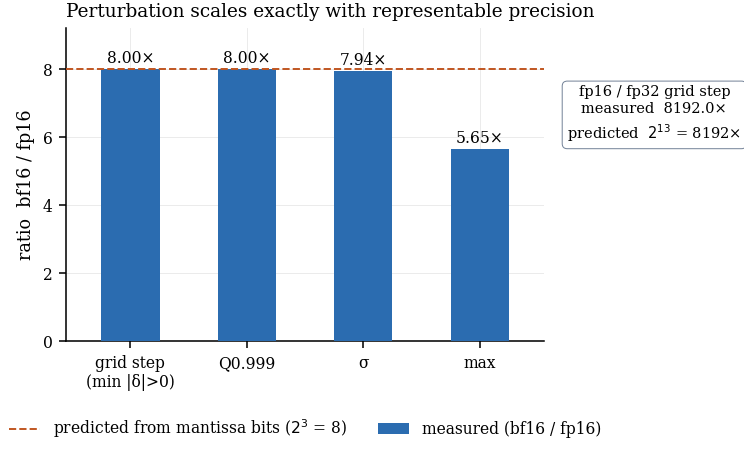

saved fig2_precision_scaling.pdf / .png


In [ ]:
import matplotlib as mpl, matplotlib.pyplot as plt, numpy as np

mpl.rcParams.update({
    "font.family": "serif", "font.size": 9, "axes.labelsize": 9,
    "axes.titlesize": 9.5, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5,
    "figure.dpi": 140, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
})
C = {"a": "#2b6cb0", "b": "#c05621", "g": "#718096"}

stats = ["grid step\n(min |δ|>0)", "Q0.999", "σ", "max"]
meas  = [8.00, 8.00, 7.94, 5.65]
x = np.arange(4)

fig, ax = plt.subplots(figsize=(4.4, 2.9))
ax.bar(x, meas, width=0.5, color=C["a"], label="measured (bf16 / fp16)", zorder=3)
ax.axhline(8, ls="--", lw=1, color=C["b"], zorder=4,
           label="predicted from mantissa bits ($2^3$ = 8)")
for i, v in enumerate(meas):
    ax.text(i, v + 0.18, f"{v:.2f}×", ha="center", fontsize=8, zorder=5)

# note sits in the empty space above the shortest bar
ax.text(4.5, 7.55,
        "fp16 / fp32 grid step\nmeasured  8192.0×\npredicted  $2^{13}$ = 8192×",
        fontsize=7.5, ha="center", va="top", linespacing=1.35, zorder=5,
        bbox=dict(fc="white", ec=C["g"], lw=0.5, boxstyle="round,pad=0.35"))

ax.set_xticks(x); ax.set_xticklabels(stats)
ax.set_ylabel("ratio  bf16 / fp16")
ax.set_ylim(0, 9.2); ax.set_xlim(-0.55, 3.55)
ax.set_title("Perturbation scales exactly with representable precision", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=2, frameon=False)

for ext in ("pdf", "png"):
    fig.savefig(f"fig2_precision_scaling.{ext}")
plt.show(); print("saved fig2_precision_scaling.pdf / .png")

## Predictor probe, FAILED. `output_attentions` silently unsupported under SDPA

**Kept because the failure is a trap worth documenting.**

**Intent.** Test four further candidate predictors of the perturbation scale:
distribution entropy, near-tie count, attention entropy and activation norm.

**What happened.** The model loaded with PyTorch's default SDPA attention
implementation, under which `output_attentions=True` does not raise — it
returns an **empty tuple**. The attention-entropy predictor therefore had no
data, and the cell produced no results.

The warning is in the output and is easy to scroll past:

> `sdpa` attention does not support `output_attentions=True`. Please set your
> attention to `eager` if you want any of these features.

**Fix.** Load with `attn_implementation="eager"` — see the next cell.


In [ ]:
!pip install -q transformers datasets accelerate

import torch, numpy as np, gc
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset
from scipy import stats

MODEL, SEQ, N_SEQ, BATCH, TOPK, KNEAR = "Qwen/Qwen2.5-0.5B", 256, 96, 32, 50, 1.0
print(torch.cuda.get_device_name(0))

tok = AutoTokenizer.from_pretrained(MODEL)
dv  = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="validation")
ids = tok("\n\n".join(t for t in dv["text"] if len(t.strip())>200),
          return_tensors="pt").input_ids[0][:N_SEQ*SEQ]
S = ids.view(N_SEQ, SEQ).cuda()
m = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16,
                                         device_map="cuda").eval()

# ---- pass A: batch 1, collect predictors -------------------------------
I, A, ENT, NEAR, ATT, HN = [], [], [], [], [], []
with torch.no_grad():
    for i in range(N_SEQ):
        o = m(S[i:i+1], output_attentions=True, output_hidden_states=True)
        lg = o.logits[0].float()
        v, ix = lg.topk(TOPK, -1)
        I.append(ix[:, :5].cpu()); A.append(v[:, :5].cpu())
        p = torch.softmax(lg, -1)
        ENT.append((-(p*torch.log(p+1e-12)).sum(-1)).cpu())          # full-dist entropy
        NEAR.append((lg >= (v[:, :1] - KNEAR)).sum(-1).float().cpu())# near-ties within 1.0
        a = o.attentions[-1][0].mean(0)                               # last layer, head-mean
        ATT.append((-(a*torch.log(a+1e-12)).sum(-1)).cpu())           # attention entropy
        HN.append(o.hidden_states[-1][0].float().norm(dim=-1).cpu())
        del o, lg, p, a
    I, A = torch.stack(I), torch.stack(A)
    gA = (A[...,0]-A[...,1]).numpy()[:, :-1]
    # ---- pass B: batched
    B = []
    for s in range(0, N_SEQ, BATCH):
        lg = m(S[s:s+BATCH]).logits
        B.append(lg.gather(-1, I[s:s+BATCH].cuda()).float().cpu()); del lg
    gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:, :-1]
    # ---- control
    C = []
    for i in range(32):
        lg = m(S[i:i+1]).logits[0]
        C.append(lg.gather(-1, I[i].cuda()).float().cpu()); del lg
    gC = (torch.stack(C)[...,0]-torch.stack(C)[...,1]).numpy()[:, :-1]

d = np.abs(gB - gA)
ctrl = int((gC < 0).sum())
P = {"entropy":      torch.stack(ENT).numpy()[:, :-1],
     "near_ties":    torch.stack(NEAR).numpy()[:, :-1],
     "attn_entropy": torch.stack(ATT).numpy()[:, :-1],
     "act_norm":     torch.stack(HN).numpy()[:, :-1]}
del m; gc.collect(); torch.cuda.empty_cache()

print(f"\ncontrol flips = {ctrl}   (must be 0)")
print(f"n = {d.size}   sigma = {d.std():.5f}   nonzero = {100*(d>0).mean():.1f}%\n")

print(f"{'predictor':>14} {'lowest decile':>14} {'highest decile':>15} {'ratio':>7} "
      f"{'Spearman':>9} {'p':>10}")
print("-"*76)
for name, X in P.items():
    x, y = X.ravel(), d.ravel()
    lo, hi = np.quantile(x, 0.1), np.quantile(x, 0.9)
    s_lo, s_hi = y[x <= lo].std(), y[x >= hi].std()
    r = stats.spearmanr(x, y)
    print(f"{name:>14} {s_lo:>14.5f} {s_hi:>15.5f} {s_hi/max(s_lo,1e-12):>7.2f} "
          f"{r.statistic:>+9.4f} {r.pvalue:>10.2e}")

print("\n  ratio > 1.3 AND |rho| > 0.05  -> worth a second look")
print("  otherwise                     -> flat, like the five axes already tested")
print("  (act_norm is the known-flat control: it should come back ~0.7-1.0)")

NVIDIA L4


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (248003 > 131072). Running this sequence through the model will result in indexing errors


[transformers] `sdpa` attention does not support `output_attentions=True`. Please set your attention to `eager` if you want any of these features.


IndexError: tuple index out of range

## Predictor probe, eager attention — four more predictors, all null

**Setup.** Qwen2.5-0.5B, bf16, `attn_implementation="eager"`, `N_SEQ=96`,
`BATCH=32`, `TOPK=50`, near-tie window `KNEAR=1.0`. n = 24,480 steps.
`control flips = 0` confirms the unbatched-vs-unbatched control is clean.

**Precision note.** Eager attention gives σ = 0.07525 with 55.2% nonzero,
against SDPA's σ = 0.0837 and ~50% nonzero from Run 15. The attention
implementation itself changes the perturbation, so these four rows are not
interchangeable with the SDPA-measured ones.

**Decision rule.** Ratio > 1.3 **and** |ρ| > 0.05.
Otherwise flat, like the five axes already tested. `act_norm` is the known-flat
control.

**Result.**

| predictor | low decile | high decile | ratio | Spearman ρ | p |
|---|---|---|---|---|---|
| entropy | 0.09312 | 0.06920 | 0.74 | −0.0603 | 3.43e−21 |
| near_ties | 0.08079 | 0.06545 | 0.81 | −0.0709 | 1.27e−28 |
| attn_entropy | 0.07943 | 0.07456 | 0.94 | +0.0055 | 3.89e−01 |
| act_norm | 0.09148 | 0.06051 | 0.66 | −0.0731 | 2.46e−30 |

**Reading.** No ratio clears 1.3, so no predictor passes. Three are
statistically significant and practically irrelevant — at n = 24,480 a ρ of
−0.06 reaches p = 1e−21 while explaining almost nothing. The three that
correlate correlate with *each other*: uncertain steps have higher entropy,
more near-ties and smaller activation norms. They are proxies for model
confidence, not for anything mechanical in the arithmetic.

**And the sign is wrong for the obvious application.** The correlations are
*negative*, meaning uncertain steps carry *smaller* perturbations. A per-step
margin derived from these signals would widen the margin where the model is
already confident — which is precisely where flips never happen.

`attn_entropy` is the cleanest null: ratio 0.94, ρ = +0.006, p = 0.39 despite
24,480 samples. It was the most physically motivated candidate of the set,
since diffuse attention sums more terms per output position.

**Conclusion.** σ is constant for a given model, precision and hardware. No
conditional noise model is warranted. Interactions between axes were not
tested.


In [ ]:
!pip install -q transformers datasets accelerate

import torch, numpy as np, gc
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset
from scipy import stats

MODEL, SEQ, N_SEQ, BATCH, TOPK, KNEAR = "Qwen/Qwen2.5-0.5B", 256, 96, 32, 50, 1.0
print(torch.cuda.get_device_name(0))

tok = AutoTokenizer.from_pretrained(MODEL)
dv  = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="validation")
ids = tok("\n\n".join(t for t in dv["text"] if len(t.strip())>200),
          return_tensors="pt").input_ids[0][:N_SEQ*SEQ]
S = ids.view(N_SEQ, SEQ).cuda()

m = AutoModelForCausalLM.from_pretrained(
        MODEL, dtype=torch.bfloat16, device_map="cuda",
        attn_implementation="eager").eval()          # <-- the fix
print("attn impl:", m.config._attn_implementation)

I, A, ENT, NEAR, ATT, HN = [], [], [], [], [], []
with torch.no_grad():
    for i in range(N_SEQ):
        o = m(S[i:i+1], output_attentions=True, output_hidden_states=True)
        assert len(o.attentions) > 0, "attentions still empty"
        lg = o.logits[0].float()
        v, ix = lg.topk(TOPK, -1)
        I.append(ix[:, :5].cpu()); A.append(v[:, :5].cpu())
        p = torch.softmax(lg, -1)
        ENT.append((-(p*torch.log(p+1e-12)).sum(-1)).cpu())
        NEAR.append((lg >= (v[:, :1] - KNEAR)).sum(-1).float().cpu())
        a = o.attentions[-1][0].float().mean(0)
        ATT.append((-(a*torch.log(a+1e-12)).sum(-1)).cpu())
        HN.append(o.hidden_states[-1][0].float().norm(dim=-1).cpu())
        del o, lg, p, a, v, ix
        if (i+1) % 32 == 0:
            print(f"  {i+1}/{N_SEQ}"); torch.cuda.empty_cache()
    I, A = torch.stack(I), torch.stack(A)
    gA = (A[...,0]-A[...,1]).numpy()[:, :-1]
    B = []
    for s in range(0, N_SEQ, BATCH):
        lg = m(S[s:s+BATCH]).logits
        B.append(lg.gather(-1, I[s:s+BATCH].cuda()).float().cpu()); del lg
    gB = (torch.cat(B)[...,0]-torch.cat(B)[...,1]).numpy()[:, :-1]
    C = []
    for i in range(32):
        lg = m(S[i:i+1]).logits[0]
        C.append(lg.gather(-1, I[i].cuda()).float().cpu()); del lg
    gC = (torch.stack(C)[...,0]-torch.stack(C)[...,1]).numpy()[:, :-1]

d = np.abs(gB - gA); ctrl = int((gC < 0).sum())
P = {"entropy":      torch.stack(ENT).numpy()[:, :-1],
     "near_ties":    torch.stack(NEAR).numpy()[:, :-1],
     "attn_entropy": torch.stack(ATT).numpy()[:, :-1],
     "act_norm":     torch.stack(HN).numpy()[:, :-1]}
del m; gc.collect(); torch.cuda.empty_cache()

print(f"\ncontrol flips = {ctrl}   (must be 0)")
print(f"n = {d.size}   sigma = {d.std():.5f}   nonzero = {100*(d>0).mean():.1f}%")
print(f"(SDPA reference from Run 15: sigma = 0.0837, ~50% nonzero)\n")

print(f"{'predictor':>14} {'low decile':>12} {'high decile':>12} {'ratio':>7} "
      f"{'Spearman':>9} {'p':>10}")
print("-"*70)
for name, X in P.items():
    x, y = X.ravel(), d.ravel()
    lo, hi = np.quantile(x, 0.1), np.quantile(x, 0.9)
    s_lo, s_hi = y[x <= lo].std(), y[x >= hi].std()
    r = stats.spearmanr(x, y)
    print(f"{name:>14} {s_lo:>12.5f} {s_hi:>12.5f} {s_hi/max(s_lo,1e-12):>7.2f} "
          f"{r.statistic:>+9.4f} {r.pvalue:>10.2e}")

print("\n  ratio > 1.3 AND |rho| > 0.05 -> worth a second look")
print("  otherwise                    -> flat, like the five axes already tested")
print("  act_norm is the known-flat control (expect ~0.7-1.0)")

NVIDIA L4


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (248003 > 131072). Running this sequence through the model will result in indexing errors


attn impl: eager
  32/96
  64/96
  96/96

control flips = 0   (must be 0)
n = 24480   sigma = 0.07525   nonzero = 55.2%
(SDPA reference from Run 15: sigma = 0.0837, ~50% nonzero)

     predictor   low decile  high decile   ratio  Spearman          p
----------------------------------------------------------------------
       entropy      0.09312      0.06920    0.74   -0.0603   3.43e-21
     near_ties      0.08079      0.06545    0.81   -0.0709   1.27e-28
  attn_entropy      0.07943      0.07456    0.94   +0.0055   3.89e-01
      act_norm      0.09148      0.06051    0.66   -0.0731   2.46e-30

  ratio > 1.3 AND |rho| > 0.05 -> worth a second look
  otherwise                    -> flat, like the five axes already tested
  act_norm is the known-flat control (expect ~0.7-1.0)
